# ROBT613 midterm - Artifacts as confounds in motor-imagery decoding

**Authors:** Chidiadi Bethel Mba, Sungkar Bolat, Beibars Ybraiakhyn, Ramazan Zypayev

Dataset: BNCI2014-001 (BCI Competition IV 2a) via MOABB. Run top to bottom on a fresh Colab CPU runtime.
Set `ROBT613_MODE` below to `SMOKE` (1 subject, 1 session) for a quick check or `FULL` (9 subjects, 2 sessions).

Every number in the report is read from `results/tables/`, produced by this notebook.

## 1. Research question and pre-registered hypotheses

**Question.** How much of motor-imagery (MI) decoding performance on dataset 2a comes from ocular/muscular artifacts rather than sensorimotor rhythms, and does artifact removal change *which* features win?

**Why it matters.** The cue in 2a is an arrow (left / right / down / up) shown for 1.25 s at t = 2 s of each trial. Subjects were told to fixate, but an arrow cue invites a reflexive saccade or gaze shift in the cued direction, and MI effort invites jaw/neck tension. Any decoder that picks this up works in the lab and fails on a locked-in user who cannot move their eyes — or inflates reported accuracies. 2a is the most used MI benchmark, so a measurable confound there matters for the field.

**Hypotheses (write the predictions before running the full pipeline):**

- **H1 — EOG carries class information.** A decoder trained on the 3 EOG channels alone decodes left vs right hand above the permutation chance level in a majority of subjects. (If H1 is false, that is a clean negative result and still earns full marks — report it as such.)
- **H2 — Cleaning lowers EEG decoding where H1 holds.** Removing ocular activity from EEG (EOG regression; ICA) reduces mu/beta decoding AUC, and the per-subject drop correlates positively with that subject's EOG-only AUC.
- **H3 — Cleaning changes which features win.** Before cleaning, discriminative weight is concentrated on frontal channels and low-frequency (<4 Hz) or high-frequency (>30 Hz) bands; after cleaning it shifts to central channels (C3, Cz, C4) in mu (8–13 Hz) and beta (13–30 Hz). A decoder restricted to the "physiological" feature set (C3/Cz/C4, 8–30 Hz) loses less from cleaning than one restricted to the "artifact-prone" set (frontal/temporal, <4 Hz and >30 Hz).

**Primary task:** left hand vs right hand (binary; lateral cue → lateral eye movement is the most plausible confound). **Secondary:** 4-class (left, right, feet, tongue) with multinomial logistic regression, reported as balanced accuracy and macro one-vs-rest AUC. Tongue imagery is the most EMG-prone class — note this in the interpretation.

**Decision rules (pre-specified):**
- H1 supported if group-level EOG-only AUC exceeds 0.5 by a one-sided Wilcoxon test across the 9 subjects (p < 0.05) **and** at least 5/9 subjects exceed the 95th percentile of their own permutation null.
- H2 supported if paired Wilcoxon (no-cleaning vs cleaning) across subjects gives p < 0.05 and Spearman ρ(EOG-only AUC, AUC drop) > 0.
- H3 supported if the weight-map centroid moves toward central channels and the artifact-prone feature set shows a larger AUC drop than the physiological set (paired Wilcoxon on the drops).
- With n = 9, state the power limitation explicitly in the report.


In [1]:
# Environment. Pins match the ROBT613 course notebooks. Other packages = Colab defaults (printed at the end).
import sys, subprocess, os, time
T_START = time.time()
if 'google.colab' in sys.modules:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'mne==1.13.2', 'moabb==1.7.2'])
os.environ.setdefault('ROBT613_MODE', 'FULL')
os.makedirs('src', exist_ok=True)
print('MODE', os.environ['ROBT613_MODE'])

MODE FULL


## Shared code
The project modules are written to disk so that each stage below imports the same functions.

In [2]:
%%writefile config.py
"""Project-wide configuration: run mode, paths, seeds and dataset constants.

Every constant tagged ``verified: data`` was checked by loading the data
(see scripts/01_audit.py). Constants tagged ``source: Brunner2008`` come from
the dataset description (report/refs/Brunner2008_desc_2a.pdf).
"""
from __future__ import annotations

import os
from pathlib import Path

# ---------------------------------------------------------------- run mode
# SMOKE = 1 subject, 1 session (fast check). FULL = all 9 subjects, both sessions.
MODE: str = os.environ.get("ROBT613_MODE", "SMOKE").upper()
CONFIGS: dict[str, dict] = {
    # n_permutations: rows used by the H1 decision rule (eog_only, both classifiers, every analysis);
    # n_permutations_other: every other row (chance reported, not used in a decision rule).
    # Reduced from 100 for the 30 min Colab budget, as PLAN.md Phase 8 allows (NOTES.md).
    "SMOKE": {"subjects": [1], "sessions": ["0train"], "n_permutations": 20, "n_permutations_other": 10},
    "FULL": {"subjects": list(range(1, 10)), "sessions": ["0train", "1test"], "n_permutations": 100,
             "n_permutations_other": 30},
}
CFG: dict = CONFIGS[MODE]

# ---------------------------------------------------------------- paths
ROOT: Path = Path(__file__).resolve().parent
RESULTS: Path = ROOT / "results"
TABLES: Path = RESULTS / "tables"
FIGURES: Path = RESULTS / "figures"
CACHE: Path = RESULTS / "cache"
for _p in (TABLES, FIGURES, CACHE):
    _p.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------- reproducibility
SEED: int = 42

# ---------------------------------------------------------------- dataset facts
SFREQ: float = 250.0                     # verified: data; source: Brunner2008
N_EEG: int = 22                          # verified: data; source: Brunner2008
N_EOG: int = 3                           # verified: data; source: Brunner2008
EOG_CHANNELS: list[str] = ["EOG1", "EOG2", "EOG3"]  # verified: data (names)
# EOG positions from Brunner2008 Fig. 3 (right), read from the rendered figure: #1 at the
# outer canthus on the viewer's right, #2 above the nasion between the eyebrows, #3 at the
# outer canthus on the viewer's left. Assuming the face is drawn facing the reader:
# EOG1 = subject's LEFT outer canthus, EOG2 = glabella, EOG3 = subject's RIGHT outer canthus.
# Consistent with data: blinks are largest on EOG2 (fig_1a, fig_3b).
# HEOG = EOG1 - EOG3 (> 0 when the cornea moves toward EOG1, i.e. gaze to the subject's left,
# under that assumption). VEOG = EOG2 - mean(EOG1, EOG3) (no infra-orbital electrode).
# Both are reference-free (the shared mastoid reference cancels).
EOG_POSITIONS: dict[str, str] = {"EOG1": "left outer canthus", "EOG2": "glabella", "EOG3": "right outer canthus"}
EOG_HEOG: tuple[str, str] = ("EOG1", "EOG3")
EOG_VEOG: tuple[str, tuple[str, str]] = ("EOG2", ("EOG1", "EOG3"))
REFERENCE: str = "left mastoid"          # source: Brunner2008
GROUND: str = "right mastoid"            # source: Brunner2008
ACQ_BANDPASS_HZ: tuple[float, float] = (0.5, 100.0)  # source: Brunner2008
ACQ_NOTCH_HZ: float = 50.0               # source: Brunner2008 ("additional 50 Hz notch")
SESSIONS: list[str] = ["0train", "1test"]  # verified: data (MOABB keys)
SESSION_MAT_SUFFIX: dict[str, str] = {"0train": "T", "1test": "E"}  # source: Brunner2008 Table 1
N_RUNS_PER_SESSION: int = 6              # verified: data
N_TRIALS_PER_RUN: int = 48               # verified: data; source: Brunner2008

# ---------------------------------------------------------------- event timing
# Trial timing (source: Brunner2008): fixation cross at t=0, cue arrow at t=2 s
# for 1.25 s, MI until t=6 s.
# MOABB puts the class annotation at STI trigger + interval[0] = trial start + 2 s,
# i.e. at CUE ONSET (verified: data, scripts/01_audit.py checks a 500-sample shift
# for every trial). So epochs locked to the annotation are cue-locked.
# Confirmed in Phase 4: the class-dependent HEOG deflection starts 0.19-0.25 s after the
# annotation and peaks at 0.36 s, with nothing before 0 (neuro_eog_latency.csv).
T_TRIAL_START_TO_CUE: float = 2.0        # source: Brunner2008; verified: data
ANNOT_IS_CUE_ONSET: bool = True          # verified: data (sample shift + EOG latency)
CUE_DURATION: float = 1.25               # source: Brunner2008
MI_END_AFTER_CUE: float = 4.0            # source: Brunner2008 (t=6 s)
EPOCH_TMIN: float = -1.0                 # relative to cue (fixation baseline)
EPOCH_TMAX: float = 4.0
BASELINE: tuple[float, float] = (-1.0, 0.0)
MI_WINDOW: tuple[float, float] = (0.5, 2.5)  # relative to cue, for band power

EVENT_ID: dict[str, int] = {"feet": 1, "left_hand": 2, "right_hand": 3, "tongue": 4}  # verified: data
CLASSES_4: list[str] = ["left_hand", "right_hand", "feet", "tongue"]
CLASSES_LR: list[str] = ["left_hand", "right_hand"]

# ---------------------------------------------------------------- channel sets
# 2a has no Fp, T7/T8 or P7/P8 electrodes (verified: data). See NOTES.md.
PHYSIO_CHANNELS: list[str] = ["C3", "Cz", "C4", "FC3", "FC4", "CP3", "CP4"]
ARTIFACT_PRONE_CHANNELS: list[str] = ["Fz", "FC1", "FC2", "FC3", "FC4", "C5", "C6"]
CENTRAL_CHANNELS: list[str] = ["C3", "C1", "Cz", "C2", "C4"]

BANDS: dict[str, tuple[float, float]] = {
    "delta": (1.0, 4.0), "theta": (4.0, 8.0), "mu": (8.0, 13.0),
    "beta": (13.0, 30.0), "high": (30.0, 45.0),
}

# ---------------------------------------------------------------- cleaning (Phase 3)
CONDITIONS: list[str] = ["none", "eog_reg", "ica"]
# Where EOG regression and ICA are fitted. "calibration" = the session's EOG calibration
# runs (eyes open / closed / movements, read from the .mat), applied to the MI runs.
# This keeps every MI trial out of the cleaning fit (course notebook 04 "fit on
# calibration"). "session" = fit on the 6 MI runs themselves (PLAN.md original). See NOTES.md.
CLEAN_FIT_ON: str = "calibration"
# 20 components: CAR leaves rank 21. n_components=0.99 kept only 9-14 components, and with
# n components the largest reachable z-score is (n-1)/sqrt(n) (2.85 for n=10), so the default
# z=3 rule excluded nothing in 9/18 recordings (see NOTES.md, Phase 3).
ICA_KW: dict = {"n_components": 20, "method": "fastica", "max_iter": "auto", "random_state": SEED}
ICA_DECIM: int = 1                       # A04T calibration is only 80 s; fits take ~2 s each
# Exclude a component if |Pearson r| with any EOG channel on the fitting data >= threshold
# (mne ICA.find_bads_eog, measure="correlation"). Chosen from fig_3f.
ICA_EOG_MEASURE: str = "correlation"
ICA_EOG_THRESHOLD: float = 0.5
# Peak-to-peak rejection on EEG channels of the `none` condition, applied identically to all
# conditions. Set after inspecting fig_3c (see NOTES.md). None = reject nothing.
PTP_REJECT_UV: float | None = None

# ---------------------------------------------------------------- features (Phase 5)
WELCH_NPERSEG: int = 250                 # 1 s segments -> 1 Hz bins; MI window gives 3 segments (50 % overlap)
AMP_WINDOW: tuple[float, float] = (0.0, 1.0)  # s after cue, mean amplitude bins (gaze-shift capture)
AMP_BIN: float = 0.1
FEATURE_SETS: list[str] = ["eog_only", "eeg_all", "eeg_physio", "eeg_artifact_prone"]
TASKS: list[str] = ["left_vs_right", "four_class"]
CLASSIFIERS: list[str] = ["logreg", "slda"]
# 4-class = multinomial logistic regression only (PLAN.md 1); sLDA is the binary robustness check
TASK_CLASSIFIERS: dict[str, list[str]] = {"left_vs_right": ["logreg", "slda"], "four_class": ["logreg"]}
N_JOBS: int = int(os.environ.get("ROBT613_NJOBS", "-1"))  # permutations in parallel (Colab CPU = 2)
FRONTAL_AMP_CHANNELS: list[str] = ["Fz", "FC1", "FC2", "FC3", "FC4"]  # exploratory feature set


Writing config.py


In [3]:
%%writefile src/__init__.py
"""Shared analysis code for the ROBT613 artifact-confound project."""


Writing src/__init__.py


In [4]:
%%writefile src/timing.py
"""Wall-time logging to results/timing.csv."""
from __future__ import annotations

import time
from contextlib import contextmanager
from datetime import datetime

import config


@contextmanager
def timed(stage: str):
    """Time a block and append ``timestamp,mode,stage,seconds`` to results/timing.csv."""
    t0 = time.perf_counter()
    yield
    dt = time.perf_counter() - t0
    path = config.RESULTS / "timing.csv"
    new = not path.exists()
    with path.open("a") as f:
        if new:
            f.write("timestamp,mode,stage,seconds\n")
        f.write(f"{datetime.now().isoformat(timespec='seconds')},{config.MODE},{stage},{dt:.1f}\n")
    print(f"[timing] {stage}: {dt:.1f} s")


Writing src/timing.py


In [5]:
%%writefile src/plots.py
"""Shared figure helpers: one style, every figure saved under results/figures/."""
from __future__ import annotations

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt

import config

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})
CMAP_SEQ = "viridis"
CMAP_DIV = "RdBu_r"


def save(fig: plt.Figure, name: str) -> None:
    """Save a figure as PNG and PDF under results/figures/ and close it."""
    for ext in ("png", "pdf"):
        fig.savefig(config.FIGURES / f"{name}.{ext}", bbox_inches="tight")
    plt.close(fig)


Writing src/plots.py


In [6]:
%%writefile src/data.py
"""Data loading and audit for BNCI2014-001 (BCI Competition IV 2a).

MOABB gives the 6 MI runs per session as MNE Raw objects. It drops the EOG
calibration runs and (by default) the expert artifact flags, so both are read
back from the source .mat files that MOABB caches.
"""
from __future__ import annotations

from pathlib import Path

import mne
import numpy as np
import pandas as pd
import scipy.io as sio
from moabb.datasets import BNCI2014_001

import config

# adapted from ROBT613-BCI-Workshop notebook 00 (MOABB loading)


def get_dataset() -> BNCI2014_001:
    """Return the MOABB dataset object (artifact flags handled separately)."""
    return BNCI2014_001()


def load_subject(subject: int) -> dict[str, dict[str, mne.io.BaseRaw]]:
    """Load one subject as ``session -> run -> Raw`` (MOABB nested dict)."""
    return get_dataset().get_data(subjects=[subject])[subject]


def mat_path(subject: int, session: str) -> Path:
    """Path of the cached source .mat file for a subject and session."""
    suffix = config.SESSION_MAT_SUFFIX[session]
    for p in get_dataset().data_path(subject):
        if Path(p).name == f"A{subject:02d}{suffix}.mat":
            return Path(p)
    raise FileNotFoundError(f"A{subject:02d}{suffix}.mat not in MOABB cache")


def load_mat_runs(subject: int, session: str) -> list:
    """Read every run struct (calibration + MI) from the source .mat file."""
    m = sio.loadmat(mat_path(subject, session), squeeze_me=True, struct_as_record=False)
    runs = m["data"]
    return list(runs) if isinstance(runs, np.ndarray) else [runs]


def split_mat_runs(runs: list) -> tuple[list, list]:
    """Split .mat runs into (calibration runs without trials, MI runs with trials)."""
    calib = [r for r in runs if np.size(r.trial) == 0]
    mi = [r for r in runs if np.size(r.trial) > 0]
    return calib, mi


def trial_table(subject: int, session: str, runs: dict[str, mne.io.BaseRaw]) -> pd.DataFrame:
    """One row per trial: run, cue sample, label and the expert artifact flag.

    MOABB run ``k`` is matched to the ``k``-th .mat run that contains trials.
    The match is checked sample by sample: each annotation must sit exactly
    ``T_TRIAL_START_TO_CUE`` seconds after the .mat trial-start sample.
    """
    _, mi_runs = split_mat_runs(load_mat_runs(subject, session))
    if len(mi_runs) != len(runs):
        raise ValueError(f"S{subject} {session}: {len(mi_runs)} .mat MI runs vs {len(runs)} MOABB runs")
    shift = int(round(config.T_TRIAL_START_TO_CUE * config.SFREQ))
    rows = []
    for run_idx, (run_key, raw) in enumerate(sorted(runs.items(), key=lambda kv: int(kv[0]))):
        mr = mi_runs[run_idx]
        events, event_id = mne.events_from_annotations(raw, event_id=config.EVENT_ID, verbose=False)
        trial_start0 = np.asarray(mr.trial).ravel() - 1  # .mat samples are 1-based
        if not np.array_equal(events[:, 0] - shift, trial_start0):
            raise ValueError(f"S{subject} {session} run {run_key}: annotations are not at trial start + 2 s")
        mat_classes = [str(c).replace(" ", "_") for c in mr.classes]
        mat_labels = [mat_classes[int(y) - 1] for y in np.asarray(mr.y).ravel()]
        inv = {v: k for k, v in event_id.items()}
        moabb_labels = [inv[c] for c in events[:, 2]]
        if mat_labels != moabb_labels:
            raise ValueError(f"S{subject} {session} run {run_key}: labels differ between .mat and MOABB")
        artifacts = np.asarray(mr.artifacts).ravel().astype(int)
        for i, (samp, lab, art) in enumerate(zip(events[:, 0], moabb_labels, artifacts)):
            rows.append({"subject": subject, "session": session, "run": int(run_key),
                         "trial_in_run": i, "cue_sample": int(samp), "cue_time_s": samp / config.SFREQ,
                         "label": lab, "expert_artifact": int(art)})
    return pd.DataFrame(rows)


def calibration_summary(subject: int, session: str) -> list[dict]:
    """Describe the EOG calibration runs kept in the .mat file (MOABB drops them)."""
    calib, _ = split_mat_runs(load_mat_runs(subject, session))
    return [{"subject": subject, "session": session, "calib_run": i,
             "n_samples": int(r.X.shape[0]), "duration_s": r.X.shape[0] / float(r.fs)}
            for i, r in enumerate(calib)]


def load_calibration_raws(subject: int, session: str,
                          ref: mne.io.BaseRaw | None = None) -> list[mne.io.RawArray]:
    """Return the EOG calibration runs as Raw objects (Volts, MOABB channel names).

    ``ref`` is any MOABB MI run of the subject; it supplies channel names, types and
    montage (loaded if not given). The .mat stores µV, MOABB rescales to V the same way.
    """
    calib, _ = split_mat_runs(load_mat_runs(subject, session))
    if ref is None:
        ref = load_subject(subject)[session]["0"]
    names = [c for c in ref.ch_names if c != "STI"]
    types = [t for c, t in zip(ref.ch_names, ref.get_channel_types()) if c != "STI"]
    out = []
    for r in calib:
        info = mne.create_info(names, float(r.fs), types)
        raw = mne.io.RawArray(np.asarray(r.X, float).T * 1e-6, info, verbose=False)
        raw.set_montage(ref.get_montage())
        out.append(raw)
    return out


def recording_summary(subject: int, session: str, runs: dict[str, mne.io.BaseRaw],
                      trials: pd.DataFrame) -> dict:
    """One audit row per subject x session, every field read from the data."""
    raw0 = runs["0"]
    types = raw0.get_channel_types()
    eeg_std = float(np.median([r.get_data(picks="eeg").std() for r in runs.values()]))
    eog_std = float(np.median([r.get_data(picks="eog").std() for r in runs.values()]))
    calib = calibration_summary(subject, session)
    return {
        "subject": subject, "session": session, "n_runs": len(runs),
        "n_eeg": types.count("eeg"), "n_eog": types.count("eog"), "n_stim": types.count("stim"),
        "sfreq": raw0.info["sfreq"],
        "duration_s": float(sum(r.n_times / r.info["sfreq"] for r in runs.values())),
        "n_trials": len(trials),
        "n_expert_artifact": int(trials["expert_artifact"].sum()),
        "eeg_std_V": eeg_std, "eog_std_V": eog_std,
        "units_ok": bool(1e-7 < eeg_std < 1e-3),
        "montage_set": raw0.get_montage() is not None,
        "n_calib_runs": len(calib),
        "calib_durations_s": ";".join(f"{c['duration_s']:.1f}" for c in calib),
        "annot_at_cue": True,  # trial_table raises otherwise
        "reference": f"{config.REFERENCE} (source: Brunner2008)",
        "acq_filter": f"{config.ACQ_BANDPASS_HZ[0]}-{config.ACQ_BANDPASS_HZ[1]} Hz + {config.ACQ_NOTCH_HZ} Hz notch (source: Brunner2008)",
    }


Writing src/data.py


In [7]:
%%writefile src/preprocess.py
"""Preprocessing: session concatenation, band-pass filtering, spectral QC.

Phase 3 adds CAR, EOG regression, ICA, epoching and rejection to this module.
"""
from __future__ import annotations

import mne
import numpy as np
import pandas as pd

import config

# adapted from ROBT613-BCI-Workshop notebook 03 (filtering)

# Analysis band. h_trans_bandwidth is set explicitly: MNE's default for a 45 Hz
# edge is 11.25 Hz (-6 dB at 50.6 Hz, only -4.5 dB at 50 Hz). 5 Hz puts 50 Hz in
# the stop band (-50 dB) at the same filter length. See fig_2b.
FILTER_KW: dict = {"l_freq": 1.0, "h_freq": 45.0, "l_trans_bandwidth": "auto",
                   "h_trans_bandwidth": 5.0, "method": "fir", "fir_design": "firwin",
                   "phase": "zero", "picks": ["eeg", "eog"]}
WELCH_KW: dict = {"method": "welch", "n_fft": 500, "n_overlap": 250, "fmin": 0.0, "fmax": 125.0}


def concat_session(runs: dict[str, mne.io.BaseRaw]) -> mne.io.BaseRaw:
    """Concatenate the 6 MI runs of a session in run order.

    MNE inserts BAD boundary / EDGE annotations at the joins, so filters are applied
    per run segment and no epoch can straddle two runs. The run index of each trial
    is recovered from ``data.trial_table`` (cue samples are per run).
    """
    ordered = [runs[k].copy() for k in sorted(runs, key=int)]
    return mne.concatenate_raws(ordered, verbose=False)


def bandpass(raw: mne.io.BaseRaw) -> mne.io.BaseRaw:
    """Return a copy band-passed with ``FILTER_KW`` (EEG and EOG channels)."""
    return raw.copy().filter(**FILTER_KW, verbose=False)


def filter_description(sfreq: float = config.SFREQ) -> dict:
    """Design the analysis filter once and return its parameters and key gains (dB)."""
    kw = {k: v for k, v in FILTER_KW.items() if k not in ("picks", "method")}
    h = mne.filter.create_filter(None, sfreq, verbose=False, **kw)
    freqs = np.fft.rfftfreq(16384, 1 / sfreq)
    gain = 20 * np.log10(np.abs(np.fft.rfft(h, 16384)) + 1e-12)
    out = {"n_taps": len(h), "length_s": len(h) / sfreq,
           "l_freq": FILTER_KW["l_freq"], "h_freq": FILTER_KW["h_freq"],
           "h_trans_bandwidth": FILTER_KW["h_trans_bandwidth"]}
    for f in (0.5, 1.0, 45.0, 47.5, 50.0):
        out[f"gain_dB_{f:g}Hz"] = float(gain[np.argmin(np.abs(freqs - f))])
    # same band with MNE's default upper transition, for comparison (why h_trans_bandwidth is set)
    hd = mne.filter.create_filter(None, sfreq, verbose=False, **{**kw, "h_trans_bandwidth": "auto"})
    gd = 20 * np.log10(np.abs(np.fft.rfft(hd, 16384)) + 1e-12)
    out["gain_dB_50Hz_mne_default"] = float(gd[np.argmin(np.abs(freqs - 50.0))])
    return out


def psd(raw: mne.io.BaseRaw, picks: str | list[str]) -> tuple[np.ndarray, np.ndarray]:
    """Welch PSD (V^2/Hz), 0.5 Hz resolution, skipping BAD/EDGE segments."""
    sp = raw.compute_psd(picks=picks, reject_by_annotation=True, verbose=False, **WELCH_KW)
    return sp.get_data(picks="all"), sp.freqs


def spectral_qc(raw: mne.io.BaseRaw) -> dict:
    """Line-noise and drift metrics from the unfiltered PSD, EEG and EOG separately.

    line_50Hz_dB : 50 Hz bin over the median of 40-48 and 52-60 Hz bins (mean over channels).
    drift_dB     : median power below 1 Hz over median power at 1-4 Hz.
    """
    out = {}
    for kind in ("eeg", "eog"):
        p, f = psd(raw, kind)
        p = 10 * np.log10(p)
        flank = ((f >= 40) & (f <= 48)) | ((f >= 52) & (f <= 60))
        line = p[:, np.argmin(np.abs(f - 50.0))] - np.median(p[:, flank], axis=1)
        drift = np.median(p[:, (f > 0) & (f < 1)], axis=1) - np.median(p[:, (f >= 1) & (f <= 4)], axis=1)
        out[f"{kind}_line_50Hz_dB_mean"] = float(line.mean())
        out[f"{kind}_line_50Hz_dB_max"] = float(line.max())
        out[f"{kind}_drift_dB_median"] = float(np.median(drift))
        if kind == "eeg":
            out.update(high_band_peak(p, f, raw.copy().pick("eeg").ch_names))
    return out


def high_band_peak(p_db: np.ndarray, f: np.ndarray, ch_names: list[str],
                   fit: tuple[float, float] = (26.0, 44.0)) -> dict:
    """Largest narrowband excess in the 'high' feature band, per channel.

    A line is fitted to log10(f) vs dB over ``fit`` (the 1/f trend) for each channel;
    the peak is the largest residual inside config.BANDS['high'] (30-45 Hz).
    """
    m = (f >= fit[0]) & (f <= fit[1])
    x = np.log10(f[m])
    lo, hi = config.BANDS["high"]
    inband = (f[m] >= lo) & (f[m] <= hi)
    best = (np.nan, "", -np.inf)
    for ch, row in zip(ch_names, p_db):
        resid = row[m] - np.polyval(np.polyfit(x, row[m], 1), x)
        i = int(np.argmax(np.where(inband, resid, -np.inf)))
        if resid[i] > best[2]:
            best = (float(f[m][i]), ch, float(resid[i]))
    return {"eeg_high_peak_Hz": best[0], "eeg_high_peak_ch": best[1], "eeg_high_peak_dB": best[2]}


# ====================================================================== Phase 3
# adapted from ROBT613-BCI-Workshop notebook 04 (CAR, regression, ICA fitted on calibration)
# and notebook 05 (cue-locked epochs, peak-to-peak rejection)


def car(raw: mne.io.BaseRaw) -> mne.io.BaseRaw:
    """Common average reference over the 22 EEG channels (in place, EOG untouched)."""
    raw.set_eeg_reference("average", ch_type="eeg", projection=False, verbose=False)
    return raw


def prepare(raw: mne.io.BaseRaw) -> mne.io.BaseRaw:
    """The `none` pipeline: 1-45 Hz band-pass then CAR. Returns a new object."""
    return car(bandpass(raw))


def cleaning_fit_raw(subject: int, session: str, mi_raw: mne.io.BaseRaw,
                     ref_run: mne.io.BaseRaw) -> mne.io.BaseRaw:
    """Prepared data the cleaning models are fitted on (see config.CLEAN_FIT_ON)."""
    from src import data
    if config.CLEAN_FIT_ON == "session":
        return mi_raw
    if config.CLEAN_FIT_ON != "calibration":
        raise ValueError(config.CLEAN_FIT_ON)
    calib = [prepare(r) for r in data.load_calibration_raws(subject, session, ref_run)]
    return mne.concatenate_raws(calib, verbose=False) if len(calib) > 1 else calib[0]


def fit_eog_regression(fit_raw: mne.io.BaseRaw) -> mne.preprocessing.EOGRegression:
    """Least-squares regression of the 3 EOG channels out of every EEG channel."""
    return mne.preprocessing.EOGRegression(picks="eeg", picks_artifact="eog").fit(fit_raw)


def fit_ica(fit_raw: mne.io.BaseRaw) -> tuple[mne.preprocessing.ICA, list[int], np.ndarray]:
    """FastICA on EEG; components with |r| >= threshold to any EOG channel are excluded.

    Returns the ICA (with ``exclude`` set), the excluded indices and the |score| matrix
    (n_eog_channels x n_components) used for the decision.
    """
    ica = mne.preprocessing.ICA(**config.ICA_KW)
    ica.fit(fit_raw, picks="eeg", decim=config.ICA_DECIM, verbose=False)
    bads, scores = ica.find_bads_eog(fit_raw, ch_name=config.EOG_CHANNELS,
                                     measure=config.ICA_EOG_MEASURE,
                                     threshold=config.ICA_EOG_THRESHOLD, verbose=False)
    ica.exclude = sorted(int(b) for b in bads)
    return ica, ica.exclude, np.abs(np.atleast_2d(scores))


def build_conditions(subject: int, session: str, runs: dict[str, mne.io.BaseRaw],
                     use_cache: bool = True) -> tuple[dict[str, mne.io.BaseRaw], dict]:
    """Return {'none', 'eog_reg', 'ica'} prepared session Raws and a fit-info dict.

    The ICA solution is cached to results/cache/ica/ so later scripts apply the same
    decomposition. EOG regression is closed-form and refitted (deterministic).
    """
    none = prepare(concat_session(runs))
    fit_raw = cleaning_fit_raw(subject, session, none, runs["0"])
    reg = fit_eog_regression(fit_raw)
    eog_reg = reg.apply(none.copy())

    path = config.CACHE / "ica" / f"S{subject:02d}_{session}_{config.CLEAN_FIT_ON}-ica.fif"
    path.parent.mkdir(parents=True, exist_ok=True)
    spath = path.with_suffix(".scores.npy")
    if use_cache and path.exists() and spath.exists():
        ica = mne.preprocessing.read_ica(path, verbose=False)
        scores = np.load(spath)
    else:
        ica, _, scores = fit_ica(fit_raw)
        ica.save(path, overwrite=True, verbose=False)
        np.save(spath, scores)
    ica_raw = ica.apply(none.copy(), verbose=False)

    info = {"fit_on": config.CLEAN_FIT_ON, "fit_duration_s": fit_raw.n_times / fit_raw.info["sfreq"],
            "fit_samples_per_comp2": fit_raw.n_times / config.ICA_DECIM / max(ica.n_components_, 1) ** 2,
            "n_ica_components": int(ica.n_components_), "ica_excluded": [int(k) for k in ica.exclude],
            "ica_eog_scores": scores, "eog_reg_coef_max": float(np.abs(reg.coef_).max()),
            "ica": ica, "fit_raw": fit_raw}
    return {"none": none, "eog_reg": eog_reg, "ica": ica_raw}, info


def make_epochs(raw: mne.io.BaseRaw, trials: pd.DataFrame) -> mne.Epochs:
    """Cue-locked epochs (config.EPOCH_TMIN..TMAX), no baseline, trial table as metadata.

    Annotations sit at cue onset (verified in Phase 1). Raises if any trial is lost at
    a run boundary, so every condition has exactly the trials in ``trials``.
    """
    events, _ = mne.events_from_annotations(raw, event_id=config.EVENT_ID, verbose=False)
    ep = mne.Epochs(raw, events, config.EVENT_ID, config.EPOCH_TMIN, config.EPOCH_TMAX,
                    baseline=None, preload=True, reject_by_annotation=True,
                    picks=["eeg", "eog"], verbose=False)
    if len(ep) != len(trials):
        raise ValueError(f"{len(ep)} epochs vs {len(trials)} trials (lost at a boundary?)")
    inv = {v: k for k, v in config.EVENT_ID.items()}
    if [inv[c] for c in ep.events[:, 2]] != list(trials["label"]):
        raise ValueError("epoch order differs from trial table")
    ep.metadata = trials.reset_index(drop=True)
    return ep


def ptp_uv(epochs: mne.Epochs, picks: str = "eeg") -> np.ndarray:
    """Per-epoch peak-to-peak (µV), max over channels of ``picks``, whole epoch window."""
    x = epochs.get_data(picks=picks)
    return np.ptp(x, axis=-1).max(axis=1) * 1e6


def eog_corr(raw: mne.io.BaseRaw, ch: str = "Fz") -> dict:
    """|Pearson r| between one EEG channel and each EOG channel over the session."""
    x = raw.get_data(picks=[ch] + config.EOG_CHANNELS, reject_by_annotation="omit")
    return {f"absr_{ch}_{e}": float(abs(np.corrcoef(x[0], x[i + 1])[0, 1]))
            for i, e in enumerate(config.EOG_CHANNELS)}


Writing src/preprocess.py


In [8]:
%%writefile src/features.py
"""Per-trial feature extraction and feature-set selection.

All extractors are stateless and per trial (no parameter is learned from other trials), so
computing them once per recording before cross-validation cannot leak information between
folds. Everything learned (StandardScaler, classifier) is fitted inside the CV pipeline.
"""
from __future__ import annotations

import mne
import numpy as np
from scipy.signal import welch

import config

# adapted from ROBT613-BCI-Workshop notebook 06 (Welch log band power) and
# notebook 02 (mean amplitude in time windows)


def log_bandpower(x: np.ndarray, sfreq: float, bands: dict[str, tuple[float, float]] = config.BANDS
                  ) -> np.ndarray:
    """log10 mean Welch PSD (µV²/Hz) per band. x: (n_trials, n_ch, n_times) in V.

    Returns (n_trials, n_ch, n_bands). Band edges are [lo, hi) on 1 Hz bins.
    """
    nper = min(config.WELCH_NPERSEG, x.shape[-1])
    f, p = welch(x * 1e6, fs=sfreq, nperseg=nper, noverlap=nper // 2, axis=-1)
    out = [p[..., (f >= lo) & (f < hi)].mean(-1) for lo, hi in bands.values()]
    return np.log10(np.stack(out, axis=-1))


def window_means(x: np.ndarray, times: np.ndarray, t0: float, t1: float, width: float,
                 baseline: tuple[float, float] = config.BASELINE) -> np.ndarray:
    """Baseline-corrected mean amplitude (µV) in consecutive bins of ``width`` s from t0 to t1.

    x: (n_trials, n_ch, n_times) in V. Returns (n_trials, n_ch, n_bins).
    """
    base = x[..., (times >= baseline[0]) & (times < baseline[1])].mean(-1, keepdims=True)
    y = (x - base) * 1e6
    edges = np.round(np.arange(t0, t1 + 1e-9, width), 6)
    return np.stack([y[..., (times >= a) & (times < b)].mean(-1) for a, b in zip(edges[:-1], edges[1:])], -1)


def epoch_features(epochs: mne.Epochs) -> dict[str, np.ndarray]:
    """All per-trial features of one recording x condition (EEG + EOG channels).

    bp      : log band power in the MI window        (n, n_ch, n_bands)
    bp_base : log band power in the fixation baseline (n, n_ch, n_bands)  [for ERD, Phase 4]
    amp     : mean amplitude, 100 ms bins 0-1 s after cue (n, n_ch, n_bins)
    """
    sf = epochs.info["sfreq"]
    t = epochs.times
    x = epochs.get_data(picks=["eeg", "eog"])
    mi = x[..., (t >= config.MI_WINDOW[0]) & (t < config.MI_WINDOW[1])]
    base = x[..., (t >= config.BASELINE[0]) & (t < config.BASELINE[1])]
    return {"bp": log_bandpower(mi, sf), "bp_base": log_bandpower(base, sf),
            "amp": window_means(x, t, *config.AMP_WINDOW, config.AMP_BIN),
            "ch_names": np.array(epochs.copy().pick(["eeg", "eog"]).ch_names)}


def select(feats: dict[str, np.ndarray], feature_set: str) -> tuple[np.ndarray, list[str]]:
    """Flatten the features of one feature set (PLAN.md Phase 5 table) -> (X, names)."""
    ch = list(feats["ch_names"])
    bands = list(config.BANDS)
    eeg = [c for c in ch if not c.startswith("EOG")]

    def bp(chans: list[str], bnames: list[str]) -> tuple[np.ndarray, list[str]]:
        ci = [ch.index(c) for c in chans]
        bi = [bands.index(b) for b in bnames]
        X = feats["bp"][:, ci][:, :, bi].reshape(len(feats["bp"]), -1)
        return X, [f"{c}:{b}" for c in chans for b in bnames]

    if feature_set == "eog_only":
        ci = [ch.index(c) for c in config.EOG_CHANNELS]
        A = feats["amp"][:, ci].reshape(len(feats["amp"]), -1)
        nb = feats["amp"].shape[-1]
        an = [f"{c}:amp{k}" for c in config.EOG_CHANNELS for k in range(nb)]
        B, bn = bp(config.EOG_CHANNELS, ["delta", "theta"])
        return np.hstack([A, B]), an + bn
    if feature_set == "eeg_all":
        return bp(eeg, bands)
    if feature_set == "eeg_frontal_amp":  # EXPLORATORY, not pre-registered (NOTES.md, Phase 7)
        ci = [ch.index(c) for c in config.FRONTAL_AMP_CHANNELS]
        A = feats["amp"][:, ci].reshape(len(feats["amp"]), -1)
        nb = feats["amp"].shape[-1]
        return A, [f"{c}:amp{k}" for c in config.FRONTAL_AMP_CHANNELS for k in range(nb)]
    if feature_set == "eeg_physio":
        return bp(config.PHYSIO_CHANNELS, ["mu", "beta"])
    if feature_set == "eeg_artifact_prone":
        return bp(config.ARTIFACT_PRONE_CHANNELS, ["delta", "high"])
    raise ValueError(feature_set)


def cache_path(subject: int, session: str) -> "Path":
    """Feature cache file of one recording (all conditions)."""
    p = config.CACHE / "features" / f"S{subject:02d}_{session}_{config.CLEAN_FIT_ON}.npz"
    p.parent.mkdir(parents=True, exist_ok=True)
    return p


def save_recording(subject: int, session: str, epochs: dict[str, mne.Epochs]) -> None:
    """Compute and cache features for every condition of one recording."""
    meta = epochs["none"].metadata
    out = {"label": meta["label"].to_numpy().astype(str), "run": meta["run"].to_numpy(),
           "expert_artifact": meta["expert_artifact"].to_numpy()}
    for c, ep in epochs.items():
        f = epoch_features(ep)
        out["ch_names"] = f.pop("ch_names").astype(str)
        for k, v in f.items():
            out[f"{c}__{k}"] = v.astype(np.float32)
    np.savez_compressed(cache_path(subject, session), **out)


def load_recording(subject: int, session: str) -> dict:
    """Load cached features -> {'label','run','expert_artifact', cond: {bp, bp_base, amp, ch_names}}."""
    z = np.load(cache_path(subject, session), allow_pickle=False)
    out = {k: z[k] for k in ("label", "run", "expert_artifact")}
    for c in config.CONDITIONS:
        out[c] = {k: z[f"{c}__{k}"].astype(float) for k in ("bp", "bp_base", "amp")}
        out[c]["ch_names"] = z["ch_names"]
    return out


def ensure_recording(subject: int, session: str) -> dict:
    """Load cached features, building conditions/epochs first if the cache is missing."""
    if not cache_path(subject, session).exists():
        from src import data, preprocess
        runs = data.load_subject(subject)[session]
        tt = data.trial_table(subject, session, runs)
        conds, _ = preprocess.build_conditions(subject, session, runs)
        save_recording(subject, session, {c: preprocess.make_epochs(r, tt) for c, r in conds.items()})
    return load_recording(subject, session)


Writing src/features.py


In [9]:
%%writefile src/neurophys.py
"""Neurophysiological checks before decoding: ERD over C3/C4 and cue-locked EOG by class."""
from __future__ import annotations

import numpy as np

import config

# adapted from ROBT613-BCI-Workshop notebook 06 (ERD as log band-power change vs baseline)
# and notebook 01 (class-wise averages of epochs)


def eog_derivations(x: np.ndarray, ch_names: list[str]) -> dict[str, np.ndarray]:
    """HEOG and VEOG (same unit as x) from monopolar EOG1-3. x: (..., n_ch, n_times)."""
    i = {c: ch_names.index(c) for c in config.EOG_CHANNELS}
    a, b = config.EOG_HEOG
    v, (l, r) = config.EOG_VEOG
    return {"HEOG": x[..., i[a], :] - x[..., i[b], :],
            "VEOG": x[..., i[v], :] - 0.5 * (x[..., i[l], :] + x[..., i[r], :])}


def erd_db(bp: np.ndarray, bp_base: np.ndarray) -> np.ndarray:
    """Per-trial ERD/ERS in dB: 10*(log10 P_MI - log10 P_baseline). Negative = desynchronisation."""
    return 10.0 * (bp - bp_base)


def lateralization(erd_mean: dict[str, np.ndarray], ch_names: list[str], band: int) -> float:
    """[ERD_C3 - ERD_C4](right hand) - [ERD_C3 - ERD_C4](left hand), dB. Expected < 0
    (contralateral desynchronisation). erd_mean[class]: (n_ch, n_bands) trial-mean ERD."""
    c3, c4 = ch_names.index("C3"), ch_names.index("C4")
    d = {k: erd_mean[k][c3, band] - erd_mean[k][c4, band] for k in config.CLASSES_LR}
    return float(d["right_hand"] - d["left_hand"])


Writing src/neurophys.py


In [10]:
%%writefile src/decode.py
"""Classifier pipelines and grouped evaluation (leave-one-run-out), permutation chance.

Everything learned from data (StandardScaler, classifier) lives in one sklearn Pipeline that
is cloned and fitted on training folds only. Features are per-trial and stateless
(src/features.py), so they are computed once per recording.
"""
from __future__ import annotations

import numpy as np
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, GroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import config

# adapted from ROBT613-BCI-Workshop notebook 02 and 06 (StandardScaler + LDA / logistic
# regression pipelines, GroupKFold by run, permutation chance level)

LOGREG_C: float = 1.0  # fixed; justified by the nested-CV check in scripts/05 (decode_nested_C.csv)
C_GRID: list[float] = [0.01, 0.1, 1.0, 10.0]


def make_pipeline(clf: str, C: float = LOGREG_C) -> Pipeline:
    """StandardScaler -> classifier. ``clf`` in {'logreg', 'slda'}."""
    if clf == "logreg":
        est = LogisticRegression(C=C, l1_ratio=0.0, max_iter=2000, class_weight="balanced")
    elif clf == "slda":
        est = LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")
    else:
        raise ValueError(clf)
    return Pipeline([("scale", StandardScaler()), ("clf", est)])


def cv_splitter() -> GroupKFold:
    """Leave-one-run-out: 6 runs per session -> 6 folds, run is the group."""
    return GroupKFold(n_splits=config.N_RUNS_PER_SESSION)


def scorers(task: str) -> dict[str, str]:
    """Scoring names per task (binary: ROC AUC; 4-class: balanced accuracy + macro OVR AUC)."""
    if task == "left_vs_right":
        return {"auc": "roc_auc"}
    return {"bacc": "balanced_accuracy", "auc": "roc_auc_ovr"}


def task_data(y_all: np.ndarray, groups_all: np.ndarray, task: str,
              mask: np.ndarray | None = None) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Index, encoded labels and groups of the trials used by ``task``.

    Binary: right_hand = 1, left_hand = 0. 4-class: index into config.CLASSES_4.
    """
    classes = config.CLASSES_LR if task == "left_vs_right" else config.CLASSES_4
    keep = np.isin(y_all, classes) if mask is None else (np.isin(y_all, classes) & mask)
    idx = np.where(keep)[0]
    y = np.array([classes.index(v) for v in y_all[idx]])
    return idx, y, groups_all[idx]


def permute_within_groups(y: np.ndarray, groups: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    """Shuffle labels within each run (keeps per-run class counts, as permutation_test_score)."""
    yp = y.copy()
    for g in np.unique(groups):
        i = np.where(groups == g)[0]
        yp[i] = y[rng.permutation(i)]
    return yp


def cv_scores(X: np.ndarray, y: np.ndarray, folds: list[tuple[np.ndarray, np.ndarray]],
              task: str, clf: str) -> dict[str, np.ndarray]:
    """Per-fold scores: a fresh pipeline is fitted on each training fold, scored on its test run.

    Same computation as sklearn ``cross_validate`` with ``scorers(task)``, without its
    per-call overhead (matters inside permutation loops; checked in tests/test_smoke.py).
    """
    out: dict[str, list[float]] = {m: [] for m in scorers(task)}
    for tr, te in folds:
        model = make_pipeline(clf).fit(X[tr], y[tr])
        if task == "left_vs_right":
            out["auc"].append(roc_auc_score(y[te], model.decision_function(X[te])))
        else:
            p = model.predict_proba(X[te])
            out["auc"].append(roc_auc_score(y[te], p, multi_class="ovr", average="macro", labels=model.classes_))
            out["bacc"].append(balanced_accuracy_score(y[te], model.classes_[p.argmax(1)]))
    return {m: np.asarray(v) for m, v in out.items()}


def evaluate(X: np.ndarray, y: np.ndarray, groups: np.ndarray, task: str, clf: str,
             n_perm: int = 0, seed: int = config.SEED, n_jobs: int = 1) -> dict:
    """Leave-one-run-out CV (+ optional within-run label permutations).

    Returns fold mean / SD of every metric, and for each metric the 95th percentile of the
    permutation null and the permutation p-value ((#null >= observed) + 1) / (n_perm + 1).
    """
    sc = scorers(task)
    folds = list(cv_splitter().split(X, y, groups))
    res = cv_scores(X, y, folds, task, clf)
    out = {"n_trials": len(y)}
    for m in sc:
        v = res[m]
        out[f"{m}_mean"], out[f"{m}_sd"] = float(v.mean()), float(v.std(ddof=1))
    if n_perm:
        # one child seed per permutation -> identical null for any n_jobs
        seeds = np.random.SeedSequence(seed).spawn(n_perm)

        def one(ss: np.random.SeedSequence) -> dict:
            yp = permute_within_groups(y, groups, np.random.default_rng(ss))
            return {m: v.mean() for m, v in cv_scores(X, yp, folds, task, clf).items()}

        res_p = Parallel(n_jobs=n_jobs)(delayed(one)(ss) for ss in seeds)
        null = {m: [d[m] for d in res_p] for m in sc}
        for m in sc:
            nm = np.asarray(null[m])
            out[f"{m}_chance_p95"] = float(np.percentile(nm, 95))
            out[f"{m}_null_mean"] = float(nm.mean())
            out[f"{m}_perm_p"] = float(((nm >= out[f"{m}_mean"]).sum() + 1) / (n_perm + 1))
    return out


def cross_session(Xtr: np.ndarray, ytr: np.ndarray, Xte: np.ndarray, yte: np.ndarray, task: str,
                  clf: str, n_perm: int = 0, seed: int = config.SEED) -> dict:
    """Train on session 0train, test on 1test. Null: refit with permuted training labels."""
    def score(model: Pipeline) -> dict:
        if task == "left_vs_right":
            return {"auc": roc_auc_score(yte, model.decision_function(Xte))}
        p = model.predict_proba(Xte)
        return {"auc": roc_auc_score(yte, p, multi_class="ovr", average="macro"),
                "bacc": balanced_accuracy_score(yte, p.argmax(1))}

    out = {f"{k}": float(v) for k, v in score(clone(make_pipeline(clf)).fit(Xtr, ytr)).items()}
    out["n_train"], out["n_test"] = len(ytr), len(yte)
    if n_perm:
        rng = np.random.default_rng(seed)
        null = [score(clone(make_pipeline(clf)).fit(Xtr, rng.permutation(ytr))) for _ in range(n_perm)]
        for m in out.copy():
            if m.startswith("n_"):
                continue
            nm = np.array([d[m] for d in null])
            out[f"{m}_chance_p95"] = float(np.percentile(nm, 95))
            out[f"{m}_perm_p"] = float(((nm >= out[m]).sum() + 1) / (n_perm + 1))
    return out


def nested_C(X: np.ndarray, y: np.ndarray, groups: np.ndarray, task: str) -> dict:
    """Logistic regression with C tuned by an inner leave-one-run-out GridSearch.

    Returns the outer-fold mean AUC and the C chosen in each outer fold.
    """
    sc = "roc_auc" if task == "left_vs_right" else "roc_auc_ovr"
    aucs, chosen = [], []
    for tr, te in cv_splitter().split(X, y, groups):
        gs = GridSearchCV(make_pipeline("logreg"), {"clf__C": C_GRID}, scoring=sc,
                          cv=GroupKFold(n_splits=len(np.unique(groups[tr]))))
        gs.fit(X[tr], y[tr], groups=groups[tr])
        chosen.append(gs.best_params_["clf__C"])
        if task == "left_vs_right":
            aucs.append(roc_auc_score(y[te], gs.decision_function(X[te])))
        else:
            aucs.append(roc_auc_score(y[te], gs.predict_proba(X[te]), multi_class="ovr", average="macro"))
    return {"auc_nested_mean": float(np.mean(aucs)), "C_chosen": ";".join(f"{c:g}" for c in chosen)}


def binomial_chance(n: int, n_classes: int, alpha: float = 0.05) -> float:
    """Upper (1 - alpha) binomial bound of accuracy for a classifier guessing at 1/n_classes."""
    from scipy.stats import binom
    return float(binom.ppf(1 - alpha, n, 1 / n_classes) / n)


Writing src/decode.py


In [11]:
%%writefile src/stats.py
"""Group statistics for the pre-registered hypotheses (n = 9 subjects, non-parametric)."""
from __future__ import annotations

import numpy as np
import pandas as pd
from scipy import stats


def describe(d: np.ndarray) -> dict:
    """Median, IQR and n of a vector of per-subject values."""
    d = np.asarray(d, float)
    q1, q3 = np.percentile(d, [25, 75])
    return {"median": float(np.median(d)), "iqr_lo": float(q1), "iqr_hi": float(q3), "n": int(len(d))}


def wilcoxon_greater(x: np.ndarray, y: np.ndarray | float = 0.0) -> dict:
    """One-sided Wilcoxon signed-rank test of x - y > 0 (exact for small n, no ties)."""
    d = np.asarray(x, float) - (np.asarray(y, float) if np.ndim(y) else y)
    r = stats.wilcoxon(d, alternative="greater")
    return {"W": float(r.statistic), "p": float(r.pvalue), **{f"delta_{k}": v for k, v in describe(d).items()}}


def spearman(x: np.ndarray, y: np.ndarray) -> dict:
    """Spearman rank correlation (two-sided p)."""
    r = stats.spearmanr(x, y)
    return {"rho": float(r.statistic), "p_two_sided": float(r.pvalue), "n": int(len(x))}


def holm(pvals: list[float]) -> list[float]:
    """Holm-Bonferroni adjusted p-values."""
    p = np.asarray(pvals, float)
    order = np.argsort(p)
    adj = np.empty_like(p)
    running = 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj.tolist()


def pick(df: pd.DataFrame, **kw) -> pd.Series:
    """Per-subject auc_mean for one condition, indexed by subject."""
    q = df
    for k, v in kw.items():
        q = q[q[k] == v]
    return q.set_index("subject")["auc_mean"].sort_index()


Writing src/stats.py


In [12]:
import importlib, warnings
warnings.filterwarnings('ignore')
import config
print('subjects', config.CFG['subjects'], 'sessions', config.CFG['sessions'], 'seed', config.SEED)

subjects [1, 2, 3, 4, 5, 6, 7, 8, 9] sessions ['0train', '1test'] seed 42


## Stage 1 - Data audit

Stage 1 - data audit. Writes results/tables/audit_*.csv and fig_1a/fig_1b.

In [13]:
from __future__ import annotations



import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd

import config
from src import data, plots
from src.timing import timed

mne.set_log_level("ERROR")
print(f"MODE={config.MODE} subjects={config.CFG['subjects']} seed={config.SEED}")

summaries, trials_all, calib_all = [], [], []
with timed("01_audit"):
    for s in config.CFG["subjects"]:
        sessions = data.load_subject(s)
        print(f"S{s}: sessions={list(sessions)}")
        for sess in config.CFG["sessions"]:
            runs = sessions[sess]
            tt = data.trial_table(s, sess, runs)
            trials_all.append(tt)
            calib_all += data.calibration_summary(s, sess)
            summaries.append(data.recording_summary(s, sess, runs, tt))

    summary = pd.DataFrame(summaries)
    trials = pd.concat(trials_all, ignore_index=True)
    counts = (trials.groupby(["subject", "session", "label"]).size().unstack("label")
              .reindex(columns=config.CLASSES_4).reset_index())
    counts["total"] = counts[config.CLASSES_4].sum(axis=1)
    art = (trials.groupby(["subject", "session", "label"])["expert_artifact"].sum()
           .unstack("label").reindex(columns=config.CLASSES_4).add_prefix("artifact_").reset_index())
    counts = counts.merge(art, on=["subject", "session"])

    summary.to_csv(config.TABLES / "audit_summary.csv", index=False)
    counts.to_csv(config.TABLES / "audit_trial_counts.csv", index=False)
    trials.to_csv(config.TABLES / "audit_trials.csv", index=False)
    pd.DataFrame(calib_all).to_csv(config.TABLES / "audit_calibration_runs.csv", index=False)
    print(summary.T.to_string()); print(counts.to_string(index=False))

    # fig_1a: 10 s of raw EEG + EOG around the first cue of subject 1, run 0
    s0 = config.CFG["subjects"][0]
    raw = data.load_subject(s0)[config.CFG["sessions"][0]]["0"]
    first_cue = trials.query("subject == @s0")["cue_time_s"].iloc[0]
    t0 = max(first_cue - 3.0, 0.0)
    seg = raw.copy().crop(t0, t0 + 10.0).pick(["eeg", "eog"])
    x = seg.get_data() * 1e6
    fig, ax = plt.subplots(figsize=(7.5, 8))
    step = 60.0
    for i, (name, tr) in enumerate(zip(seg.ch_names, x)):
        ax.plot(seg.times + t0, tr - tr.mean() - i * step, lw=0.5,
                color="C3" if name.startswith("EOG") else "k")
    ax.set_yticks(-np.arange(len(seg.ch_names)) * step, seg.ch_names)
    for c in trials.query("subject == @s0 and run == 0 and cue_time_s >= @t0 and cue_time_s <= @t0 + 10")["cue_time_s"]:
        ax.axvline(c, color="C0", ls="--", lw=0.8)
    ax.set_xlabel("time in run (s); dashed = cue onset (annotation)")
    ax.set_title(f"S{s0} {config.CFG['sessions'][0]} run 0, unfiltered (offset {step:.0f} µV per channel)")
    plots.save(fig, "fig_1a_raw_segment")

    fig = raw.plot_sensors(show_names=True, show=False)
    plots.save(fig, "fig_1b_sensor_layout")


MODE=FULL subjects=[1, 2, 3, 4, 5, 6, 7, 8, 9] seed=42


S1: sessions=['0train', '1test']


S2: sessions=['0train', '1test']


S3: sessions=['0train', '1test']


S4: sessions=['0train', '1test']


S5: sessions=['0train', '1test']


... (2 outputs left out)

S8: sessions=['0train', '1test']


S9: sessions=['0train', '1test']


                                                                   0                                                   1                                                   2                                                   3                                                   4                                                   5                                                   6                                                   7                                                   8                                                   9                                                   10                                                  11                                                  12                                                  13                                                  14                                                  15                                                  16                                                  17
subject                                       

[timing] 01_audit: 35.9 s


results/figures/fig_1a_raw_segment.png


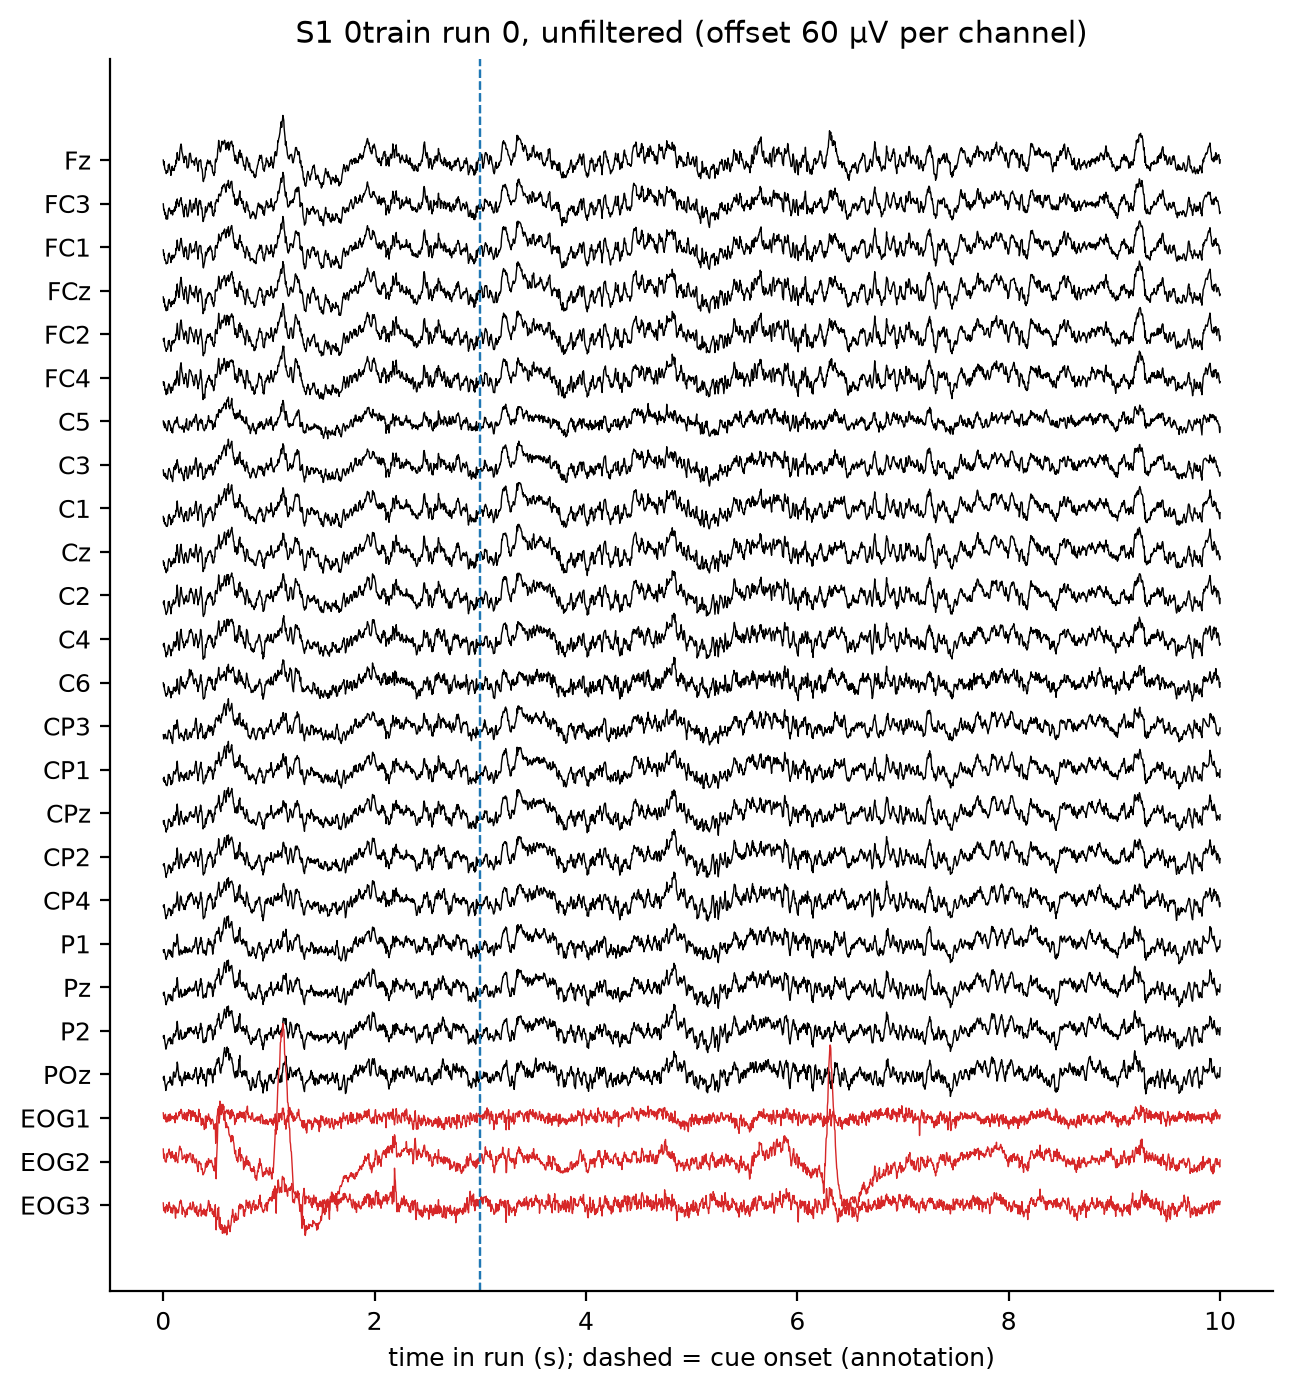

results/figures/fig_1b_sensor_layout.png


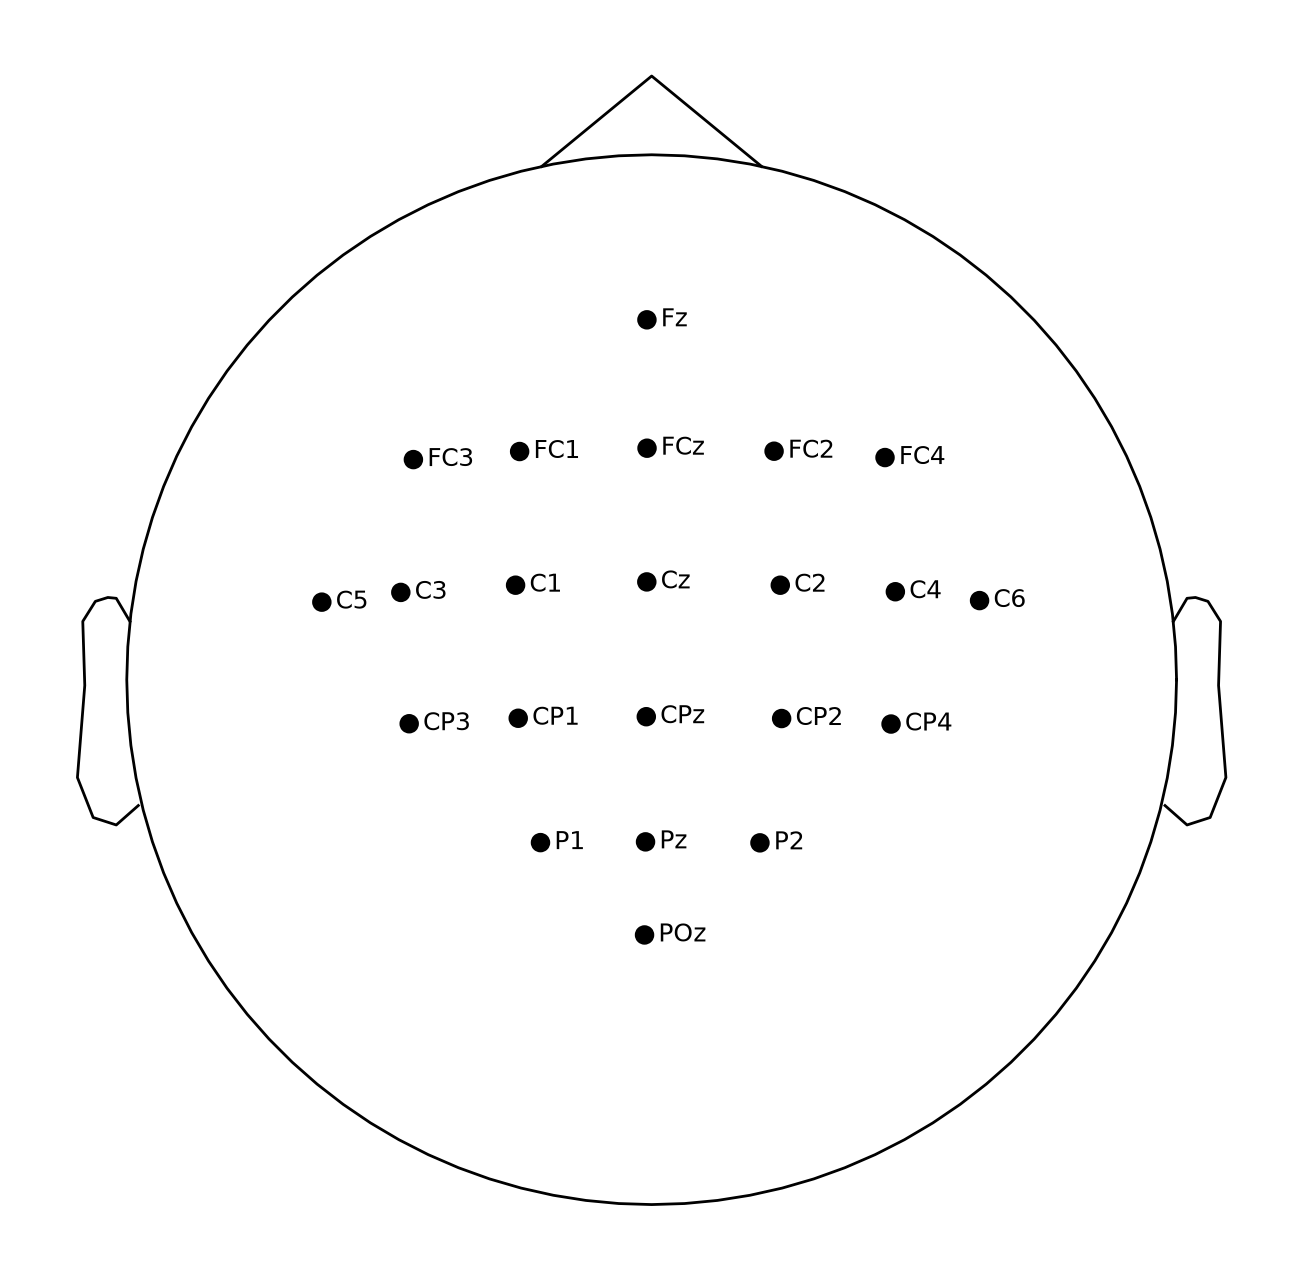

In [14]:
from IPython.display import Image, display
import glob
for f in sorted(glob.glob('results/figures/fig_1*.png')):
    print(f); display(Image(f, width=900))

## Stage 2 - Signal inspection and filtering

Stage 2 - signal inspection and filter choice. Writes fig_2a/fig_2b and signal_*.csv.

In [15]:
from __future__ import annotations



import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd

import config
from src import data, plots, preprocess
from src.timing import timed

mne.set_log_level("ERROR")
print(f"MODE={config.MODE} subjects={config.CFG['subjects']}")

with timed("02_signal_inspection"):
    # spectral QC on every recording (evidence for the notch / high-pass decision)
    rows = []
    for s in config.CFG["subjects"]:
        sessions = data.load_subject(s)
        for sess in config.CFG["sessions"]:
            raw = preprocess.concat_session(sessions[sess])
            rows.append({"subject": s, "session": sess, **preprocess.spectral_qc(raw)})
    qc = pd.DataFrame(rows)
    qc.to_csv(config.TABLES / "signal_psd_qc.csv", index=False)
    print(qc.round(2).to_string(index=False))

    fdesc = preprocess.filter_description()
    pd.DataFrame([fdesc]).to_csv(config.TABLES / "signal_filter_params.csv", index=False)
    print(fdesc)

    # fig_2a: PSD before / after filtering, one subject, first configured session
    s0, sess0 = config.CFG["subjects"][0], config.CFG["sessions"][0]
    raw = preprocess.concat_session(data.load_subject(s0)[sess0])
    filt = preprocess.bandpass(raw)
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
    panels = [("EEG mean (22 ch)", "eeg"), ("C3 / C4", ["C3", "C4"]), ("EOG1-3", "eog")]
    for ax, (title, picks) in zip(axes, panels):
        for r, lab, ls in ((raw, "unfiltered", "-"), (filt, "1-45 Hz FIR", "--")):
            p, f = preprocess.psd(r, picks)
            p = 10 * np.log10(p * 1e12)  # µV^2/Hz in dB
            if picks == "eeg":
                ax.plot(f, p.mean(0), ls=ls, color="k", label=lab, lw=0.9)
            else:
                names = picks if isinstance(picks, list) else ["EOG1", "EOG2", "EOG3"]
                for i, n in enumerate(names):
                    ax.plot(f, p[i], ls=ls, color=f"C{i}", lw=0.9, label=f"{n} {lab}")
        for x in (1.0, 45.0, 50.0):
            ax.axvline(x, color="grey", lw=0.5, ls=":")
        ax.set_title(title); ax.set_xlabel("frequency (Hz)"); ax.set_xlim(0, 125)
        ax.legend(fontsize=6, frameon=False)
    axes[0].set_ylabel("PSD (dB re 1 µV²/Hz)")
    fig.suptitle(f"S{s0} {sess0}, Welch 2 s windows; dotted lines at 1, 45, 50 Hz", fontsize=9)
    plots.save(fig, "fig_2a_psd_before_after")

    # fig_2b: analysis filter response
    kw = {k: v for k, v in preprocess.FILTER_KW.items() if k not in ("picks", "method")}
    h = mne.filter.create_filter(None, config.SFREQ, verbose=False, **kw)
    fig = mne.viz.plot_filter(h, config.SFREQ, freq=None, gain=None, fscale="linear",
                              flim=(0, 70), show=False)
    plots.save(fig, "fig_2b_filter_response")

    # fig_2c: per-recording evidence for the notch decision and the high-band peak check
    lab = [f"S{r.subject}{'T' if r.session == '0train' else 'E'}" for r in qc.itertuples()]
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
    x = np.arange(len(qc))
    axes[0].bar(x - 0.2, qc["eeg_line_50Hz_dB_mean"], 0.4, label="EEG mean", color="k")
    axes[0].bar(x + 0.2, qc["eog_line_50Hz_dB_mean"], 0.4, label="EOG mean", color="C3")
    axes[0].axhline(fdesc["gain_dB_50Hz"], color="C0", ls="--", lw=0.8,
                    label=f"analysis filter gain at 50 Hz ({fdesc['gain_dB_50Hz']:.0f} dB)")
    axes[0].set_ylabel("50 Hz bin above 40-60 Hz flanks (dB)")
    axes[0].set_title("Residual line noise, unfiltered data")
    axes[1].bar(x, qc["eeg_high_peak_dB"], color="C2")
    for i, r in enumerate(qc.itertuples()):
        axes[1].text(i, r.eeg_high_peak_dB + 0.1, f"{r.eeg_high_peak_ch}\n{r.eeg_high_peak_Hz:g}",
                     ha="center", fontsize=5)
    axes[1].set_ylabel("max excess over 1/f fit, 30-45 Hz (dB)")
    axes[1].set_title("Narrowband peaks in the 'high' feature band")
    for ax in axes:
        ax.set_xticks(x, lab, rotation=90, fontsize=7)
    axes[0].legend(fontsize=6, frameon=False)
    plots.save(fig, "fig_2c_line_noise_and_high_band_peaks")


MODE=FULL subjects=[1, 2, 3, 4, 5, 6, 7, 8, 9]


 subject session  eeg_line_50Hz_dB_mean  eeg_line_50Hz_dB_max  eeg_drift_dB_median  eeg_high_peak_Hz eeg_high_peak_ch  eeg_high_peak_dB  eog_line_50Hz_dB_mean  eog_line_50Hz_dB_max  eog_drift_dB_median
       1  0train                  -2.39                  3.47                 3.62              36.0              FC4              6.46                   0.39                 11.18                 7.22
       1   1test                  -2.66                  2.04                 2.94              35.0              FC4              3.85                  -4.62                  1.15                 7.29
       2  0train                   0.95                 10.12                 3.12              36.5               C5              0.87                  -6.36                 -4.01                 4.44
       2   1test                  -2.47                  5.31                 2.87              34.0               C6              0.69                  -7.22                 -1.39            

[timing] 02_signal_inspection: 16.2 s


results/figures/fig_2a_psd_before_after.png


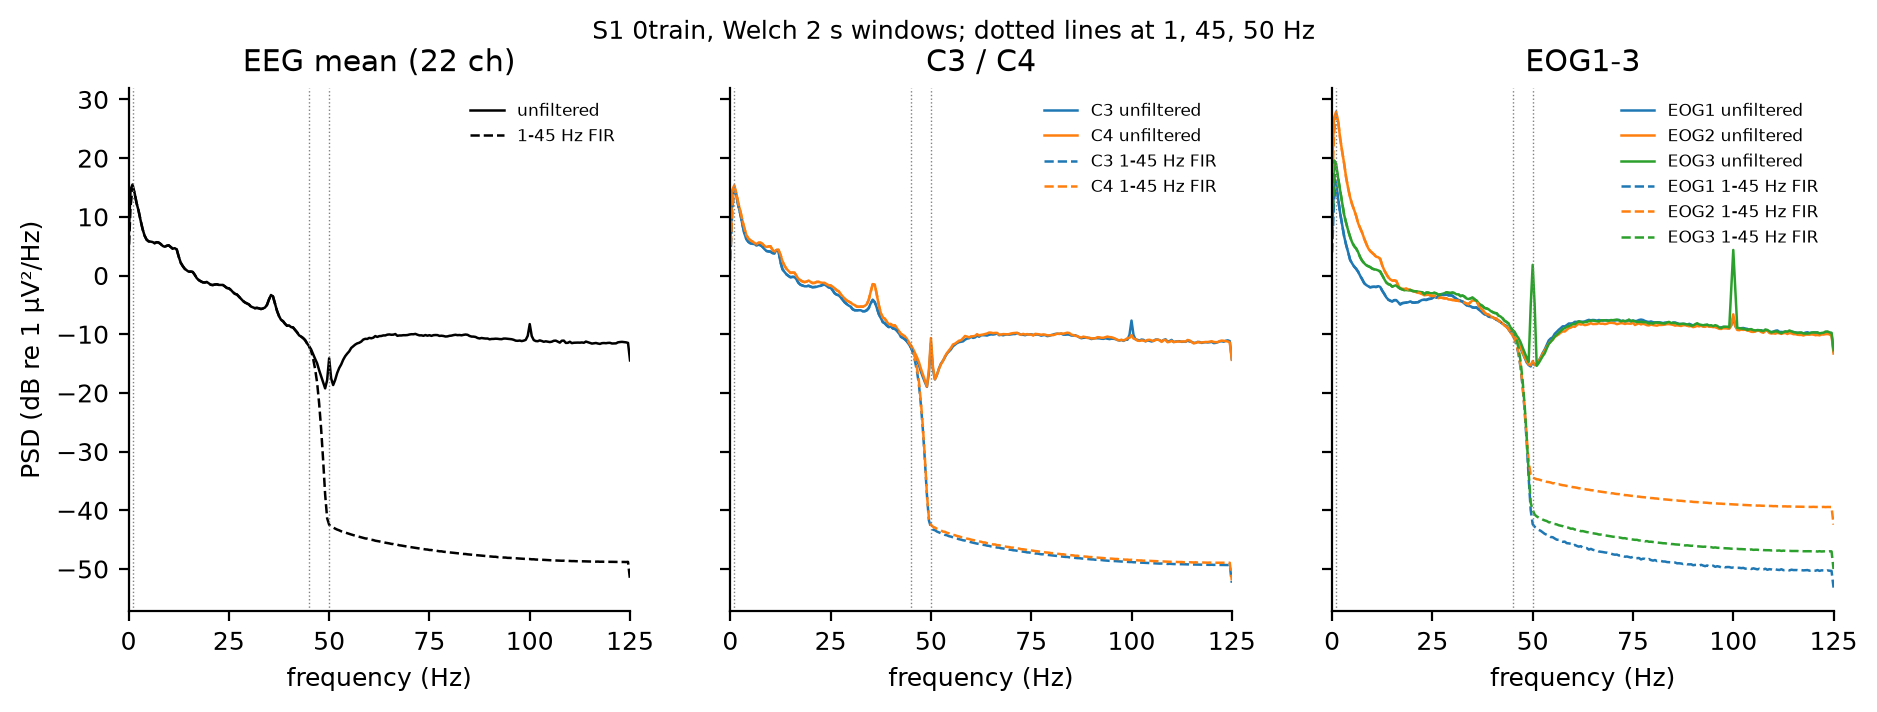

results/figures/fig_2b_filter_response.png


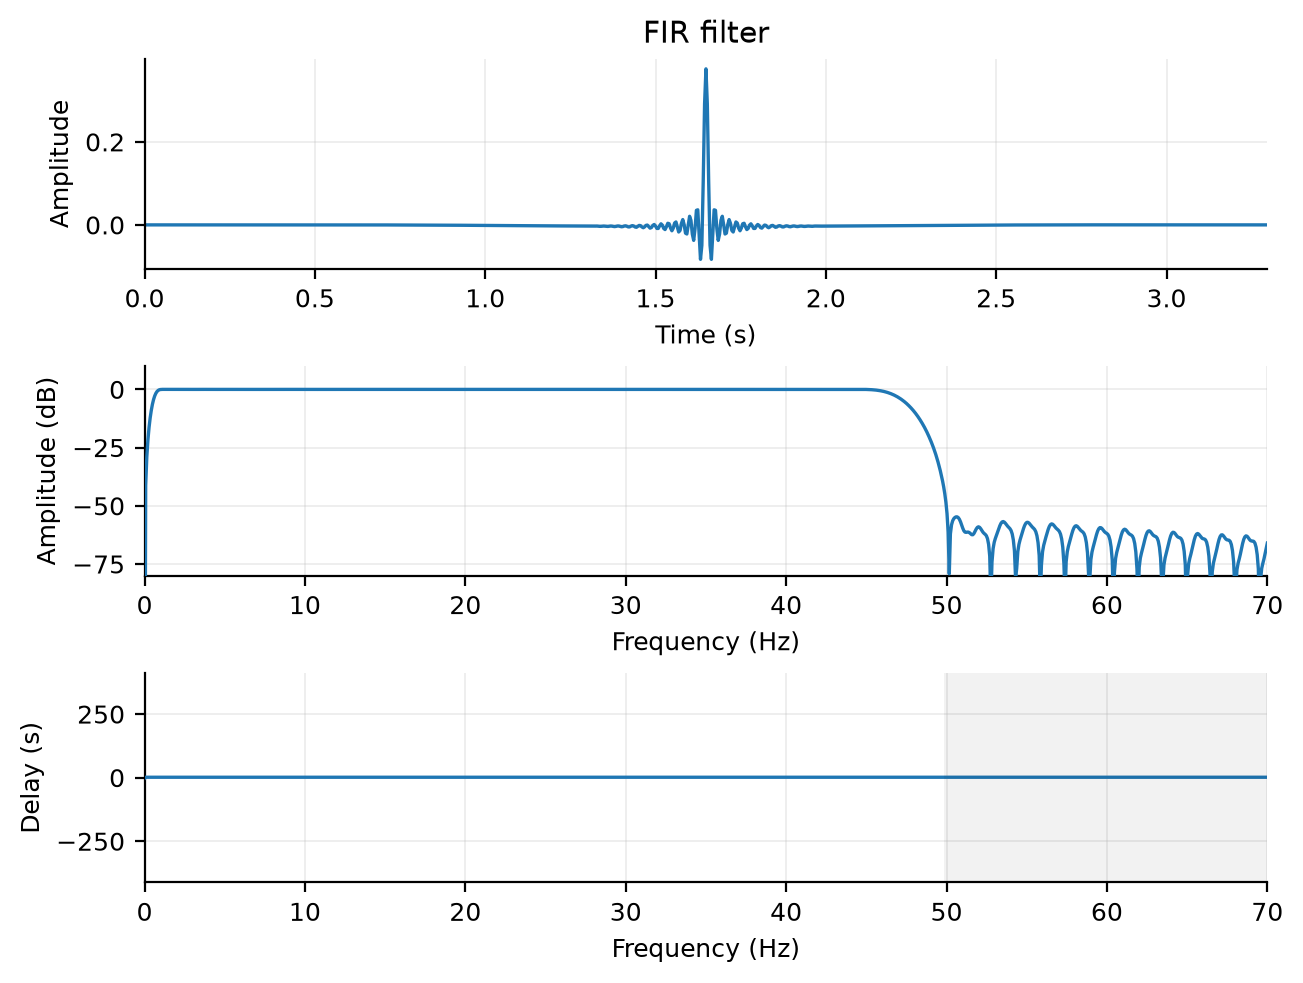

results/figures/fig_2c_line_noise_and_high_band_peaks.png


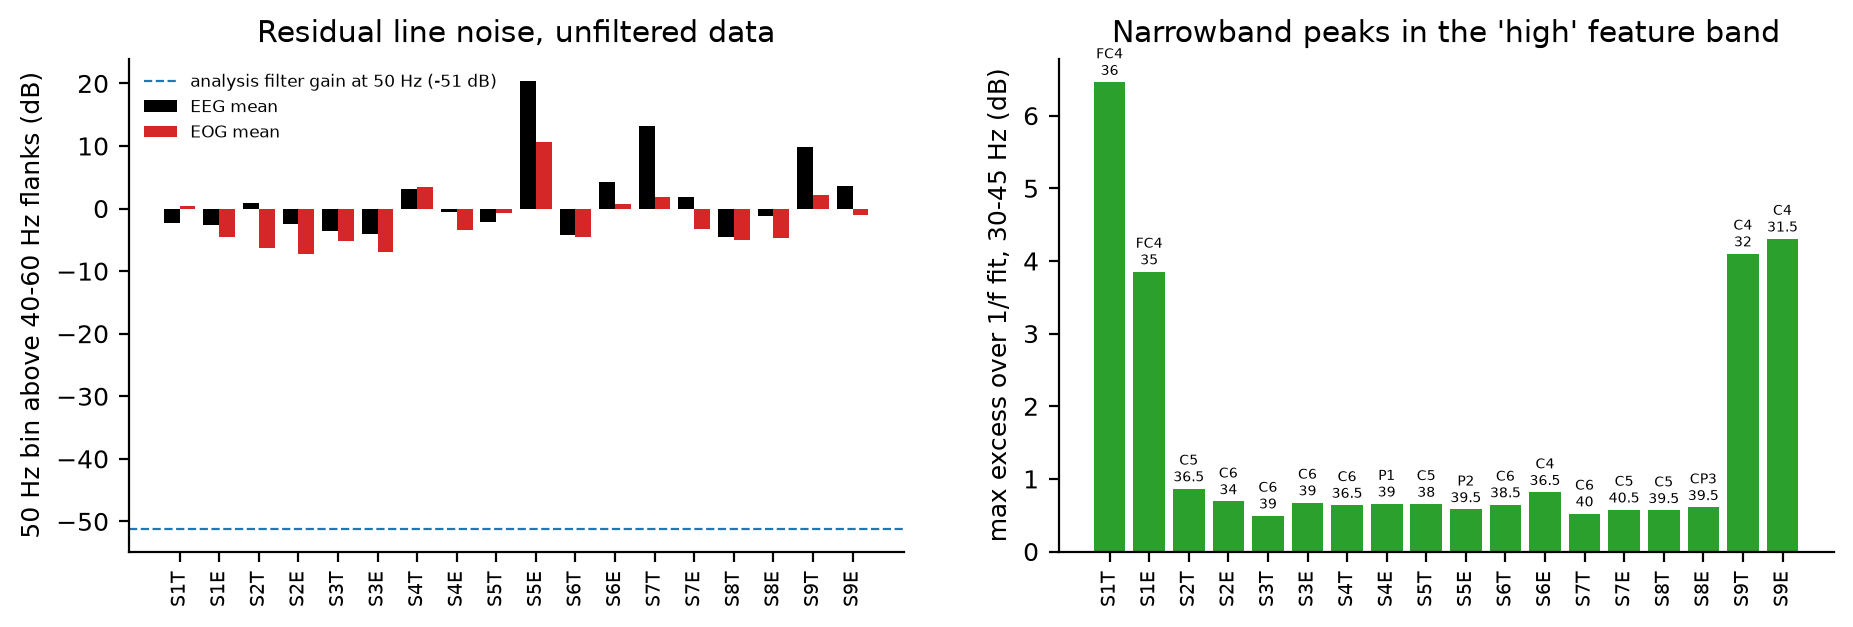

In [16]:
from IPython.display import Image, display
import glob
for f in sorted(glob.glob('results/figures/fig_2*.png')):
    print(f); display(Image(f, width=900))

## Stage 3 - Artifact handling and QC

Stage 3 - artifact handling and QC. Three cleaning conditions, one shared epoch set.

Writes qc_ptp_per_epoch.csv, qc_rejection_counts.csv, qc_cleaning_fit.csv,
qc_eog_correlation.csv and fig_3a-3e.

In [17]:
from __future__ import annotations



import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd

import config
from src import data, plots, preprocess
from src.timing import timed

mne.set_log_level("ERROR")
print(f"MODE={config.MODE} subjects={config.CFG['subjects']} fit_on={config.CLEAN_FIT_ON} "
      f"ptp_reject_uV={config.PTP_REJECT_UV}")

s0, sess0 = config.CFG["subjects"][0], config.CFG["sessions"][0]
ptp_rows, fit_rows, corr_rows, rej_rows = [], [], [], []
with timed("03_artifacts"):
    for s in config.CFG["subjects"]:
        sessions = data.load_subject(s)
        for sess in config.CFG["sessions"]:
            runs = sessions[sess]
            tt = data.trial_table(s, sess, runs)
            conds, info = preprocess.build_conditions(s, sess, runs)
            fit_rows.append({"subject": s, "session": sess, **{k: v for k, v in info.items()
                             if k not in ("ica", "fit_raw", "ica_eog_scores", "ica_excluded")},
                             "ica_excluded": ";".join(map(str, info["ica_excluded"])),
                             "n_ica_excluded": len(info["ica_excluded"]),
                             "ica_max_eog_score_excluded": float(info["ica_eog_scores"].max(0)[info["ica_excluded"]].min())
                             if info["ica_excluded"] else np.nan})
            epochs = {c: preprocess.make_epochs(r, tt) for c, r in conds.items()}
            ptp = pd.DataFrame({f"ptp_{c}_uV": preprocess.ptp_uv(e) for c, e in epochs.items()})
            ptp_rows.append(pd.concat([tt.reset_index(drop=True), ptp], axis=1))
            for c, r in conds.items():
                corr_rows.append({"subject": s, "session": sess, "condition": c, **preprocess.eog_corr(r)})
            if s == s0 and sess == sess0:
                keep_s0 = (conds, info, epochs)
            print(f"S{s} {sess}: ICA {info['n_ica_components']} comps, excluded {info['ica_excluded']}")

    ptp_all = pd.concat(ptp_rows, ignore_index=True)
    thr = config.PTP_REJECT_UV
    ptp_all["rejected"] = (ptp_all["ptp_none_uV"] > thr) if thr is not None else False
    ptp_all.to_csv(config.TABLES / "qc_ptp_per_epoch.csv", index=False)
    pd.DataFrame(fit_rows).to_csv(config.TABLES / "qc_cleaning_fit.csv", index=False)
    corr = pd.DataFrame(corr_rows)
    corr.to_csv(config.TABLES / "qc_eog_correlation.csv", index=False)

    # rejection counts per subject x session x condition (identical across conditions by design)
    fit = pd.DataFrame(fit_rows).set_index(["subject", "session"])
    for (s, sess), g in ptp_all.groupby(["subject", "session"]):
        for c in config.CONDITIONS:
            row = {"subject": s, "session": sess, "condition": c,
                   "n_ica_components": fit.loc[(s, sess), "n_ica_components"] if c == "ica" else np.nan,
                   "ica_excluded": fit.loc[(s, sess), "ica_excluded"] if c == "ica" else "",
                   "n_epochs_rejected": int(g["rejected"].sum()),
                   "n_rejected_also_expert": int((g["rejected"] & (g["expert_artifact"] == 1)).sum())}
            for lab in config.CLASSES_4:
                row[f"kept_{lab}"] = int(((g["label"] == lab) & ~g["rejected"]).sum())
            rej_rows.append(row)
    rej = pd.DataFrame(rej_rows)
    rej.to_csv(config.TABLES / "qc_rejection_counts.csv", index=False)
    print(pd.DataFrame(fit_rows)[["subject", "session", "fit_duration_s", "fit_samples_per_comp2",
                                  "n_ica_components", "ica_excluded", "ica_max_eog_score_excluded"]].to_string(index=False))
    print(corr.groupby("condition")[[c for c in corr if c.startswith("absr")]].median().round(3))
    for c in config.CONDITIONS:
        pc = np.percentile(ptp_all[f"ptp_{c}_uV"], [50, 90, 99, 99.5, 100])
        print(f"PTP {c} (µV) pct 50/90/99/99.5/max:", np.round(pc, 1))
    worse = ptp_all["ptp_eog_reg_uV"] > ptp_all["ptp_none_uV"].max()
    print("epochs where eog_reg PTP exceeds the largest `none` PTP:", int(worse.sum()),
          ptp_all.loc[worse, ["subject", "session", "run", "trial_in_run", "label", "expert_artifact",
                              "ptp_none_uV", "ptp_eog_reg_uV"]].round(0).to_string(index=False))

    conds, info, epochs = keep_s0
    # fig_3a: ICA component maps, excluded ones titled in red
    ica = info["ica"]
    figs = ica.plot_components(inst=None, show=False, title=f"S{s0} {sess0} ICA (fit on {config.CLEAN_FIT_ON})")
    fig = figs[0] if isinstance(figs, list) else figs
    sc = info["ica_eog_scores"].max(0)
    for k, ax in enumerate([a for a in fig.axes if a.get_title()][: ica.n_components_]):
        ax.set_title(f"ICA{k:03d}\n|r|={sc[k]:.2f}", fontsize=7,
                     color="C3" if k in ica.exclude else "k")
    plots.save(fig, "fig_3a_ica_components_topo")

    # fig_3b / fig_3b2: Fz and FC2 in all three conditions around two events in the MI runs.
    #   3b  = typical blink: largest |Fz| in `none` among samples where |EOG| < 300 µV
    #   3b2 = largest |EOG| deflection overall (inspect: may be non-ocular, e.g. an electrode step)
    none = conds["none"]
    eog = none.get_data(picks=config.EOG_CHANNELS, reject_by_annotation="NaN")
    eog = np.nanmax(np.abs(eog - np.nanmedian(eog, axis=1, keepdims=True)), axis=0)
    fz = np.abs(none.get_data(picks="Fz", reject_by_annotation="NaN")[0])
    events_3b = {"fig_3b_eog_regression_before_after": int(np.nanargmax(np.where(eog < 300e-6, fz, np.nan))),
                 "fig_3b2_largest_eog_event": int(np.nanargmax(eog))}
    for fname, i_peak in events_3b.items():
        t_peak = none.times[i_peak]
        tmin, tmax = max(t_peak - 2.0, 0), min(t_peak + 2.0, none.times[-1])
        fig, axes = plt.subplots(3, 1, figsize=(7, 5.5), sharex=True)
        seg = none.copy().crop(tmin, tmax)
        for e in config.EOG_CHANNELS:
            axes[0].plot(seg.times + tmin, seg.get_data(picks=e)[0] * 1e6, lw=0.8, label=e)
        axes[0].set_ylabel("EOG (µV)"); axes[0].legend(fontsize=6, frameon=False, ncol=3)
        for ax, ch in zip(axes[1:], ["Fz", "FC2"]):
            for c, col in zip(config.CONDITIONS, ["k", "C1", "C2"]):
                x = conds[c].copy().crop(tmin, tmax).get_data(picks=ch)[0] * 1e6
                ax.plot(seg.times + tmin, x, lw=0.8, color=col, label=c)
            ax.set_ylabel(f"{ch} (µV)"); ax.legend(fontsize=6, frameon=False, ncol=3)
        axes[-1].set_xlabel("time in session (s)")
        what = "typical blink" if "3b_" in fname else "largest EOG deflection"
        fig.suptitle(f"S{s0} {sess0}: {what} in MI runs, 1-45 Hz + CAR", fontsize=9)
        plots.save(fig, fname)

    # fig_3c: per-epoch max EEG peak-to-peak (all configured recordings), none condition
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    bins = np.logspace(np.log10(ptp_all[[f"ptp_{c}_uV" for c in config.CONDITIONS]].min().min()),
                       np.log10(ptp_all[[f"ptp_{c}_uV" for c in config.CONDITIONS]].max().max()), 60)
    ok = ptp_all["expert_artifact"] == 0
    axes[0].hist([ptp_all.loc[ok, "ptp_none_uV"], ptp_all.loc[~ok, "ptp_none_uV"]], bins=bins,
                 stacked=True, color=["0.6", "C3"], label=["expert: clean", "expert: artifact"])
    for q, ls in ((99, ":"), (99.5, "--")):
        axes[0].axvline(np.percentile(ptp_all["ptp_none_uV"], q), color="k", ls=ls, lw=0.8, label=f"{q}th pct")
    if thr is not None:
        axes[0].axvline(thr, color="C0", lw=1.2, label=f"threshold {thr:g} µV")
    axes[0].set_xscale("log"); axes[0].set_xlabel("max EEG peak-to-peak per epoch, `none` (µV)")
    axes[0].set_ylabel("epochs"); axes[0].legend(fontsize=6, frameon=False)
    for c, col in zip(config.CONDITIONS, ["k", "C1", "C2"]):
        axes[1].hist(ptp_all[f"ptp_{c}_uV"], bins=bins, histtype="step", color=col, label=c)
    axes[1].set_xscale("log"); axes[1].set_xlabel("max EEG peak-to-peak per epoch (µV)")
    axes[1].legend(fontsize=6, frameon=False)
    from matplotlib.ticker import FixedLocator, NullFormatter, ScalarFormatter
    for ax in axes:
        ax.xaxis.set_major_locator(FixedLocator([20, 30, 50, 100, 200, 400]))
        ax.xaxis.set_major_formatter(ScalarFormatter()); ax.xaxis.set_minor_formatter(NullFormatter())
    fig.suptitle(f"{len(ptp_all)} epochs, {ptp_all.groupby(['subject','session']).ngroups} recordings, "
                 "window -1 to +4 s around cue", fontsize=9)
    plots.save(fig, "fig_3c_ptp_histogram")

    # fig_3d: reference choice. Mastoid (as recorded) vs CAR, mean log MI-window 8-30 Hz power
    from src import data as _d  # noqa: F401
    mast = preprocess.bandpass(preprocess.concat_session(data.load_subject(s0)[sess0]))
    tt0 = data.trial_table(s0, sess0, data.load_subject(s0)[sess0])
    fig, axes = plt.subplots(1, 2, figsize=(6.5, 3))
    for ax, (name, r) in zip(axes, (("left mastoid (recorded)", mast), ("CAR", conds["none"]))):
        ep = preprocess.make_epochs(r, tt0).pick("eeg").crop(*config.MI_WINDOW)
        sp = ep.compute_psd(method="welch", fmin=8, fmax=30, n_fft=250, verbose=False)
        lp = np.log10(sp.get_data().mean(-1).mean(0) * 1e12)
        im, _ = mne.viz.plot_topomap(lp, ep.info, axes=ax, show=False, cmap=plots.CMAP_SEQ, contours=0)
        ax.set_title(name, fontsize=8)
        plt.colorbar(im, ax=ax, shrink=0.7, label="log10 µV²/Hz")
    fig.suptitle(f"S{s0} {sess0}: mean 8-30 Hz power, MI window {config.MI_WINDOW} s after cue", fontsize=8)
    plots.save(fig, "fig_3d_reference_mastoid_vs_car")

    # fig_3e: residual |r| between Fz and each EOG channel, per recording and condition
    fig, ax = plt.subplots(figsize=(8, 3))
    corr["rec"] = corr["subject"].map("S{}".format) + corr["session"].map({"0train": "T", "1test": "E"})
    corr["absr_max"] = corr[[f"absr_Fz_{e}" for e in config.EOG_CHANNELS]].max(axis=1)
    piv = corr.pivot(index="rec", columns="condition", values="absr_max")[config.CONDITIONS]
    piv = piv.loc[sorted(piv.index, key=lambda r: (int(r[1:-1]), r[-1] != "T"))]
    piv.plot.bar(ax=ax, color=["k", "C1", "C2"], width=0.8)
    ax.set_ylabel("max |r| (Fz, EOG1-3)"); ax.set_xlabel("")
    ax.legend(fontsize=7, frameon=False)
    plots.save(fig, "fig_3e_residual_eog_correlation")

    # fig_3f: evidence for the ICA exclusion threshold. Max |r| (any EOG channel) of every
    # component on the fitting data, all configured recordings.
    sc_all = []
    for s_, sess_ in [(r["subject"], r["session"]) for r in fit_rows]:
        sp = config.CACHE / "ica" / f"S{s_:02d}_{sess_}_{config.CLEAN_FIT_ON}-ica.scores.npy"
        sc_all.append(np.load(sp).max(0))
    sc_all = np.concatenate(sc_all)
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.hist(sc_all, bins=np.linspace(0, 1, 41), color="0.5")
    ax.axvline(config.ICA_EOG_THRESHOLD, color="C3", lw=1, label=f"threshold |r| = {config.ICA_EOG_THRESHOLD}")
    ax.set_xlabel("max |r| with EOG1-3, ICA component time course (fitting data)")
    ax.set_ylabel("components"); ax.legend(fontsize=7, frameon=False)
    ax.set_title(f"{len(sc_all)} components, {len(fit_rows)} recordings", fontsize=8)
    plots.save(fig, "fig_3f_ica_eog_score_distribution")


MODE=FULL subjects=[1, 2, 3, 4, 5, 6, 7, 8, 9] fit_on=calibration ptp_reject_uV=None


S1 0train: ICA 20 comps, excluded [0, 1]


S1 1test: ICA 20 comps, excluded [0, 1]


S2 0train: ICA 20 comps, excluded [0, 1]


S2 1test: ICA 20 comps, excluded [0, 1]


S3 0train: ICA 20 comps, excluded [2, 7]


... (10 outputs left out)

S8 1test: ICA 20 comps, excluded [0, 3]


S9 0train: ICA 20 comps, excluded [0, 1]


S9 1test: ICA 20 comps, excluded [1, 2]
 subject session  fit_duration_s  fit_samples_per_comp2  n_ica_components ica_excluded  ica_max_eog_score_excluded
       1  0train         365.272               228.2950                20          0;1                    0.899118
       1   1test         423.160               264.4750                20          0;1                    0.918588
       2  0train         383.836               239.8975                20          0;1                    0.926050
       2   1test         325.824               203.6400                20          0;1                    0.939611
       3  0train         317.280               198.3000                20          2;7                    0.716555
       3   1test         270.260               168.9125                20          1;4                    0.774647
       4  0train          79.620                49.7625                20          0;1                    0.862044
       4   1test         315.348        

[timing] 03_artifacts: 57.5 s


results/figures/fig_3a_ica_components_topo.png


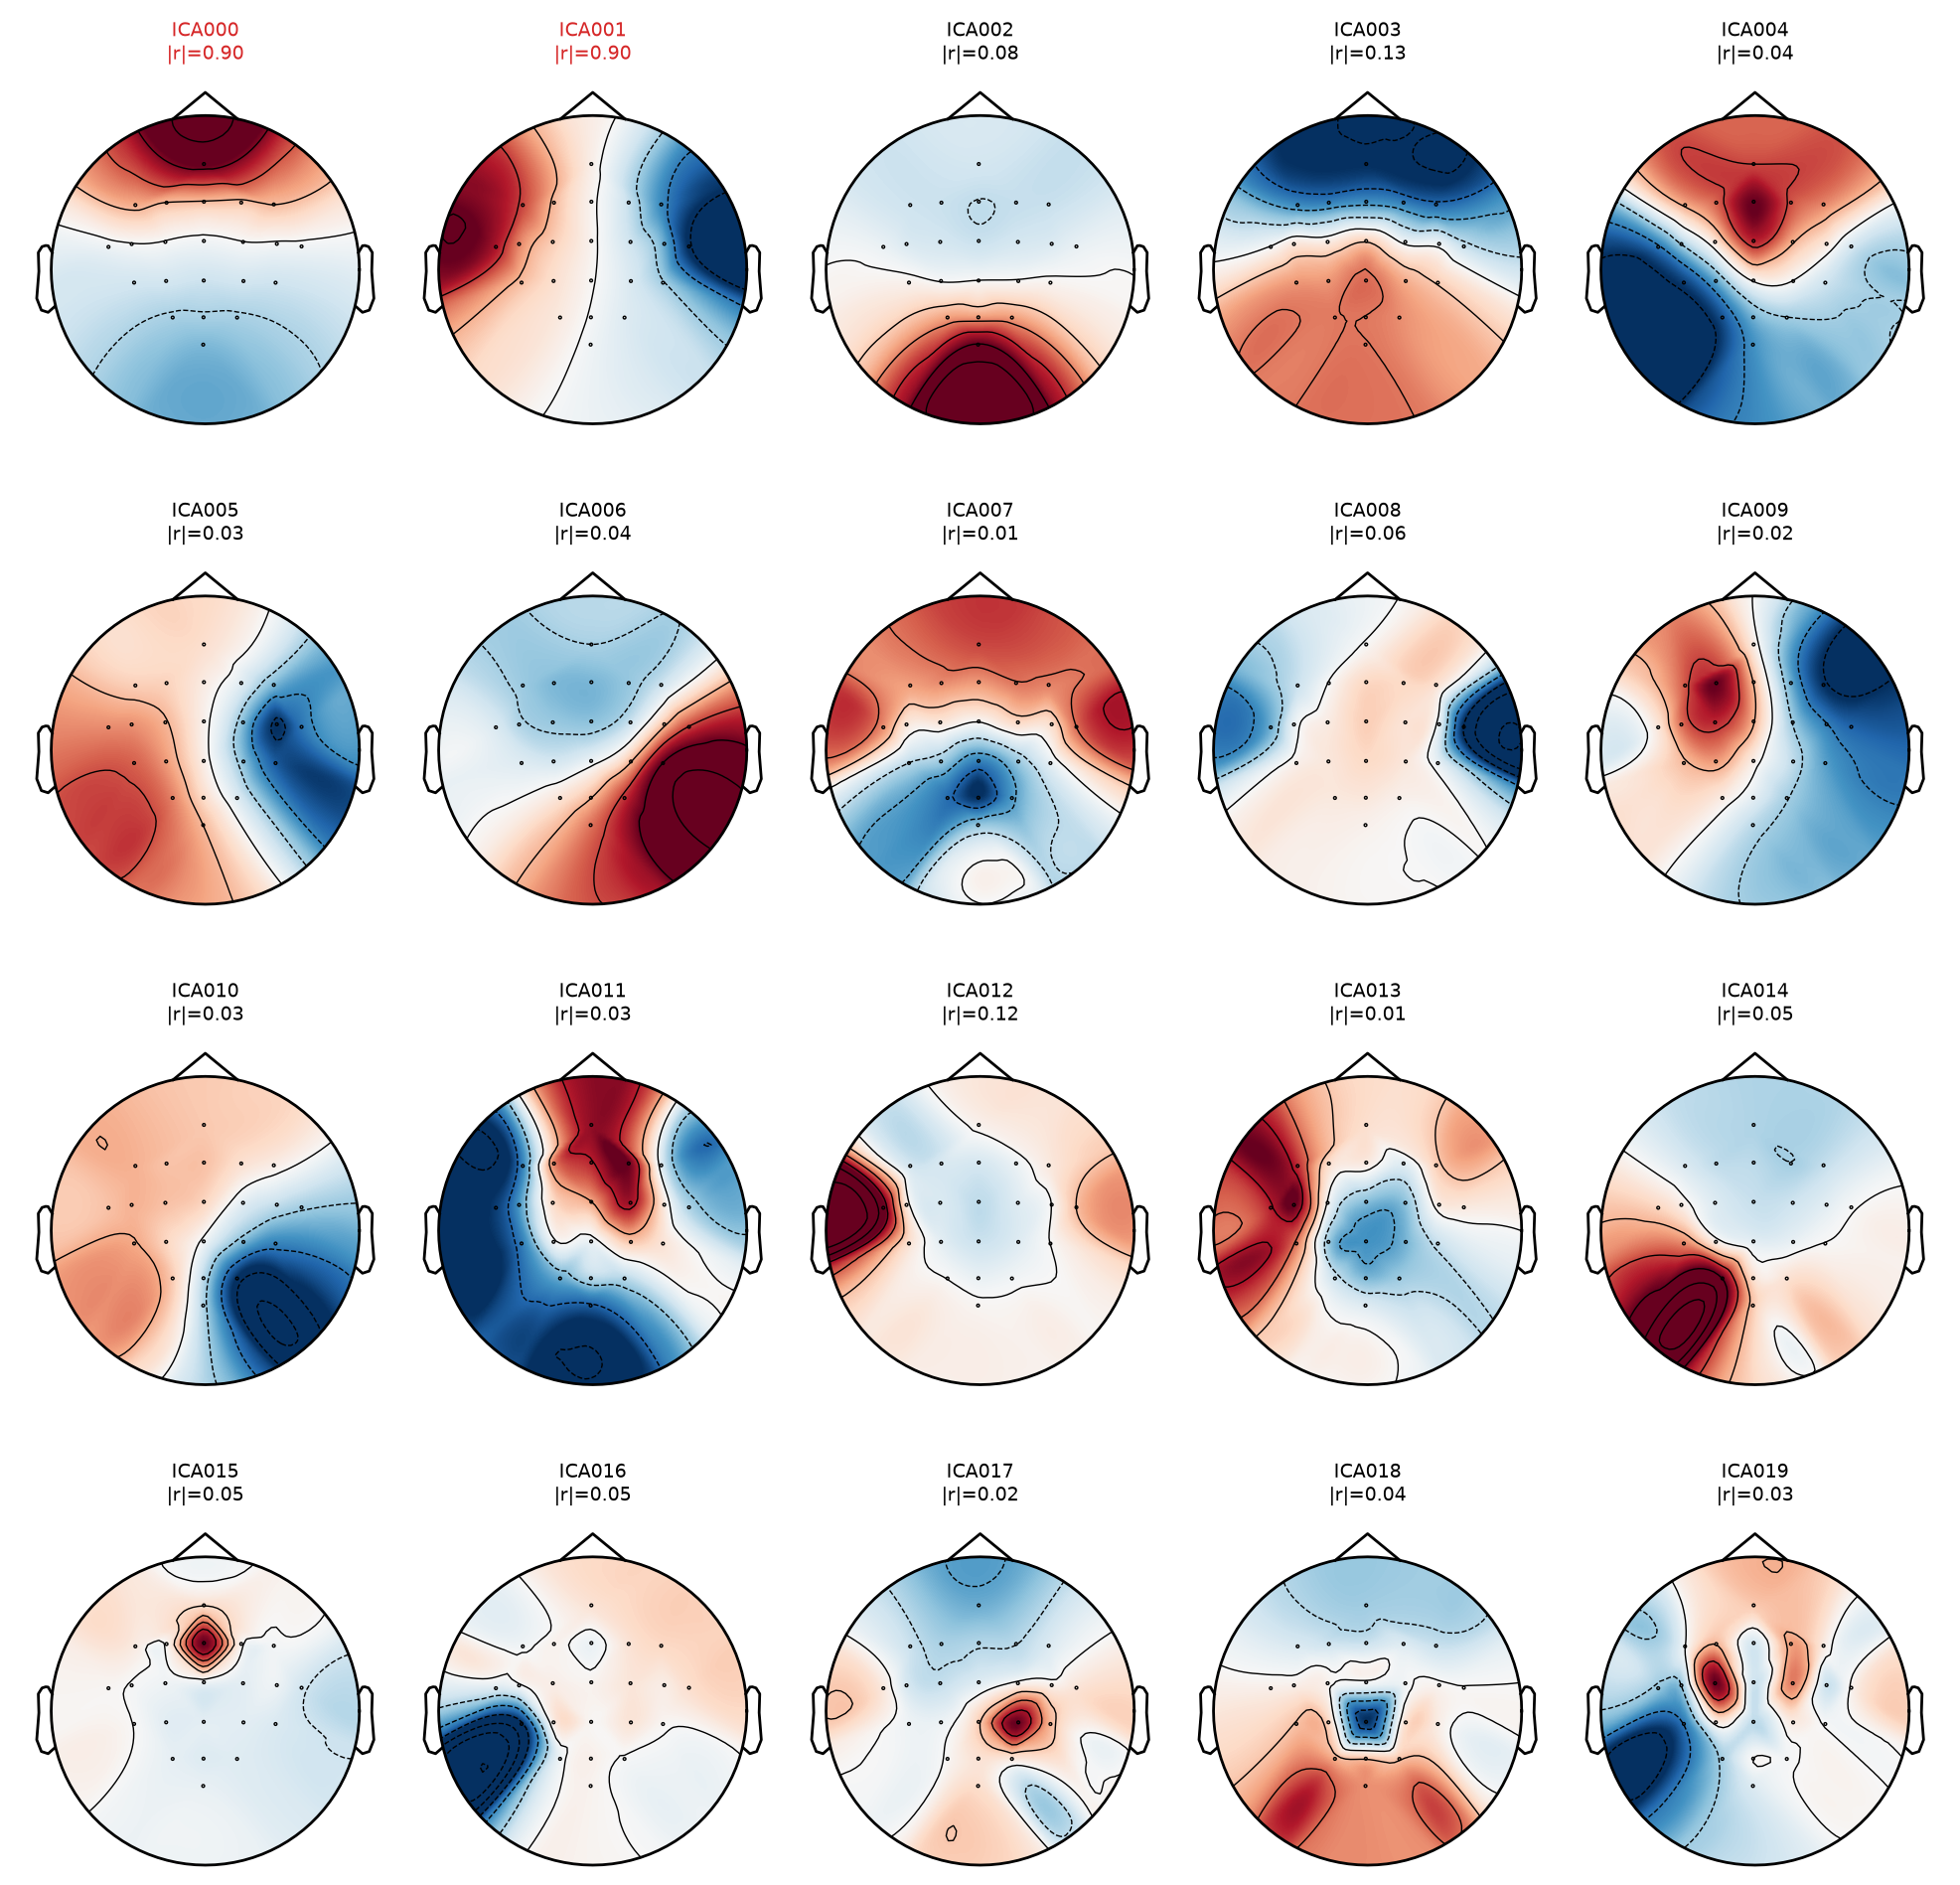

results/figures/fig_3b2_largest_eog_event.png


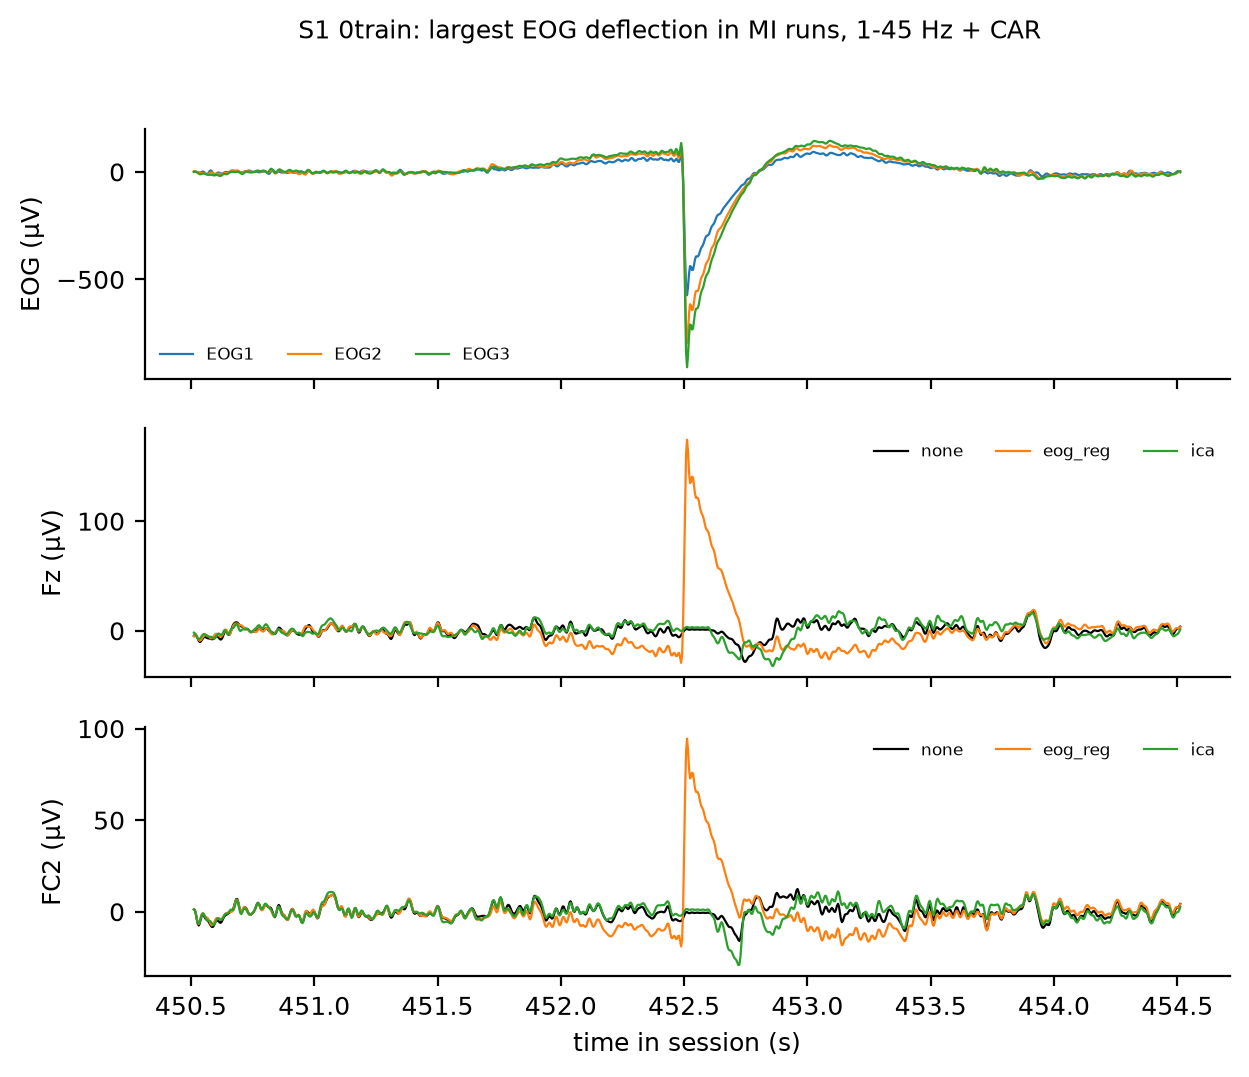

results/figures/fig_3b_eog_regression_before_after.png


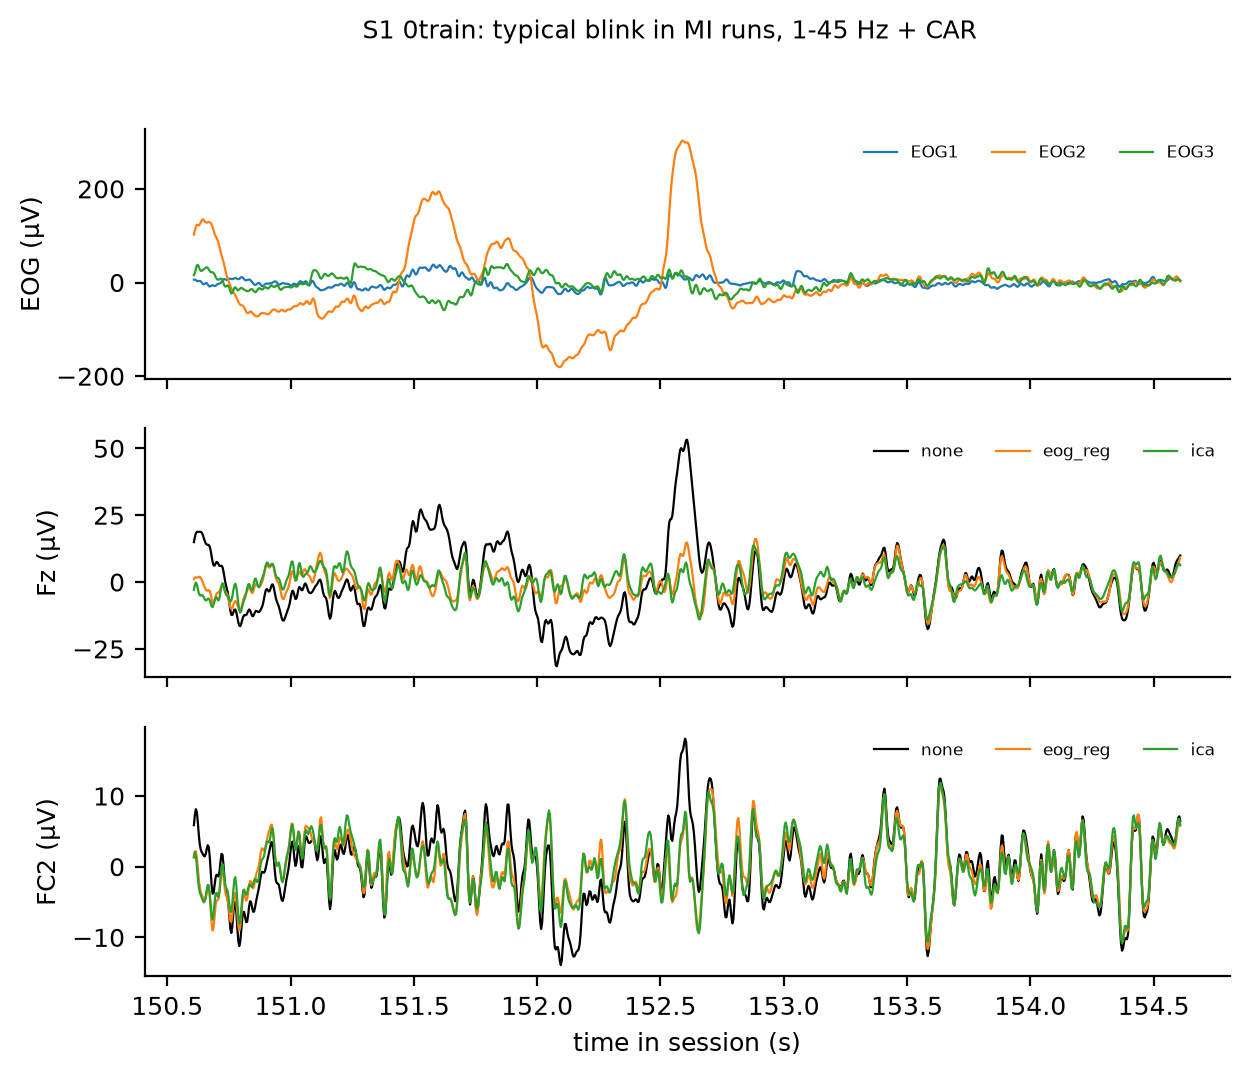

results/figures/fig_3c_ptp_histogram.png


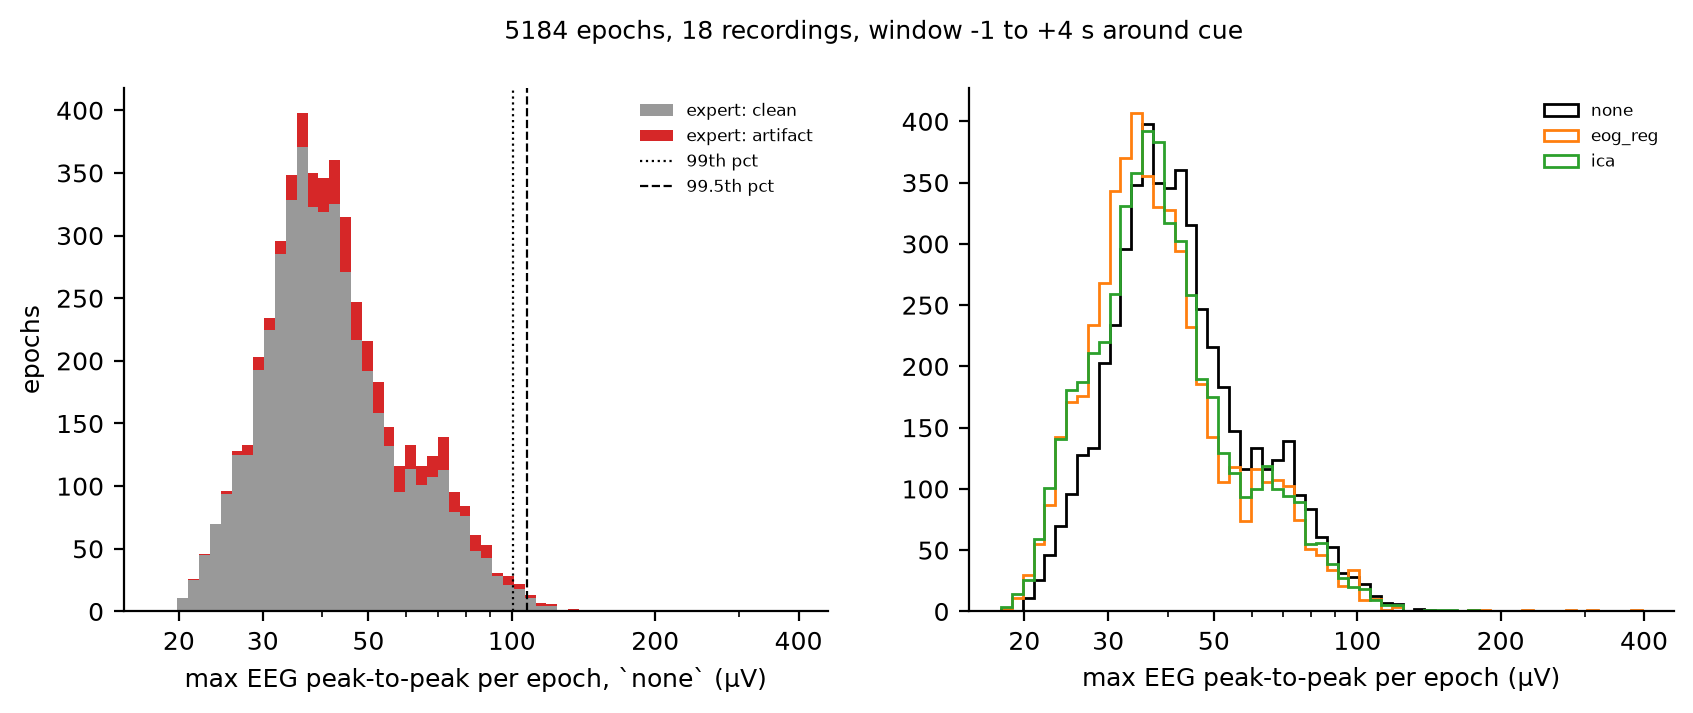

results/figures/fig_3d_reference_mastoid_vs_car.png


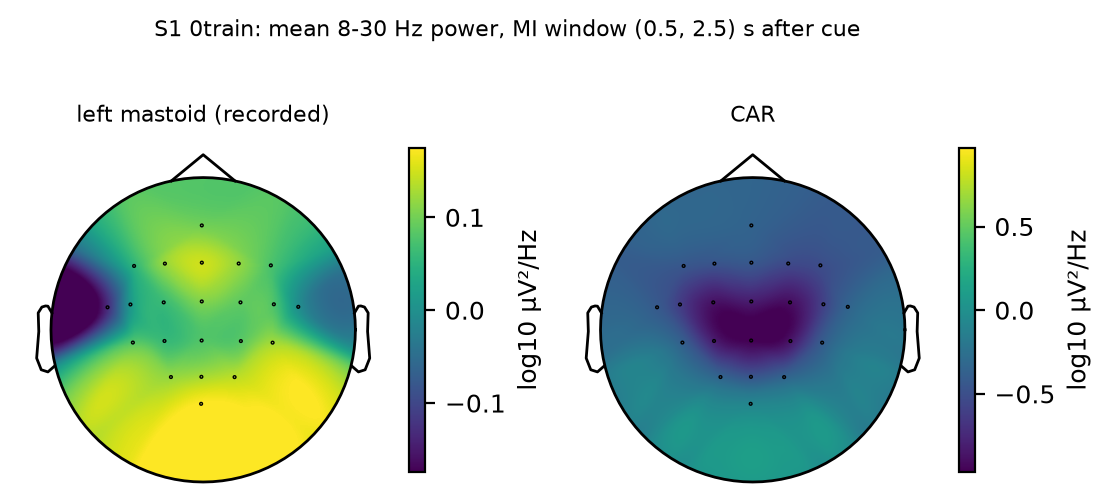

results/figures/fig_3e_residual_eog_correlation.png


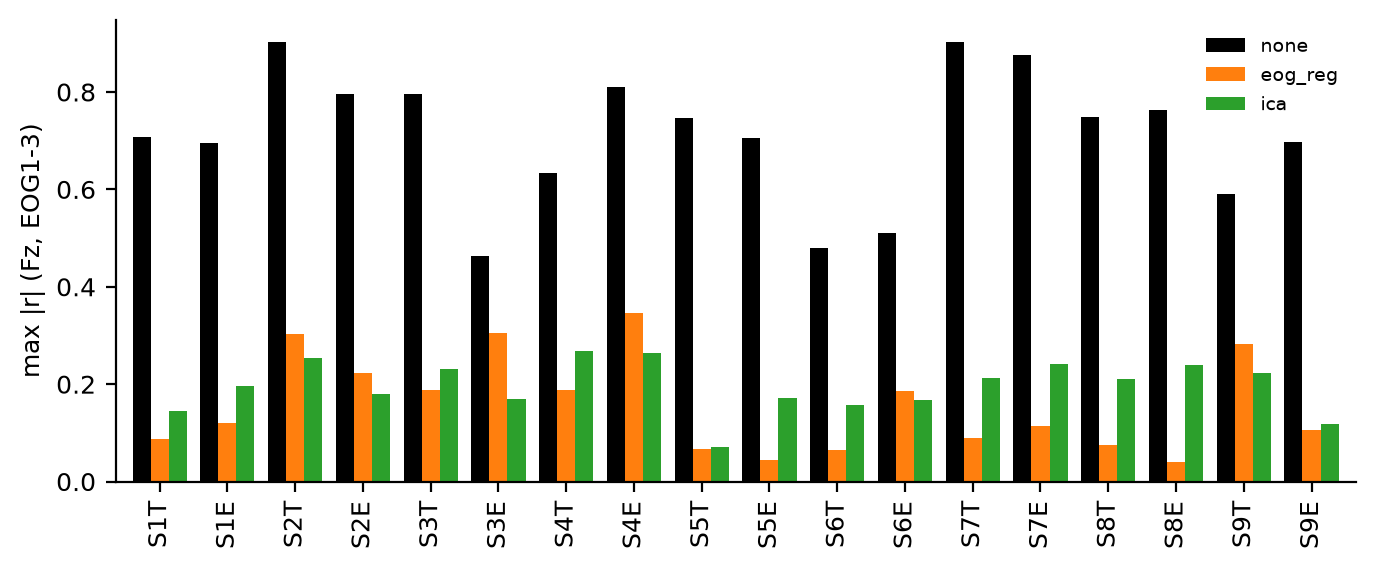

results/figures/fig_3f_ica_eog_score_distribution.png


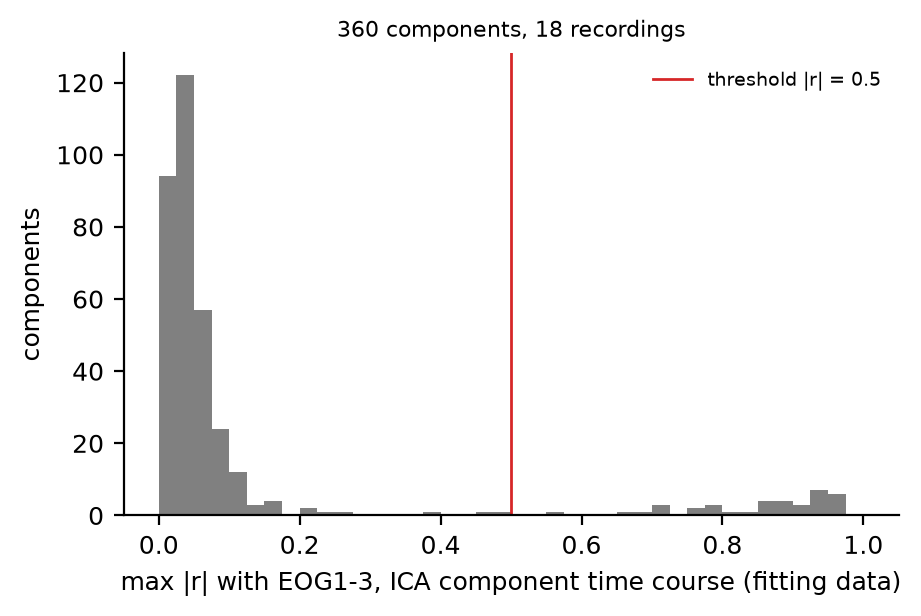

In [18]:
from IPython.display import Image, display
import glob
for f in sorted(glob.glob('results/figures/fig_3*.png')):
    print(f); display(Image(f, width=900))

## Stage 4 - Neurophysiological check

Stage 4 - neurophysiological checks before any decoding.

(1) Mu/beta ERD over C3/C4 (does the expected signal exist?)
(2) Cue-locked EOG and frontal EEG by class (does the suspected confound exist?)
Also writes the per-recording feature cache used by Phase 5.

In [19]:
from __future__ import annotations



import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from scipy import stats

import config
from src import data, features, neurophys, plots, preprocess
from src.timing import timed

mne.set_log_level("ERROR")
print(f"MODE={config.MODE} subjects={config.CFG['subjects']}")
BANDS = list(config.BANDS)
FRONTAL = ["Fz", "FC1", "FC2", "FC3", "FC4"]
erd_rows, eog_rows, hb_rows = [], [], []
evk = {}          # (s, sess, cond, kind) -> {class: mean time course}
psd_c34 = {}      # (s, sess, cond) -> {class: (2, n_freq)}
with timed("04_neurophys_check"):
    qc2 = pd.read_csv(config.TABLES / "signal_psd_qc.csv").set_index(["subject", "session"]) \
        if (config.TABLES / "signal_psd_qc.csv").exists() else None
    for s in config.CFG["subjects"]:
        sessions = data.load_subject(s)
        for sess in config.CFG["sessions"]:
            runs = sessions[sess]
            tt = data.trial_table(s, sess, runs)
            conds, _ = preprocess.build_conditions(s, sess, runs)
            eps = {c: preprocess.make_epochs(r, tt) for c, r in conds.items()}
            features.save_recording(s, sess, eps)
            labels = tt["label"].to_numpy()
            times = eps["none"].times

            # wide-band copy for the EOG evoked check: no extra high-pass (acquisition 0.5 Hz)
            wide = preprocess.concat_session(runs).filter(None, 45.0, h_trans_bandwidth=5.0,
                                                         picks=["eog"], verbose=False)
            ep_wide = preprocess.make_epochs(wide, tt)

            for c in ("none", "eog_reg", "ica"):
                ep = eps[c]
                ch = ep.copy().pick(["eeg", "eog"]).ch_names
                x = ep.get_data(picks=["eeg", "eog"])
                f = features.epoch_features(ep)
                erd = neurophys.erd_db(f["bp"], f["bp_base"])
                erd_mean = {k: erd[labels == k].mean(0) for k in config.CLASSES_4}
                for k in config.CLASSES_4:
                    for ci, chn in enumerate(ch):
                        if chn.startswith("EOG"):
                            continue
                        for bi, b in enumerate(BANDS):
                            erd_rows.append({"subject": s, "session": sess, "condition": c, "label": k,
                                             "channel": chn, "band": b, "erd_dB": erd_mean[k][ci, bi]})
                # class-wise PSD at C3/C4, MI window
                mi = x[:, [ch.index("C3"), ch.index("C4")]][..., (times >= config.MI_WINDOW[0]) & (times < config.MI_WINDOW[1])]
                fr, pw = __import__("scipy.signal", fromlist=["welch"]).welch(mi * 1e6, fs=config.SFREQ,
                                                                              nperseg=250, noverlap=125, axis=-1)
                psd_c34[(s, sess, c)] = {k: 10 * np.log10(pw[labels == k].mean(0)) for k in config.CLASSES_4}
                # frontal EEG evoked by class (baseline -1..0)
                base = (times >= config.BASELINE[0]) & (times < config.BASELINE[1])
                xb = (x - x[..., base].mean(-1, keepdims=True)) * 1e6
                for chn in FRONTAL:
                    evk[(s, sess, c, chn)] = {k: xb[labels == k, ch.index(chn)].mean(0) for k in config.CLASSES_4}
                if c == "none":
                    for band, xb_src in (("1-45", xb), ("wide", None)):
                        if band == "wide":
                            xw = ep_wide.get_data(picks="eog")
                            xb_src = (xw - xw[..., base].mean(-1, keepdims=True)) * 1e6
                            d = neurophys.eog_derivations(xb_src, config.EOG_CHANNELS)
                        else:
                            d = neurophys.eog_derivations(xb_src, ch)
                        for kind, sig in d.items():
                            evk[(s, sess, band, kind)] = {k: sig[labels == k].mean(0) for k in config.CLASSES_4}
                            w = (times >= 0.2) & (times < 1.0)
                            m = sig[:, w].mean(-1)
                            l, r = m[labels == "left_hand"], m[labels == "right_hand"]
                            t_, p_ = stats.ttest_ind(l, r, equal_var=False)
                            sd = np.sqrt((l.var(ddof=1) + r.var(ddof=1)) / 2)
                            eog_rows.append({"subject": s, "session": sess, "band": band, "derivation": kind,
                                             "window_s": "0.2-1.0", **{f"mean_{k}_uV": float(m[labels == k].mean()) for k in config.CLASSES_4},
                                             "left_minus_right_uV": float(l.mean() - r.mean()),
                                             "cohen_d_LR": float((l.mean() - r.mean()) / sd), "welch_t": float(t_), "p_two_sided": float(p_)})
                    # high-band (30-45 Hz) power by class at the channel with the Phase 2 peak
                    if qc2 is not None:
                        pk = qc2.loc[(s, sess)]
                        hch = pk["eeg_high_peak_ch"]
                        hb = f["bp"][:, ch.index(hch), BANDS.index("high")]
                        l, r = hb[labels == "left_hand"], hb[labels == "right_hand"]
                        hb_rows.append({"subject": s, "session": sess, "channel": hch, "peak_Hz": pk["eeg_high_peak_Hz"],
                                        "peak_dB": pk["eeg_high_peak_dB"],
                                        **{f"high_log10P_{k}": float(hb[labels == k].mean()) for k in config.CLASSES_4},
                                        "kruskal_p_4class": float(stats.kruskal(*[hb[labels == k] for k in config.CLASSES_4]).pvalue),
                                        "welch_p_LR": float(stats.ttest_ind(l, r, equal_var=False).pvalue)})
            print(f"S{s} {sess} done")

    erd_df = pd.DataFrame(erd_rows)
    erd_df.to_csv(config.TABLES / "neuro_erd.csv", index=False)
    eog_df = pd.DataFrame(eog_rows)
    eog_df.to_csv(config.TABLES / "neuro_eog_evoked_stats.csv", index=False)
    pd.DataFrame(hb_rows).to_csv(config.TABLES / "neuro_high_band_by_class.csv", index=False)

    # per-subject lateralization of ERD (C3 vs C4) and BCI-inefficiency flag
    lat_rows = []
    for (s, sess, c), g in erd_df.groupby(["subject", "session", "condition"]):
        for b in ("mu", "beta"):
            gb = g[g.band == b].set_index(["label", "channel"])["erd_dB"]
            li = (gb[("right_hand", "C3")] - gb[("right_hand", "C4")]) - (gb[("left_hand", "C3")] - gb[("left_hand", "C4")])
            lat_rows.append({"subject": s, "session": sess, "condition": c, "band": b, "lateralization_dB": li,
                             "erd_C3_right": gb[("right_hand", "C3")], "erd_C4_left": gb[("left_hand", "C4")]})
    lat = pd.DataFrame(lat_rows)
    piv = lat.pivot_table(index=["subject", "session", "condition"], columns="band", values="lateralization_dB").reset_index()
    # weak / absent contralateral ERD: neither band reaches -0.5 dB lateralization
    piv["erd_weak_flag"] = (piv["mu"] > -0.5) & (piv["beta"] > -0.5)
    lat = lat.merge(piv[["subject", "session", "condition", "erd_weak_flag"]], on=["subject", "session", "condition"])
    lat.to_csv(config.TABLES / "neuro_erd_lateralization.csv", index=False)
    print(piv.round(2).to_string(index=False))
    print(eog_df.query("band == '1-45'").round(3)[["subject", "session", "derivation", "left_minus_right_uV", "cohen_d_LR", "p_two_sided"]].to_string(index=False))

    sess0 = config.CFG["sessions"][0]
    subs = config.CFG["subjects"]
    cols = {"left_hand": "C0", "right_hand": "C3", "feet": "C2", "tongue": "C4"}

    # fig_4a: ERD bars at C3/C4, left vs right, mu/beta, none vs ica (primary session)
    fig, axes = plt.subplots(1, 4, figsize=(11, 3), sharey=True)
    for ax, (c, b) in zip(axes, [(c, b) for c in ("none", "ica") for b in ("mu", "beta")]):
        g = erd_df.query("session == @sess0 and condition == @c and band == @b and channel in ['C3','C4'] and label in @config.CLASSES_LR")
        per = g.pivot_table(index="subject", columns=["channel", "label"], values="erd_dB")
        for j, (chn, lab) in enumerate([(a, l) for a in ("C3", "C4") for l in config.CLASSES_LR]):
            v = per[(chn, lab)]
            ax.bar(j, v.mean(), yerr=v.sem() if len(v) > 1 else 0, color=cols[lab], alpha=0.8)
            ax.scatter(np.full(len(v), j) + np.linspace(-0.2, 0.2, len(v)), v, s=6, color="k", zorder=3)
        ax.set_xticks(range(4), ["C3\nleft", "C3\nright", "C4\nleft", "C4\nright"], fontsize=7)
        ax.axhline(0, color="k", lw=0.5); ax.set_title(f"{c}, {b}", fontsize=8)
    axes[0].set_ylabel("ERD (dB, MI vs baseline)\nmean ± SEM, dots = subjects")
    fig.suptitle(f"Session {sess0}: contralateral ERD expected (C3 lower for right hand, C4 lower for left)", fontsize=8)
    plots.save(fig, "fig_4a_erd_c3c4")

    # fig_4b: ERD topomaps, ica condition, grand average over subjects
    info = mne.create_info([c for c in features.load_recording(subs[0], sess0)["none"]["ch_names"] if not c.startswith("EOG")],
                           config.SFREQ, "eeg")
    info.set_montage("standard_1005")
    fig, axes = plt.subplots(2, 3, figsize=(8, 5))
    for i, b in enumerate(("mu", "beta")):
        g = erd_df.query("session == @sess0 and condition == 'ica' and band == @b").groupby(["label", "channel"])["erd_dB"].mean()
        maps = {k: g[k].reindex(info.ch_names).to_numpy() for k in config.CLASSES_LR}
        maps["right - left"] = maps["right_hand"] - maps["left_hand"]
        vmax = max(np.abs(maps["left_hand"]).max(), np.abs(maps["right_hand"]).max())
        for j, (name, m) in enumerate(maps.items()):
            v = vmax if j < 2 else np.abs(m).max()
            im, _ = mne.viz.plot_topomap(m, info, axes=axes[i, j], show=False, cmap=plots.CMAP_DIV, vlim=(-v, v), contours=0)
            axes[i, j].set_title(f"{b}: {name}", fontsize=8)
            plt.colorbar(im, ax=axes[i, j], shrink=0.6, label="dB")
    fig.suptitle(f"ERD topography, ica condition, session {sess0}, mean of {len(subs)} subject(s)", fontsize=8)
    plots.save(fig, "fig_4b_erd_topomap")

    # fig_4c: cue-locked HEOG / VEOG by class (grand average) + per-subject HEOG left-right
    fig = plt.figure(figsize=(11, 6.5))
    gs = fig.add_gridspec(2, 1, height_ratios=[1, 1], hspace=0.45)
    top = gs[0].subgridspec(1, 4); bot = gs[1].subgridspec(1, 9)
    for j, (band, kind) in enumerate([(b, k) for b in ("wide", "1-45") for k in ("HEOG", "VEOG")]):
        ax = fig.add_subplot(top[j])
        for k in config.CLASSES_4:
            ga = np.mean([evk[(s, sess0, band, kind)][k] for s in subs], 0)
            ax.plot(times, ga, color=cols[k], lw=0.9, label=k)
        ax.axvspan(0, config.CUE_DURATION, color="0.9", zorder=0)
        ax.axvline(0, color="k", lw=0.5); ax.set_xlim(-1, 4)
        ax.set_title(f"{kind}, {'0.5' if band == 'wide' else '1'}-45 Hz", fontsize=8)
        ax.set_xlabel("time from cue (s)", fontsize=7)
        if j == 0:
            ax.set_ylabel("µV (baseline -1..0 s)"); ax.legend(fontsize=6, frameon=False)
    for j, s in enumerate(subs[:9]):
        ax = fig.add_subplot(bot[j])
        e = evk[(s, sess0, "wide", "HEOG")]
        ax.plot(times, e["left_hand"] - e["right_hand"], color="k", lw=0.8)
        ax.axvspan(0, config.CUE_DURATION, color="0.9", zorder=0); ax.axhline(0, color="k", lw=0.4)
        row = eog_df.query("subject == @s and session == @sess0 and band == 'wide' and derivation == 'HEOG'").iloc[0]
        ax.set_title(f"S{s} d={row.cohen_d_LR:.2f}", fontsize=7); ax.set_xlim(-1, 4); ax.tick_params(labelsize=6)
        if j == 0:
            ax.set_ylabel("HEOG left - right (µV)", fontsize=7)
    fig.suptitle(f"Cue-locked EOG, session {sess0}. Grey = arrow on screen. HEOG > 0 = gaze to subject's left "
                 "(EOG1 - EOG3). d = Cohen's d, 0.2-1.0 s", fontsize=8)
    plots.save(fig, "fig_4c_eog_evoked_by_class")

    # onset latency of the class difference (confirms the cue-onset convention):
    # first t > 0 where the grand-average |left - right| HEOG exceeds baseline mean + 5 SD
    lat_rows2 = []
    for band in ("wide", "1-45"):
        for sess in config.CFG["sessions"]:
            dw = np.mean([evk[(s, sess, band, "HEOG")]["left_hand"] - evk[(s, sess, band, "HEOG")]["right_hand"] for s in subs], 0)
            b = (times >= config.BASELINE[0]) & (times < 0)
            thr_ = np.abs(dw[b]).mean() + 5 * np.abs(dw[b]).std()
            post = np.where((times > 0) & (np.abs(dw) > thr_))[0]
            pre = np.where((times < 0) & (np.abs(dw) > thr_))[0]
            lat_rows2.append({"band": band, "session": sess, "threshold_uV": thr_,
                              "onset_s": float(times[post[0]]) if len(post) else np.nan,
                              "peak_s": float(times[np.argmax(np.abs(dw) * (times > 0))]),
                              "peak_uV": float(dw[np.argmax(np.abs(dw) * (times > 0))]),
                              "n_samples_over_threshold_before_cue": int(len(pre))})
    pd.DataFrame(lat_rows2).to_csv(config.TABLES / "neuro_eog_latency.csv", index=False)
    print(pd.DataFrame(lat_rows2).round(3).to_string(index=False))

    # fig_4d: frontal EEG evoked, left - right difference wave, per cleaning condition
    fig, axes = plt.subplots(1, len(FRONTAL), figsize=(12, 2.8), sharey=True)
    for ax, chn in zip(axes, FRONTAL):
        for c, col in zip(config.CONDITIONS, ["k", "C1", "C2"]):
            dw = np.mean([evk[(s, sess0, c, chn)]["left_hand"] - evk[(s, sess0, c, chn)]["right_hand"] for s in subs], 0)
            ax.plot(times, dw, color=col, lw=0.9, label=c)
        ax.axvspan(0, config.CUE_DURATION, color="0.9", zorder=0); ax.axhline(0, color="k", lw=0.4)
        ax.set_title(chn, fontsize=8); ax.set_xlim(-1, 4); ax.set_xlabel("time from cue (s)", fontsize=7)
    axes[0].set_ylabel("left - right (µV)"); axes[0].legend(fontsize=6, frameon=False)
    fig.suptitle(f"Frontal EEG evoked difference (left - right hand cue), 1-45 Hz + CAR, session {sess0}", fontsize=8)
    plots.save(fig, "fig_4d_frontal_eeg_evoked_before_after_cleaning")

    # fig_4e: class-wise PSD at C3 / C4 in the MI window (ica)
    fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
    for i, (ax, chn) in enumerate(zip(axes, ("C3", "C4"))):
        for k in config.CLASSES_LR:
            ga = np.mean([psd_c34[(s, sess0, "ica")][k][i] for s in subs], 0)
            ax.plot(fr, ga, color=cols[k], label=k)
        ax.set_xlim(1, 45); ax.set_title(chn, fontsize=8); ax.set_xlabel("Hz")
        for b in ("mu", "beta"):
            ax.axvspan(*config.BANDS[b], color="0.93", zorder=0)
    axes[0].set_ylabel("dB re 1 µV²/Hz"); axes[0].legend(fontsize=7, frameon=False)
    fig.suptitle(f"MI-window PSD by class, ica, session {sess0}, mean of {len(subs)} subject(s)", fontsize=8)
    plots.save(fig, "fig_4e_psd_c3c4_by_class")


MODE=FULL subjects=[1, 2, 3, 4, 5, 6, 7, 8, 9]


S1 0train done


S1 1test done


S2 0train done


S2 1test done


S3 0train done


... (11 outputs left out)

S9 0train done


S9 1test done
 subject session condition  beta    mu  erd_weak_flag
       1  0train   eog_reg -1.25  0.18          False
       1  0train       ica -1.19  0.37          False
       1  0train      none -1.27  0.17          False
       1   1test   eog_reg -1.28 -2.45          False
       1   1test       ica -1.35 -2.64          False
       1   1test      none -1.21 -2.34          False
       2  0train   eog_reg  0.04 -0.11           True
       2  0train       ica -0.05 -0.33           True
       2  0train      none  0.10 -0.10           True
       2   1test   eog_reg -0.64 -0.51          False
       2   1test       ica -0.65  0.12          False
       2   1test      none -0.68 -0.42          False
       3  0train   eog_reg -1.58 -3.01          False
       3  0train       ica -1.41 -3.10          False
       3  0train      none -1.66 -2.78          False
       3   1test   eog_reg -1.59 -3.14          False
       3   1test       ica -1.80 -3.05          False
       3   1te

band session  threshold_uV  onset_s  peak_s  peak_uV  n_samples_over_threshold_before_cue
wide  0train         1.825    0.196   0.364   16.906                                    0
wide   1test         1.792    0.192   0.368   16.194                                    0
1-45  0train         3.958    0.220   0.364   13.608                                    0
1-45   1test         5.459    0.248   0.372   13.237                                    0


[timing] 04_neurophys_check: 56.0 s


results/figures/fig_4a_erd_c3c4.png


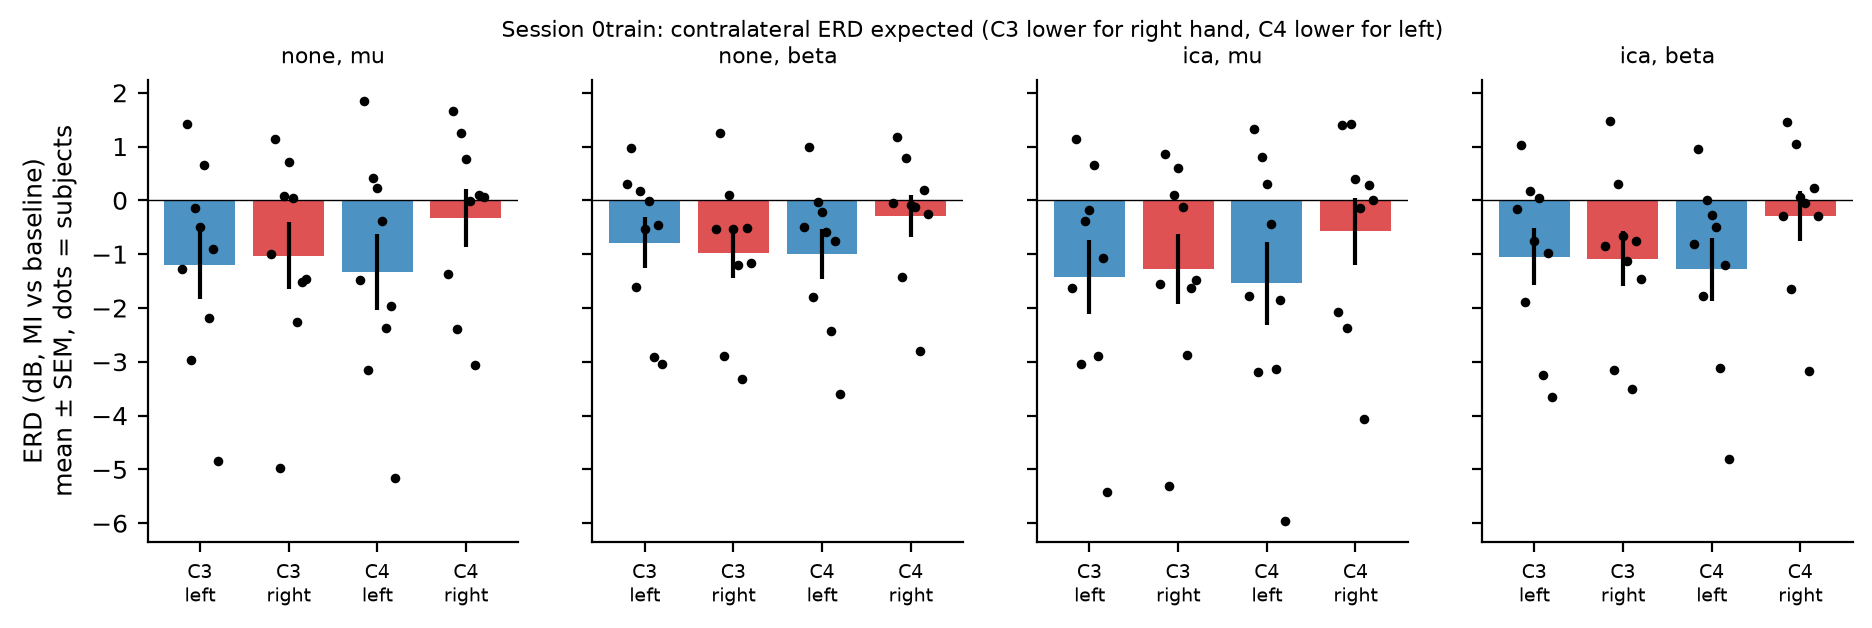

results/figures/fig_4b_erd_topomap.png


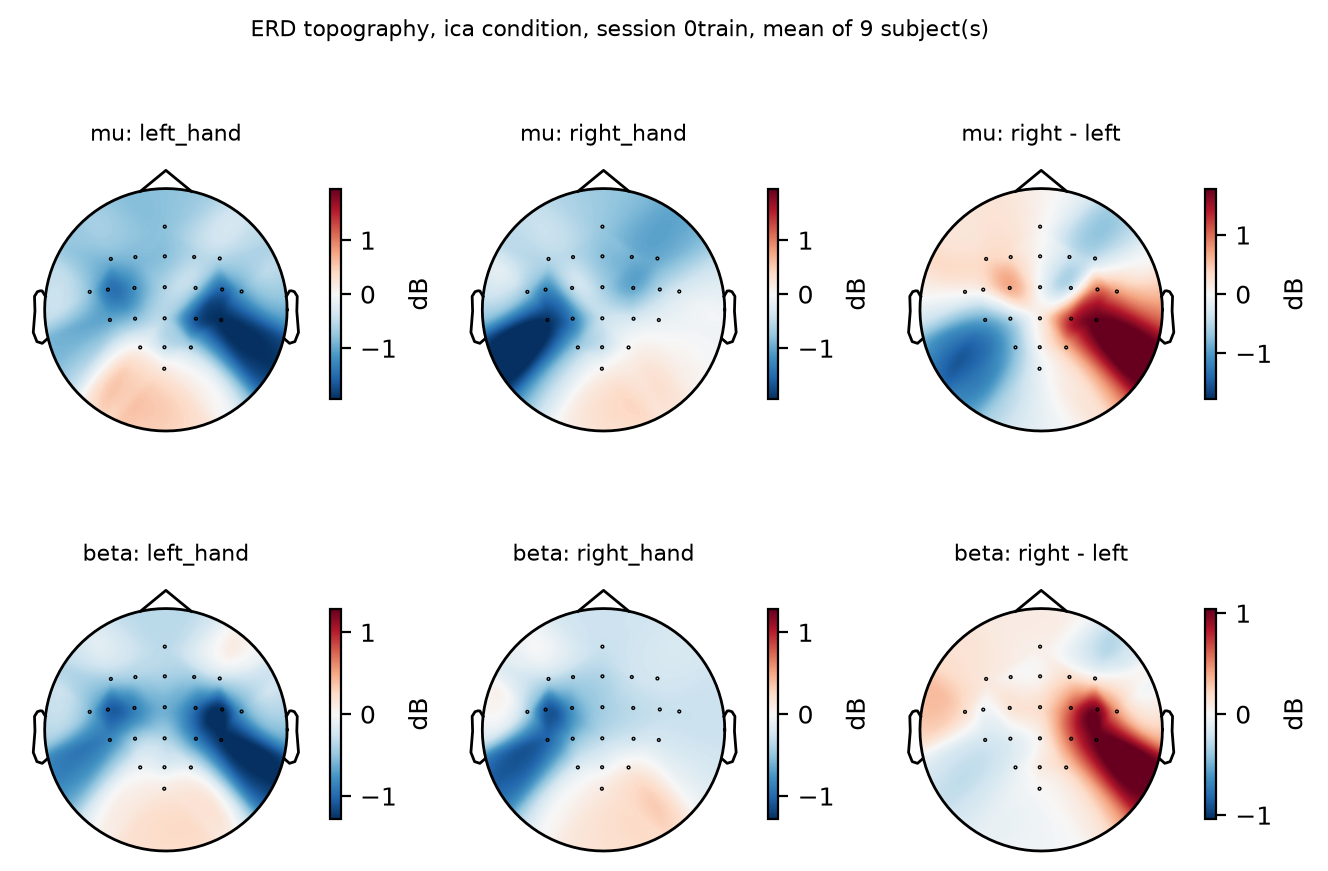

results/figures/fig_4c_eog_evoked_by_class.png


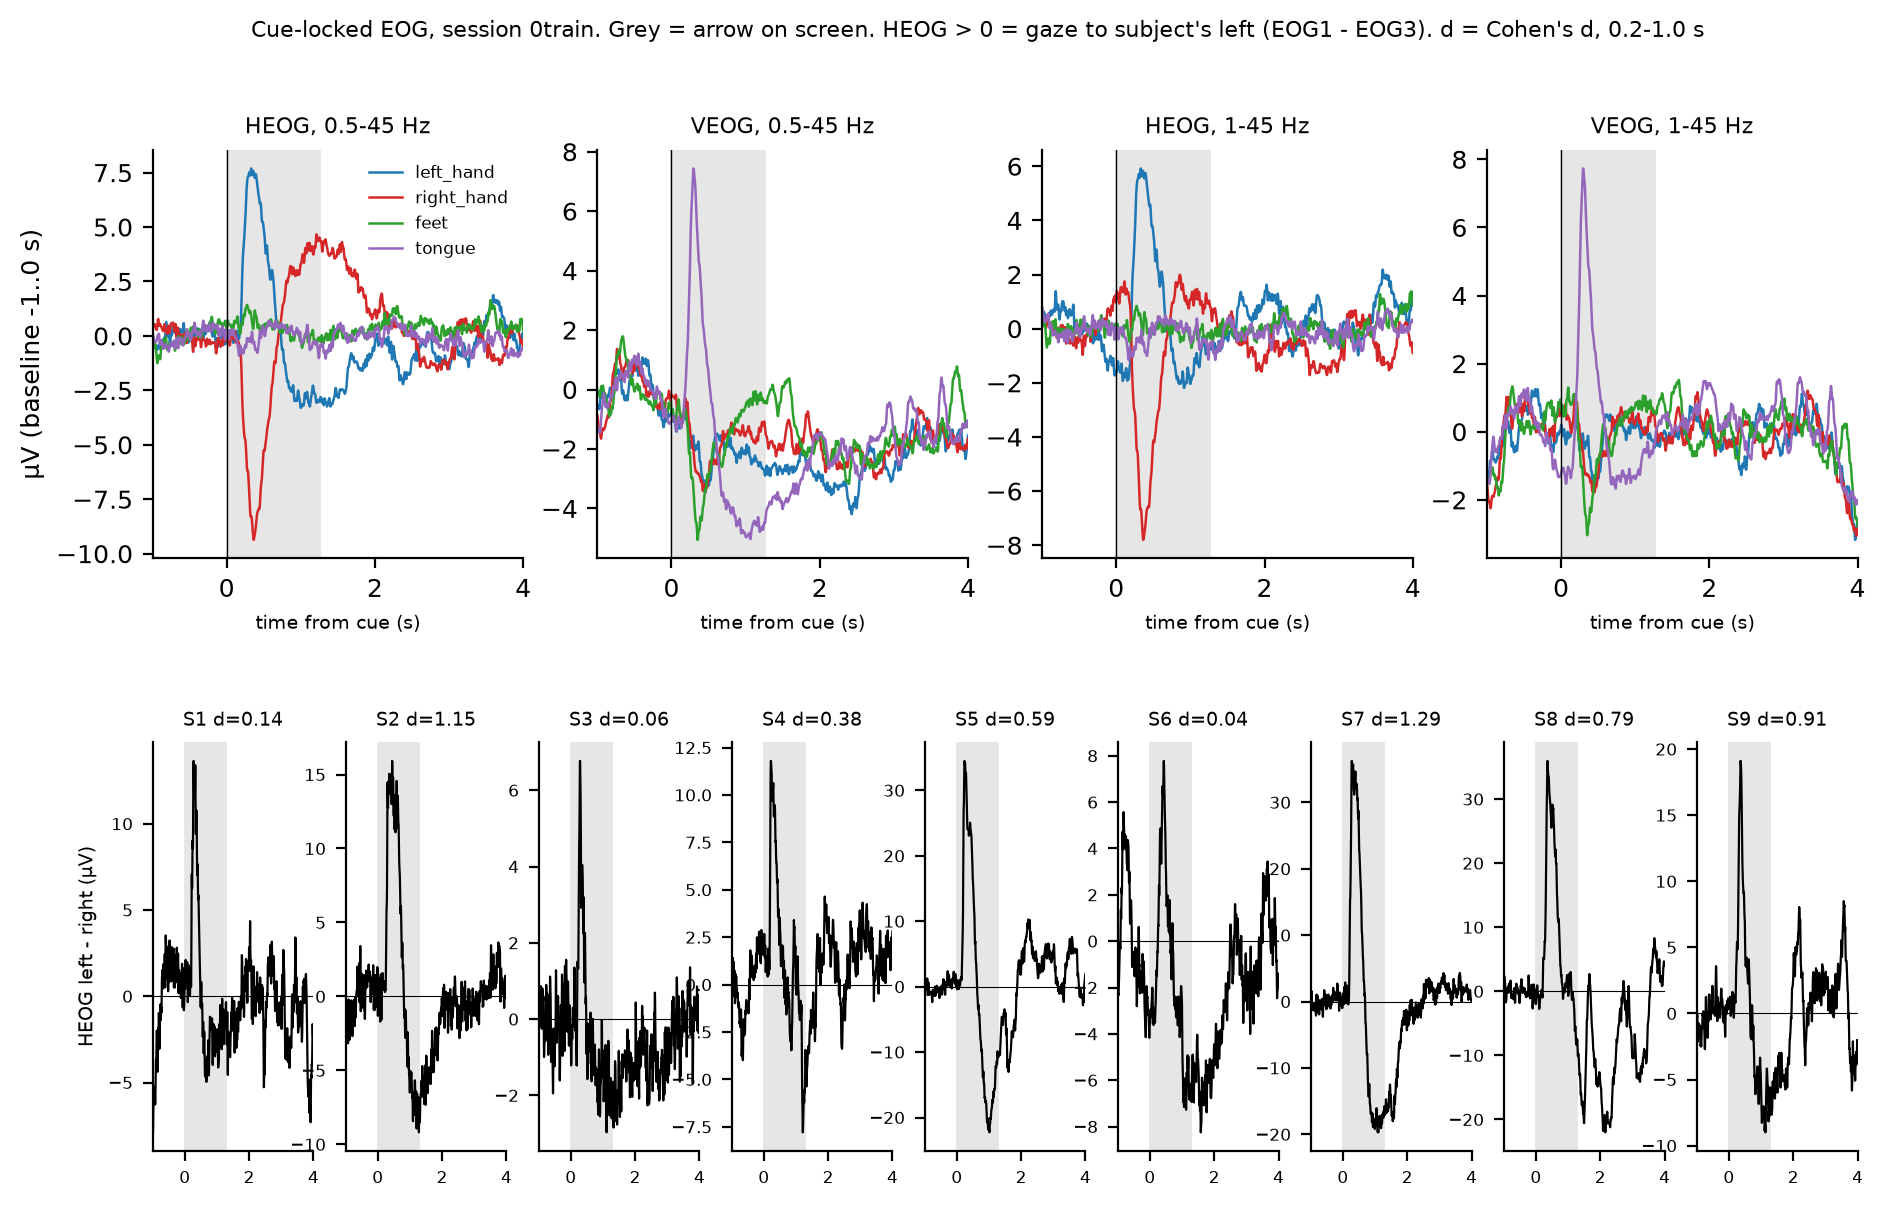

results/figures/fig_4d_frontal_eeg_evoked_before_after_cleaning.png


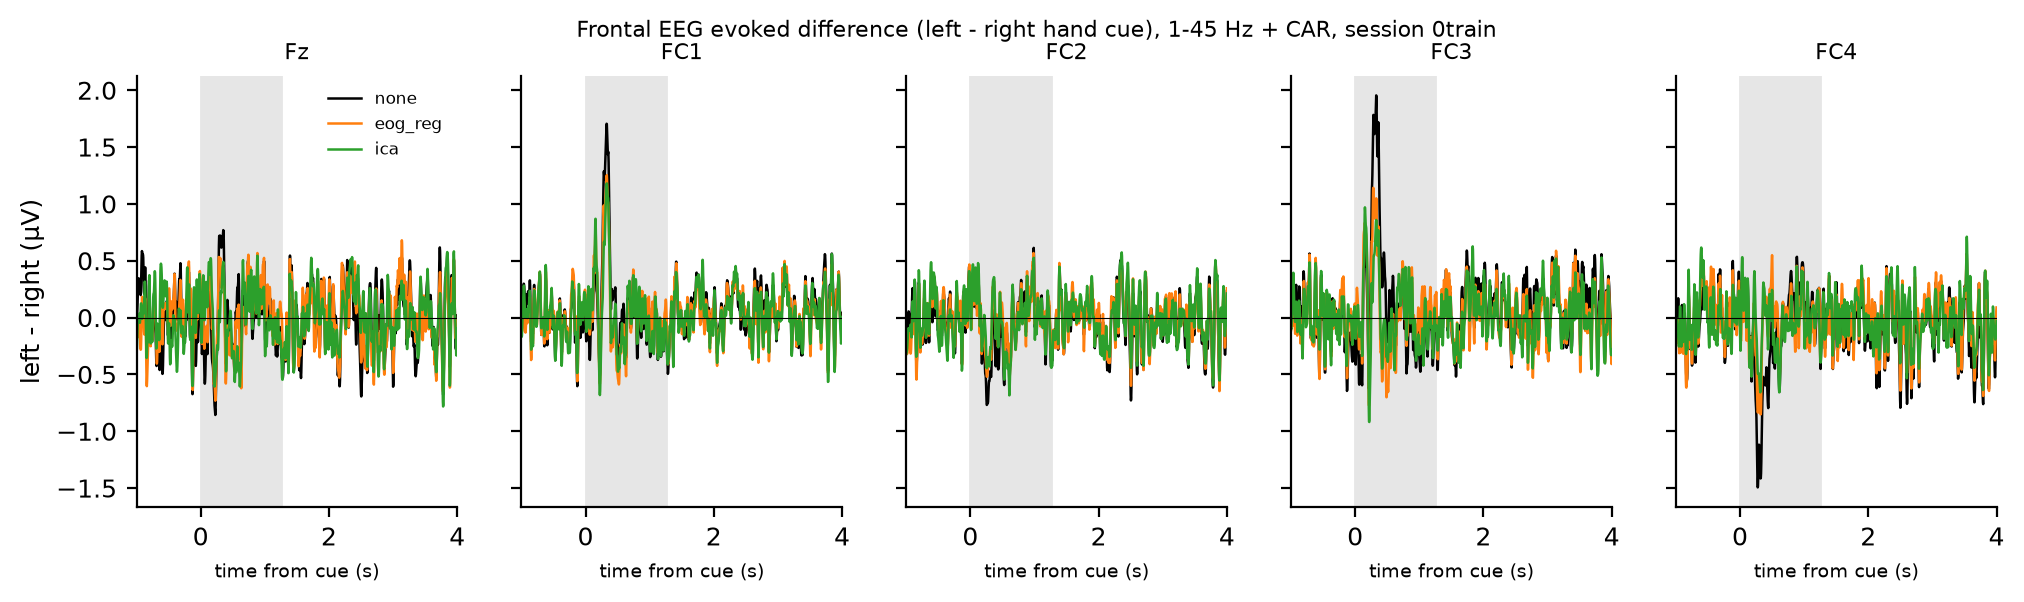

results/figures/fig_4e_psd_c3c4_by_class.png


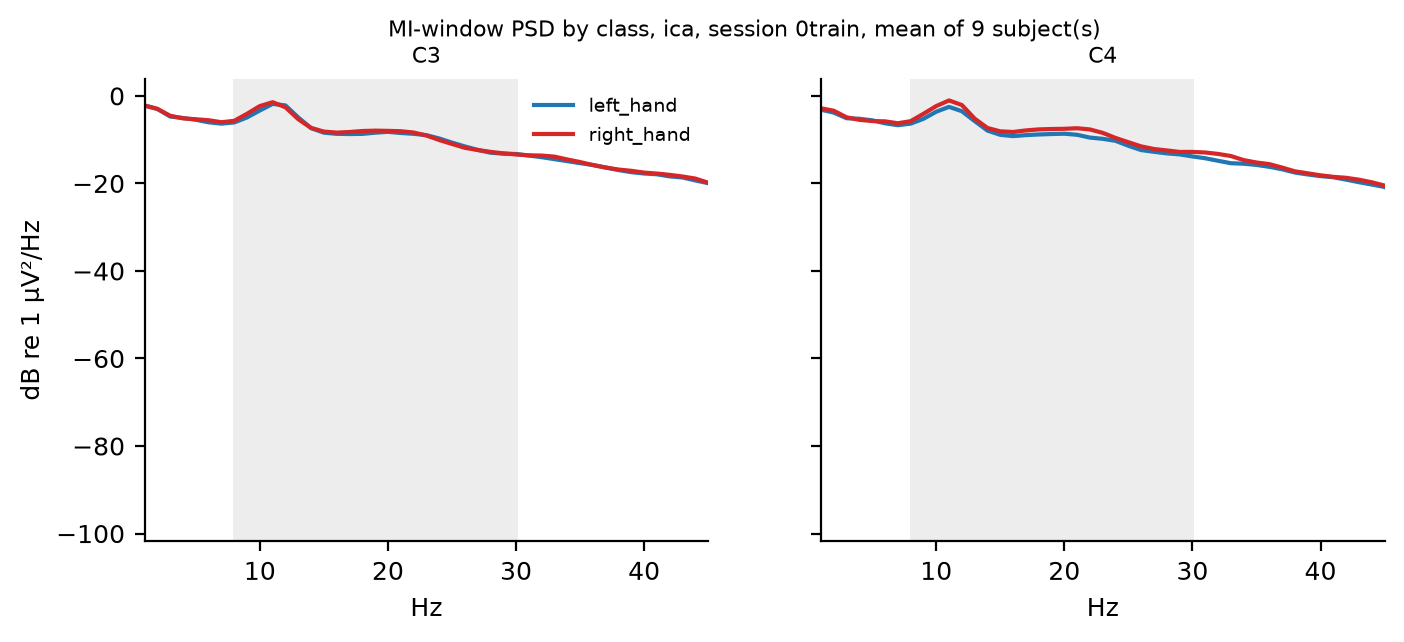

In [20]:
from IPython.display import Image, display
import glob
for f in sorted(glob.glob('results/figures/fig_4*.png')):
    print(f); display(Image(f, width=900))

## Stages 5-6 - Features, classifiers and honest evaluation

Stages 5-6 - features, classifiers, honest evaluation over the full condition grid.

task x cleaning x feature_set x classifier, leave-one-run-out CV within session, permutation
chance for every row, cross-session transfer, nested-C check, expert-artifact sensitivity,
4-class confusion matrices. Writes auc_*.csv / decode_*.csv and fig_6a/6b.

In [21]:
from __future__ import annotations



import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_val_predict

import config
from src import decode, features, plots
from src.timing import timed

print(f"MODE={config.MODE} subjects={config.CFG['subjects']} perms={config.CFG['n_permutations']}/"
      f"{config.CFG['n_permutations_other']} n_jobs={config.N_JOBS}")


def grid() -> list[tuple[str, str]]:
    """(cleaning, feature_set) pairs. EOG channels are never cleaned -> eog_only only with none."""
    return [("none", "eog_only")] + [(c, f) for f in config.FEATURE_SETS[1:] for c in config.CONDITIONS]


def n_perm(task: str, fs: str) -> int:
    """Permutations: full count for the rows the H1 decision rule uses, reduced elsewhere."""
    h1_row = task == "left_vs_right" and fs == "eog_only"
    return config.CFG["n_permutations"] if h1_row else config.CFG["n_permutations_other"]


rows, xs_rows, nested_rows, sens_rows, expl_rows = [], [], [], [], []
cm_sum: dict[tuple, np.ndarray] = {}
with timed("05_decode_all_conditions"):
    feats = {(s, sess): features.ensure_recording(s, sess)
             for s in config.CFG["subjects"] for sess in config.CFG["sessions"]}
    for (s, sess), r in feats.items():
        for task in config.TASKS:
            idx, y, g = decode.task_data(r["label"], r["run"], task)
            for cleaning, fs in grid():
                X, _ = features.select(r[cleaning], fs)
                for clf in config.TASK_CLASSIFIERS[task]:
                    o = decode.evaluate(X[idx], y, g, task, clf, n_perm=n_perm(task, fs), n_jobs=config.N_JOBS)
                    rows.append({"subject": s, "session": sess, "task": task, "cleaning": cleaning,
                                 "feature_set": fs, "classifier": clf, "n_features": X.shape[1],
                                 "n_permutations": n_perm(task, fs), **o,
                                 "chance_p95": o["auc_chance_p95"],
                                 "binomial_acc_p95": decode.binomial_chance(len(y), len(np.unique(y)))})
                if task == "four_class" and sess == config.CFG["sessions"][0]:
                    pred = cross_val_predict(decode.make_pipeline("logreg"), X[idx], y, groups=g, cv=decode.cv_splitter())
                    cm_sum[(cleaning, fs)] = cm_sum.get((cleaning, fs), 0) + confusion_matrix(y, pred, labels=range(4))
                if task == "left_vs_right" and sess == config.CFG["sessions"][0] and fs == "eeg_all":
                    nested_rows.append({"subject": s, "session": sess, "cleaning": cleaning, "feature_set": fs,
                                        **decode.nested_C(X[idx], y, g, task)})
                if task == "left_vs_right" and sess == config.CFG["sessions"][0]:
                    # sensitivity: drop expert-flagged artifact trials (Phase 3 note)
                    idx2, y2, g2 = decode.task_data(r["label"], r["run"], task, mask=r["expert_artifact"] == 0)
                    o2 = decode.evaluate(X[idx2], y2, g2, task, "logreg", n_perm=n_perm(task, fs), n_jobs=config.N_JOBS)
                    sens_rows.append({"subject": s, "session": sess, "task": task, "cleaning": cleaning,
                                      "feature_set": fs, "classifier": "logreg", **o2,
                                      "chance_p95": o2["auc_chance_p95"]})
        # EXPLORATORY (not pre-registered): time-domain features on frontal EEG, left vs right
        idx, y, g = decode.task_data(r["label"], r["run"], "left_vs_right")
        for cleaning in config.CONDITIONS:
            X, _ = features.select(r[cleaning], "eeg_frontal_amp")
            o = decode.evaluate(X[idx], y, g, "left_vs_right", "logreg",
                                n_perm=config.CFG["n_permutations_other"], n_jobs=config.N_JOBS)
            expl_rows.append({"subject": s, "session": sess, "task": "left_vs_right", "cleaning": cleaning,
                              "feature_set": "eeg_frontal_amp", "classifier": "logreg", "n_features": X.shape[1], **o,
                              "chance_p95": o["auc_chance_p95"]})
        print(f"S{s} {sess} done", flush=True)

    # cross-session: train 0train -> test 1test
    if {"0train", "1test"} <= set(config.CFG["sessions"]):
        for s in config.CFG["subjects"]:
            a, b = feats[(s, "0train")], feats[(s, "1test")]
            for task in config.TASKS:
                ia, ya, _ = decode.task_data(a["label"], a["run"], task)
                ib, yb, _ = decode.task_data(b["label"], b["run"], task)
                for cleaning, fs in grid():
                    Xa, _ = features.select(a[cleaning], fs)
                    Xb, _ = features.select(b[cleaning], fs)
                    for clf in config.TASK_CLASSIFIERS[task]:
                        o = decode.cross_session(Xa[ia], ya, Xb[ib], yb, task, clf, n_perm=n_perm(task, fs))
                        xs_rows.append({"subject": s, "task": task, "cleaning": cleaning, "feature_set": fs,
                                        "classifier": clf, **o})

    df = pd.DataFrame(rows)
    df.to_csv(config.TABLES / "auc_per_subject.csv", index=False)
    pd.DataFrame(xs_rows).to_csv(config.TABLES / "auc_cross_session.csv", index=False)
    pd.DataFrame(nested_rows).to_csv(config.TABLES / "decode_nested_C.csv", index=False)
    pd.DataFrame(sens_rows).to_csv(config.TABLES / "auc_expert_artifacts_excluded.csv", index=False)
    pd.DataFrame(expl_rows).to_csv(config.TABLES / "auc_exploratory_frontal_amp.csv", index=False)
    cm_rows = [{"cleaning": c, "feature_set": f, "true": config.CLASSES_4[i], **{f"pred_{config.CLASSES_4[j]}": int(m[i, j]) for j in range(4)}}
               for (c, f), m in cm_sum.items() for i in range(4)]
    pd.DataFrame(cm_rows).to_csv(config.TABLES / "decode_confusion_4class.csv", index=False)

    summ = (df.query("task == 'left_vs_right' and classifier == 'logreg'")
            .assign(above=lambda d: d.auc_mean > d.chance_p95)
            .groupby(["session", "feature_set", "cleaning"])
            .agg(auc_median=("auc_mean", "median"), n_above_p95=("above", "sum"), n=("above", "size")))
    print(summ.round(3).to_string())
    nC = pd.DataFrame(nested_rows)
    if len(nC):
        print("nested-C vs fixed C=1 (left vs right, logreg):")
        m = nC.merge(df.query("task=='left_vs_right' and classifier=='logreg'")[["subject", "session", "cleaning", "feature_set", "auc_mean"]],
                     on=["subject", "session", "cleaning", "feature_set"])
        print("median |nested - fixed| AUC:", round(float((m.auc_nested_mean - m.auc_mean).abs().median()), 3),
              "| C chosen counts:", pd.Series(";".join(nC.C_chosen).split(";")).value_counts().to_dict())

    # fig_6a: per-subject AUC by cleaning, one panel per feature set (left vs right, logreg)
    sess0 = config.CFG["sessions"][0]
    d0 = df.query("task == 'left_vs_right' and classifier == 'logreg' and session == @sess0")
    subs = config.CFG["subjects"]
    fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
    cols = {"none": "k", "eog_reg": "C1", "ica": "C2"}
    for ax, fs in zip(axes, config.FEATURE_SETS):
        conds = ["none"] if fs == "eog_only" else config.CONDITIONS
        w = 0.8 / len(conds)
        for j, c in enumerate(conds):
            g = d0.query("feature_set == @fs and cleaning == @c").set_index("subject").reindex(subs)
            x = np.arange(len(subs)) + (j - (len(conds) - 1) / 2) * w
            ax.bar(x, g.auc_mean - 0.5, w, bottom=0.5, color=cols[c], label=c, yerr=g.auc_sd, error_kw={"lw": 0.5})
            ax.scatter(x, g.chance_p95, marker="_", color="C3", s=40, zorder=3, label="chance p95" if j == 0 else None)
        ax.axhline(0.5, color="k", lw=0.5); ax.set_title(fs, fontsize=9)
        ax.set_xticks(range(len(subs)), [f"S{s}" for s in subs], fontsize=7)
        ax.legend(fontsize=6, frameon=False)
    axes[0].set_ylabel("ROC AUC, leave-one-run-out\nmean ± SD over folds")
    fig.suptitle(f"Left vs right hand, logistic regression, session {sess0}", fontsize=9)
    plots.save(fig, "fig_6a_auc_per_subject_by_condition")

    # fig_6b: 4-class confusion matrices summed over subjects (row-normalised)
    keys = [("none", "eog_only"), ("none", "eeg_all"), ("ica", "eeg_all"), ("ica", "eeg_physio")]
    fig, axes = plt.subplots(1, 4, figsize=(13, 3.3))
    for ax, k in zip(axes, keys):
        m = cm_sum[k] / cm_sum[k].sum(1, keepdims=True)
        ax.imshow(m, vmin=0, vmax=1, cmap=plots.CMAP_SEQ)
        for i in range(4):
            for j in range(4):
                ax.text(j, i, f"{m[i, j]:.2f}", ha="center", va="center", fontsize=7, color="w" if m[i, j] < 0.5 else "k")
        ax.set_xticks(range(4), [c.split("_")[0] for c in config.CLASSES_4], fontsize=7)
        ax.set_yticks(range(4), [c.split("_")[0] for c in config.CLASSES_4], fontsize=7)
        ax.set_title(f"{k[1]} / {k[0]}", fontsize=8); ax.set_xlabel("predicted", fontsize=7)
    axes[0].set_ylabel("true", fontsize=7)
    fig.suptitle(f"4-class, logistic regression, leave-one-run-out, session {sess0}, summed over {len(subs)} subject(s)", fontsize=8)
    plots.save(fig, "fig_6b_confusion_4class")


MODE=FULL subjects=[1, 2, 3, 4, 5, 6, 7, 8, 9] perms=100/30 n_jobs=-1


S1 0train done


S1 1test done


S2 0train done


S2 1test done


S3 0train done


... (11 outputs left out)

S9 0train done


S9 1test done


                                     auc_median  n_above_p95  n
session feature_set        cleaning                            
0train  eeg_all            eog_reg        0.834            8  9
                           ica            0.802            8  9
                           none           0.851            8  9
        eeg_artifact_prone eog_reg        0.579            3  9
                           ica            0.559            3  9
                           none           0.574            3  9
        eeg_physio         eog_reg        0.765            8  9
                           ica            0.772            8  9
                           none           0.770            8  9
        eog_only           none           0.859            8  9
1test   eeg_all            eog_reg        0.828            7  9
                           ica            0.887            8  9
                           none           0.859            8  9
        eeg_artifact_prone eog_reg      

[timing] 05_decode_all_conditions: 189.0 s


results/figures/fig_6a_auc_per_subject_by_condition.png


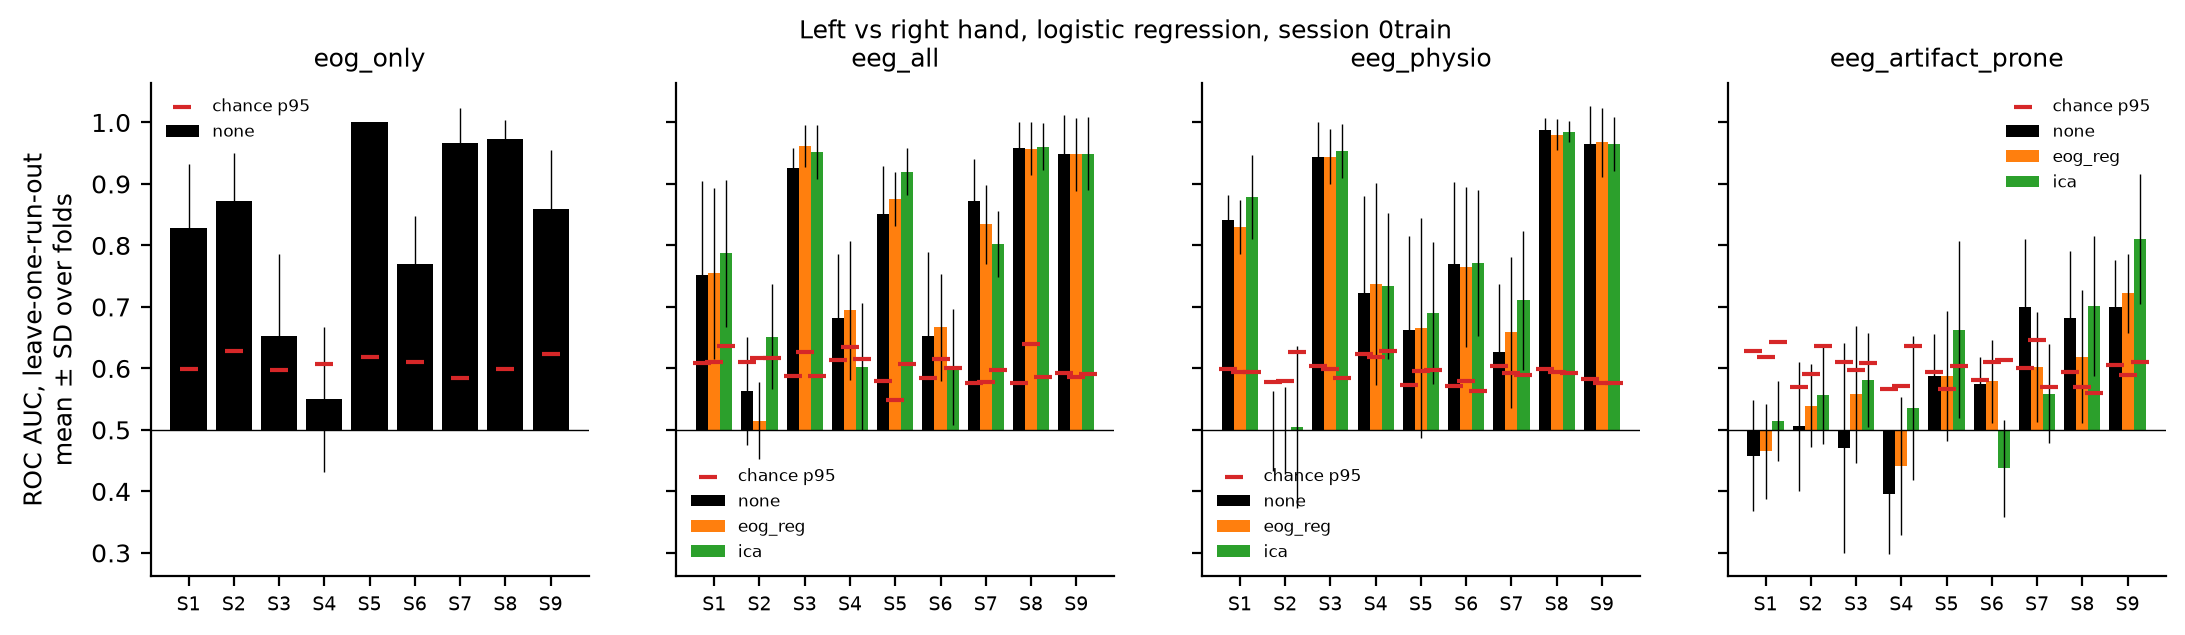

results/figures/fig_6b_confusion_4class.png


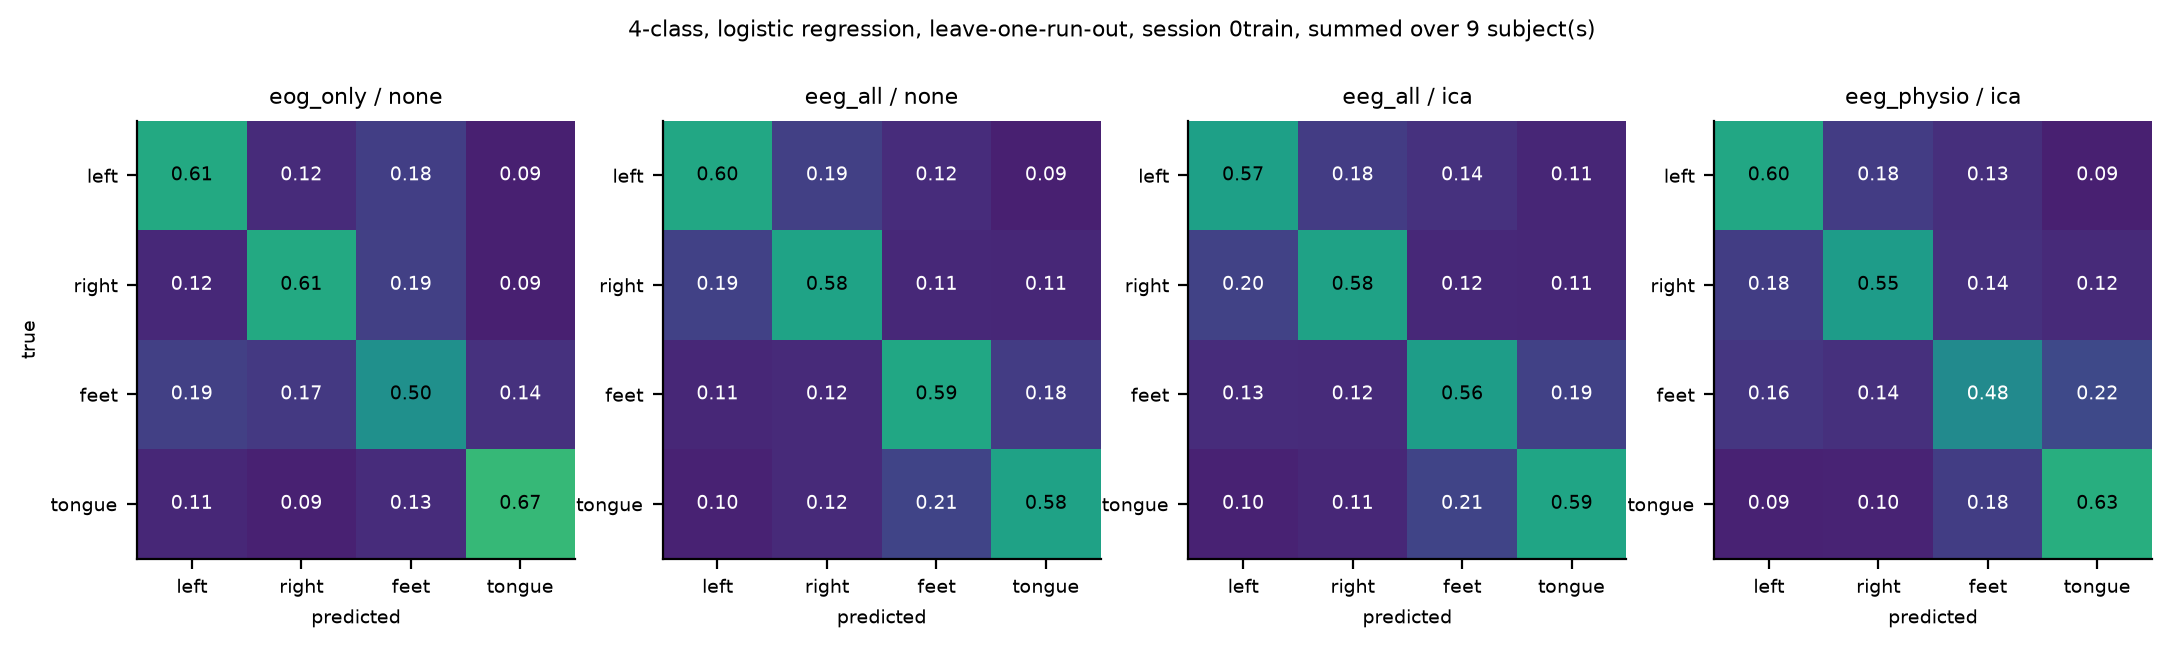

In [22]:
from IPython.display import Image, display
import glob
for f in sorted(glob.glob('results/figures/fig_6*.png')):
    print(f); display(Image(f, width=900))

## Stage 7 - Hypothesis tests

Stage 7 - pre-registered hypothesis tests H1-H3, robustness, figures fig_7a-7d.

In [23]:
from __future__ import annotations



import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd

import config
from src import decode, features, plots
from src import stats as st
from src.timing import timed

mne.set_log_level("ERROR")
auc = pd.read_csv(config.TABLES / "auc_per_subject.csv")
SESS0 = config.CFG["sessions"][0]
subs = config.CFG["subjects"]
BANDS = list(config.BANDS)


def h1(df: pd.DataFrame, session: str, clf: str, label: str) -> dict:
    """H1: EOG-only decodes left vs right. Wilcoxon(AUC - 0.5 > 0) and count above own p95."""
    q = df.query("task == 'left_vs_right' and feature_set == 'eog_only' and cleaning == 'none' "
                 "and session == @session and classifier == @clf").sort_values("subject")
    w = st.wilcoxon_greater(q.auc_mean.to_numpy(), 0.5)
    n_above = int((q.auc_mean > q.chance_p95).sum())
    return {"analysis": label, "session": session, "classifier": clf, "test": "wilcoxon AUC-0.5 > 0",
            **w, "n_above_own_p95": n_above,
            "supported": bool(w["p"] < 0.05 and n_above >= 5)}


def h2(df: pd.DataFrame, session: str, clf: str, label: str) -> list[dict]:
    """H2: cleaning lowers eeg_all AUC, and the drop tracks EOG-only AUC."""
    base = df.query("task == 'left_vs_right' and session == @session and classifier == @clf")
    eog = st.pick(base, feature_set="eog_only", cleaning="none")
    none = st.pick(base, feature_set="eeg_all", cleaning="none")
    out = []
    for c in ("eog_reg", "ica"):
        cl = st.pick(base, feature_set="eeg_all", cleaning=c)
        drop = none - cl
        w = st.wilcoxon_greater(none.to_numpy(), cl.to_numpy())
        sp = st.spearman(eog.to_numpy(), drop.to_numpy())
        out.append({"analysis": label, "session": session, "classifier": clf, "comparison": f"none vs {c}",
                    "test": "wilcoxon none > cleaned (eeg_all)", **w,
                    "spearman_rho_eogAUC_drop": sp["rho"], "spearman_p": sp["p_two_sided"]})
    adj = st.holm([o["p"] for o in out])
    for o, a in zip(out, adj):
        o["p_holm"] = a
        o["supported"] = bool(o["p"] < 0.05 and o["spearman_rho_eogAUC_drop"] > 0)
    return out


def weight_maps(session: str) -> pd.DataFrame:
    """Refit eeg_all logreg on ALL left/right trials of a session (visualisation only, flagged),
    per subject x cleaning. |coef| on standardised features, normalised to sum 1."""
    rows = []
    for s in subs:
        r = features.load_recording(s, session)
        idx, y, _ = decode.task_data(r["label"], r["run"], "left_vs_right")
        for c in config.CONDITIONS:
            X, names = features.select(r[c], "eeg_all")
            m = decode.make_pipeline("logreg").fit(X[idx], y)   # NOT an evaluation: full-session refit
            w = np.abs(m.named_steps["clf"].coef_.ravel())
            w = w / w.sum()
            for n, v in zip(names, w):
                ch, b = n.split(":")
                rows.append({"subject": s, "session": session, "cleaning": c, "channel": ch, "band": b, "abs_coef_norm": v})
    return pd.DataFrame(rows)


with timed("06_stats"):
    # ---------------- H1
    h1_rows = [h1(auc, SESS0, "logreg", "primary")]
    pd.DataFrame(h1_rows).to_csv(config.TABLES / "stats_h1.csv", index=False)

    # ---------------- H2
    h2_rows = h2(auc, SESS0, "logreg", "primary")
    pd.DataFrame(h2_rows).to_csv(config.TABLES / "stats_h2.csv", index=False)

    # ---------------- H3
    base = auc.query("task == 'left_vs_right' and session == @SESS0 and classifier == 'logreg'")
    drops = {fs: st.pick(base, feature_set=fs, cleaning="none") - st.pick(base, feature_set=fs, cleaning="ica")
             for fs in ("eeg_physio", "eeg_artifact_prone", "eeg_all")}
    wm = weight_maps(SESS0)
    wm.to_csv(config.TABLES / "weights_eeg_all_fullsession_refit.csv", index=False)
    share = (wm.assign(central=wm.channel.isin(config.CENTRAL_CHANNELS),
                       mubeta=wm.band.isin(["mu", "beta"]),
                       central_mubeta=wm.channel.isin(config.CENTRAL_CHANNELS) & wm.band.isin(["mu", "beta"]))
             .groupby(["subject", "cleaning"])
             .apply(lambda g: pd.Series({k: g.loc[g[k], "abs_coef_norm"].sum() for k in ("central", "mubeta", "central_mubeta")}),
                    include_groups=False).reset_index())
    share.to_csv(config.TABLES / "weights_share.csv", index=False)
    sp = share.pivot(index="subject", columns="cleaning")
    h3_rows = []
    w = st.wilcoxon_greater(drops["eeg_artifact_prone"].to_numpy(), drops["eeg_physio"].to_numpy())
    h3_rows.append({"analysis": "primary", "session": SESS0, "test": "wilcoxon drop(artifact_prone) > drop(physio), none->ica",
                    **w, "median_drop_physio": float(drops["eeg_physio"].median()),
                    "median_drop_artifact_prone": float(drops["eeg_artifact_prone"].median())})
    for k in ("central", "mubeta", "central_mubeta"):
        w = st.wilcoxon_greater(sp[(k, "ica")].to_numpy(), sp[(k, "none")].to_numpy())
        h3_rows.append({"analysis": "primary", "session": SESS0, "test": f"wilcoxon weight share {k}: ica > none", **w,
                        "median_share_none": float(sp[(k, "none")].median()), "median_share_ica": float(sp[(k, "ica")].median())})
    h3 = pd.DataFrame(h3_rows)
    supported = bool(h3.loc[0, "p"] < 0.05 and h3.loc[1, "delta_median"] > 0)
    h3["H3_supported"] = supported
    h3.to_csv(config.TABLES / "stats_h3.csv", index=False)

    # ---------------- robustness (supplementary)
    rob = []
    sess_list = config.CFG["sessions"]
    for sess in sess_list:
        for clf in config.CLASSIFIERS:
            if sess == SESS0 and clf == "logreg":
                continue
            rob.append({"hypothesis": "H1", **h1(auc, sess, clf, f"{sess}/{clf}")})
            rob += [{"hypothesis": "H2", **r} for r in h2(auc, sess, clf, f"{sess}/{clf}")]
    sens = config.TABLES / "auc_expert_artifacts_excluded.csv"
    if sens.exists():
        se = pd.read_csv(sens)
        rob.append({"hypothesis": "H1", **h1(se, SESS0, "logreg", "expert artifacts excluded")})
        rob += [{"hypothesis": "H2", **r} for r in h2(se, SESS0, "logreg", "expert artifacts excluded")]
    xs = config.TABLES / "auc_cross_session.csv"
    if xs.exists() and len(pd.read_csv(xs)):
        x = pd.read_csv(xs).rename(columns={"auc": "auc_mean", "auc_chance_p95": "chance_p95"}).assign(session="cross")
        rob.append({"hypothesis": "H1", **h1(x, "cross", "logreg", "cross-session 0train->1test")})
        rob += [{"hypothesis": "H2", **r} for r in h2(x, "cross", "logreg", "cross-session 0train->1test")]
    pd.DataFrame(rob).to_csv(config.TABLES / "stats_robustness.csv", index=False)

    # ---------------- secondary: 4-class summary
    fc = auc.query("task == 'four_class' and classifier == 'logreg'")
    sec = (fc.assign(above=lambda d: d.bacc_mean > d.bacc_chance_p95)
             .groupby(["session", "feature_set", "cleaning"])
             .agg(bacc_median=("bacc_mean", "median"), auc_ovr_median=("auc_mean", "median"),
                  n_above_p95=("above", "sum"), n=("above", "size")).reset_index())
    sec.to_csv(config.TABLES / "stats_secondary_4class.csv", index=False)

    print(pd.DataFrame(h1_rows).round(4).T.to_string()); print(pd.DataFrame(h2_rows).round(4).T.to_string())
    print(h3.round(4).T.to_string()); print(sec.round(3).to_string(index=False))
    print(pd.DataFrame(rob)[["hypothesis", "analysis", "comparison", "p", "delta_median", "n_above_own_p95",
                             "spearman_rho_eogAUC_drop", "supported"]].round(3).to_string(index=False))

    # ---------------- figures
    q = auc.query("task == 'left_vs_right' and feature_set == 'eog_only' and session == @SESS0 and classifier == 'logreg'").sort_values("subject")
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.bar(np.arange(len(q)), q.auc_mean - 0.5, bottom=0.5, color="0.5", yerr=q.auc_sd, error_kw={"lw": 0.6})
    ax.scatter(np.arange(len(q)), q.chance_p95, marker="_", s=120, color="C3", label="own permutation null, 95th pct", zorder=3)
    ax.axhline(0.5, color="k", lw=0.5)
    ax.set_xticks(range(len(q)), [f"S{s}" for s in q.subject]); ax.set_ylabel("ROC AUC (EOG only)")
    r0 = h1_rows[0]
    ax.set_title(f"H1: EOG-only left vs right, {SESS0}. Wilcoxon p = {r0['p']:.3g}, "
                 f"{r0['n_above_own_p95']}/{len(q)} above own p95", fontsize=8)
    ax.legend(fontsize=7, frameon=False)
    plots.save(fig, "fig_7a_eog_only_auc_vs_null")

    fig, axes = plt.subplots(1, 2, figsize=(8, 3.2), sharey=True)
    eog = st.pick(base, feature_set="eog_only", cleaning="none")
    none = st.pick(base, feature_set="eeg_all", cleaning="none")
    for ax, c, r in zip(axes, ("eog_reg", "ica"), h2_rows):
        d = none - st.pick(base, feature_set="eeg_all", cleaning=c)
        ax.scatter(eog, d, color="k", s=14)
        for s_, xv, yv in zip(eog.index, eog, d):
            ax.annotate(f"S{s_}", (xv, yv), fontsize=6, xytext=(3, 2), textcoords="offset points")
        ax.axhline(0, color="k", lw=0.5)
        ax.set_xlabel("EOG-only AUC"); ax.set_title(f"none - {c}: Wilcoxon p = {r['p']:.3g}, rho = {r['spearman_rho_eogAUC_drop']:.2f}", fontsize=8)
    axes[0].set_ylabel("AUC drop of eeg_all after cleaning")
    plots.save(fig, "fig_7b_auc_drop_vs_eog_auc")

    ch_order = [c for c in features.load_recording(subs[0], SESS0)["none"]["ch_names"] if not c.startswith("EOG")]
    fig, axes = plt.subplots(2, 3, figsize=(11, 6.5), gridspec_kw={"height_ratios": [1.6, 1]})
    mats = {}
    for j, c in enumerate(("none", "ica")):
        m = wm.query("cleaning == @c").groupby(["channel", "band"]).abs_coef_norm.mean().unstack()[BANDS].reindex(ch_order)
        mats[c] = m
    mats["ica - none"] = mats["ica"] - mats["none"]
    for j, (k, m) in enumerate(mats.items()):
        ax = axes[0, j]
        v = np.abs(m.values).max()
        im = ax.imshow(m.values, aspect="auto", cmap=plots.CMAP_DIV if j == 2 else plots.CMAP_SEQ,
                       vmin=-v if j == 2 else 0, vmax=v)
        ax.set_xticks(range(len(BANDS)), BANDS, fontsize=7); ax.set_yticks(range(len(ch_order)), ch_order, fontsize=6)
        ax.set_title(f"mean normalised |coef|: {k}", fontsize=8); plt.colorbar(im, ax=ax, shrink=0.6)
    info = mne.create_info(ch_order, config.SFREQ, "eeg"); info.set_montage("standard_1005")
    for j, b in enumerate(("delta", "mu", "beta")):
        d = mats["ica - none"][b].to_numpy()
        im, _ = mne.viz.plot_topomap(d, info, axes=axes[1, j], show=False, cmap=plots.CMAP_DIV,
                                     vlim=(-np.abs(d).max(), np.abs(d).max()), contours=0)
        axes[1, j].set_title(f"{b}: ica - none", fontsize=8); plt.colorbar(im, ax=axes[1, j], shrink=0.6)
    fig.suptitle(f"eeg_all logistic-regression weights, full-session refit (visualisation only, not an evaluation), "
                 f"{SESS0}, mean of {len(subs)} subjects", fontsize=8)
    plots.save(fig, "fig_7c_feature_weights_before_after")

    fig, ax = plt.subplots(figsize=(5, 3.2))
    sets = ["eeg_physio", "eeg_artifact_prone", "eeg_all"]
    for i, fs in enumerate(sets):
        ax.scatter(np.full(len(drops[fs]), i) + np.linspace(-0.12, 0.12, len(drops[fs])), drops[fs], color="k", s=12)
        ax.hlines(drops[fs].median(), i - 0.25, i + 0.25, color="C3")
    for s_ in drops["eeg_physio"].index:
        ax.plot([0, 1], [drops["eeg_physio"][s_], drops["eeg_artifact_prone"][s_]], color="0.8", lw=0.6, zorder=0)
    ax.axhline(0, color="k", lw=0.5); ax.set_xticks(range(3), sets, fontsize=8)
    ax.set_ylabel("AUC drop, none - ica"); ax.set_title(f"H3a: Wilcoxon p = {h3.loc[0, 'p']:.3g} (red = median)", fontsize=8)
    plots.save(fig, "fig_7d_delta_auc_by_feature_set")

    # ---------------- EXPLORATORY (not pre-registered): frontal EEG time-domain features
    ex_path = config.TABLES / "auc_exploratory_frontal_amp.csv"
    if ex_path.exists():
        ex = pd.read_csv(ex_path)
        ex_rows = []
        for sess in config.CFG["sessions"]:
            e = ex.query("session == @sess")
            eogs = st.pick(auc.query("task == 'left_vs_right' and classifier == 'logreg' and session == @sess"),
                           feature_set="eog_only", cleaning="none")
            n0 = st.pick(e, cleaning="none")
            for c in ("eog_reg", "ica"):
                cl = st.pick(e, cleaning=c)
                w = st.wilcoxon_greater(n0.to_numpy(), cl.to_numpy())
                sp_ = st.spearman(eogs.to_numpy(), (n0 - cl).to_numpy())
                ex_rows.append({"analysis": "EXPLORATORY frontal amplitude (Fz, FC1-4, 0-1 s)", "session": sess,
                                "comparison": f"none vs {c}", **w,
                                "median_auc_none": float(n0.median()), "median_auc_cleaned": float(cl.median()),
                                "n_above_p95_none": int((e.query("cleaning == 'none'").auc_mean > e.query("cleaning == 'none'").chance_p95).sum()),
                                "n_above_p95_cleaned": int((e.query("cleaning == @c").auc_mean > e.query("cleaning == @c").chance_p95).sum()),
                                "spearman_rho_eogAUC_drop": sp_["rho"], "spearman_p": sp_["p_two_sided"]})
        exd = pd.DataFrame(ex_rows)
        exd["p_holm"] = st.holm(exd["p"].tolist())
        exd.to_csv(config.TABLES / "stats_exploratory.csv", index=False)
        print(exd.round(4).T.to_string())

        e0 = ex.query("session == @SESS0")
        fig, ax = plt.subplots(figsize=(5, 3.2))
        for i, c in enumerate(config.CONDITIONS):
            v = st.pick(e0, cleaning=c)
            ax.scatter(np.full(len(v), i) + np.linspace(-0.12, 0.12, len(v)), v, color="k", s=12)
            ax.hlines(v.median(), i - 0.25, i + 0.25, color="C3")
        for s_ in subs:
            ax.plot(range(3), [st.pick(e0, cleaning=c)[s_] for c in config.CONDITIONS], color="0.8", lw=0.6, zorder=0)
        ax.axhline(0.5, color="k", lw=0.5); ax.set_xticks(range(3), config.CONDITIONS)
        ax.set_ylabel("ROC AUC, left vs right")
        ax.set_title(f"EXPLORATORY: frontal EEG time-domain features (Fz, FC1-4), {SESS0}", fontsize=8)
        plots.save(fig, "fig_7e_exploratory_frontal_amplitude")


                                    0
analysis                      primary
session                        0train
classifier                     logreg
test             wilcoxon AUC-0.5 > 0
W                                45.0
p                               0.002
delta_median                   0.3588
delta_iqr_lo                   0.2697
delta_iqr_hi                   0.4664
delta_n                             9
n_above_own_p95                     8
supported                        True
                                                          0                                  1
analysis                                            primary                            primary
session                                              0train                             0train
classifier                                           logreg                             logreg
comparison                                  none vs eog_reg                        none vs ica
test                      wilco

                                                                         0                                                 1                                                 2                                                 3
analysis                  EXPLORATORY frontal amplitude (Fz, FC1-4, 0-1 s)  EXPLORATORY frontal amplitude (Fz, FC1-4, 0-1 s)  EXPLORATORY frontal amplitude (Fz, FC1-4, 0-1 s)  EXPLORATORY frontal amplitude (Fz, FC1-4, 0-1 s)
session                                                             0train                                            0train                                             1test                                             1test
comparison                                                 none vs eog_reg                                       none vs ica                                   none vs eog_reg                                       none vs ica
W                                                                     33.0                          

results/figures/fig_7a_eog_only_auc_vs_null.png


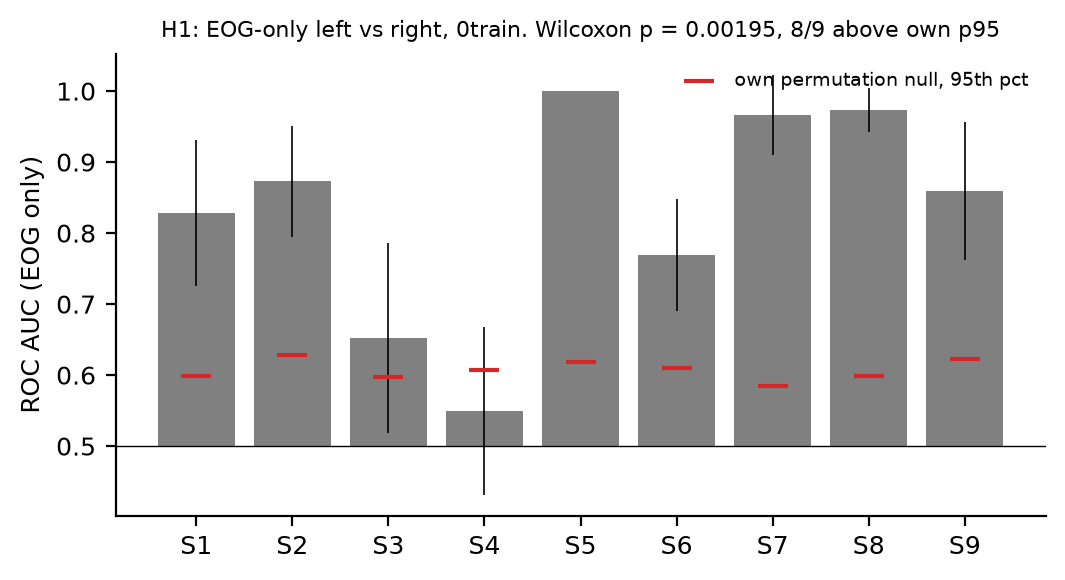

results/figures/fig_7b_auc_drop_vs_eog_auc.png


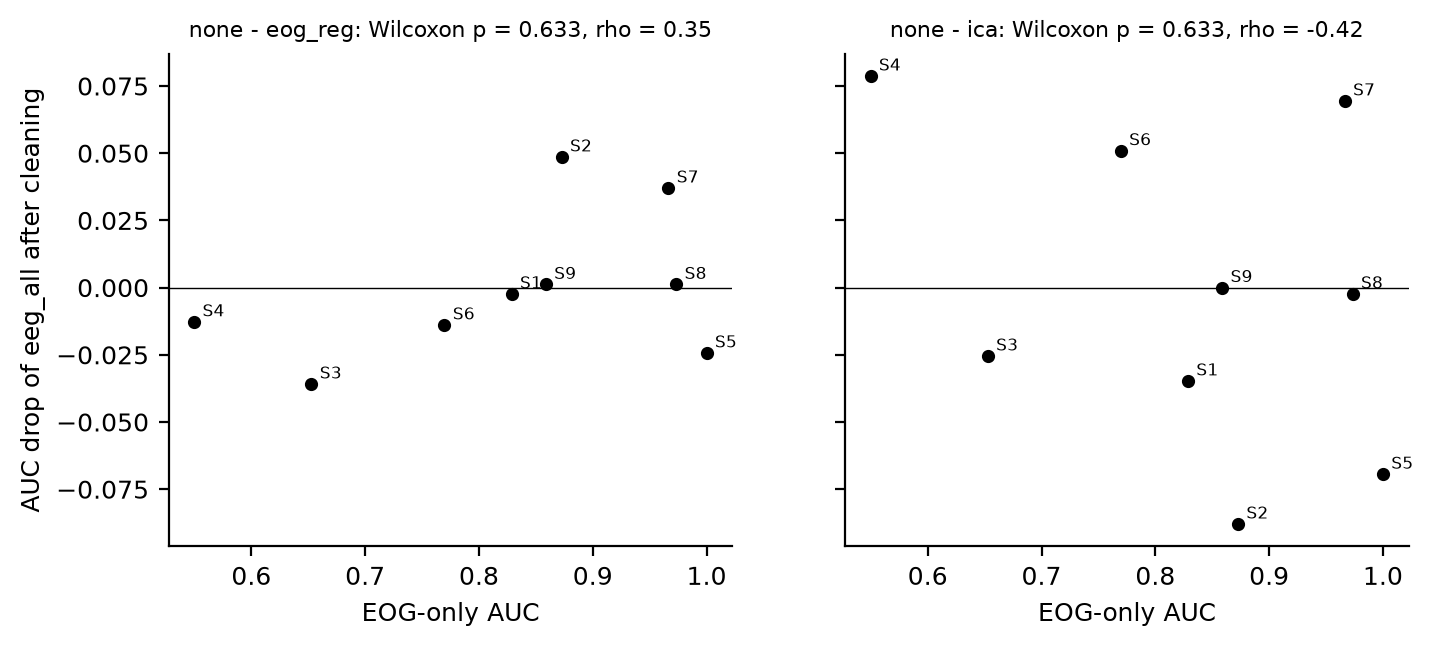

results/figures/fig_7c_feature_weights_before_after.png


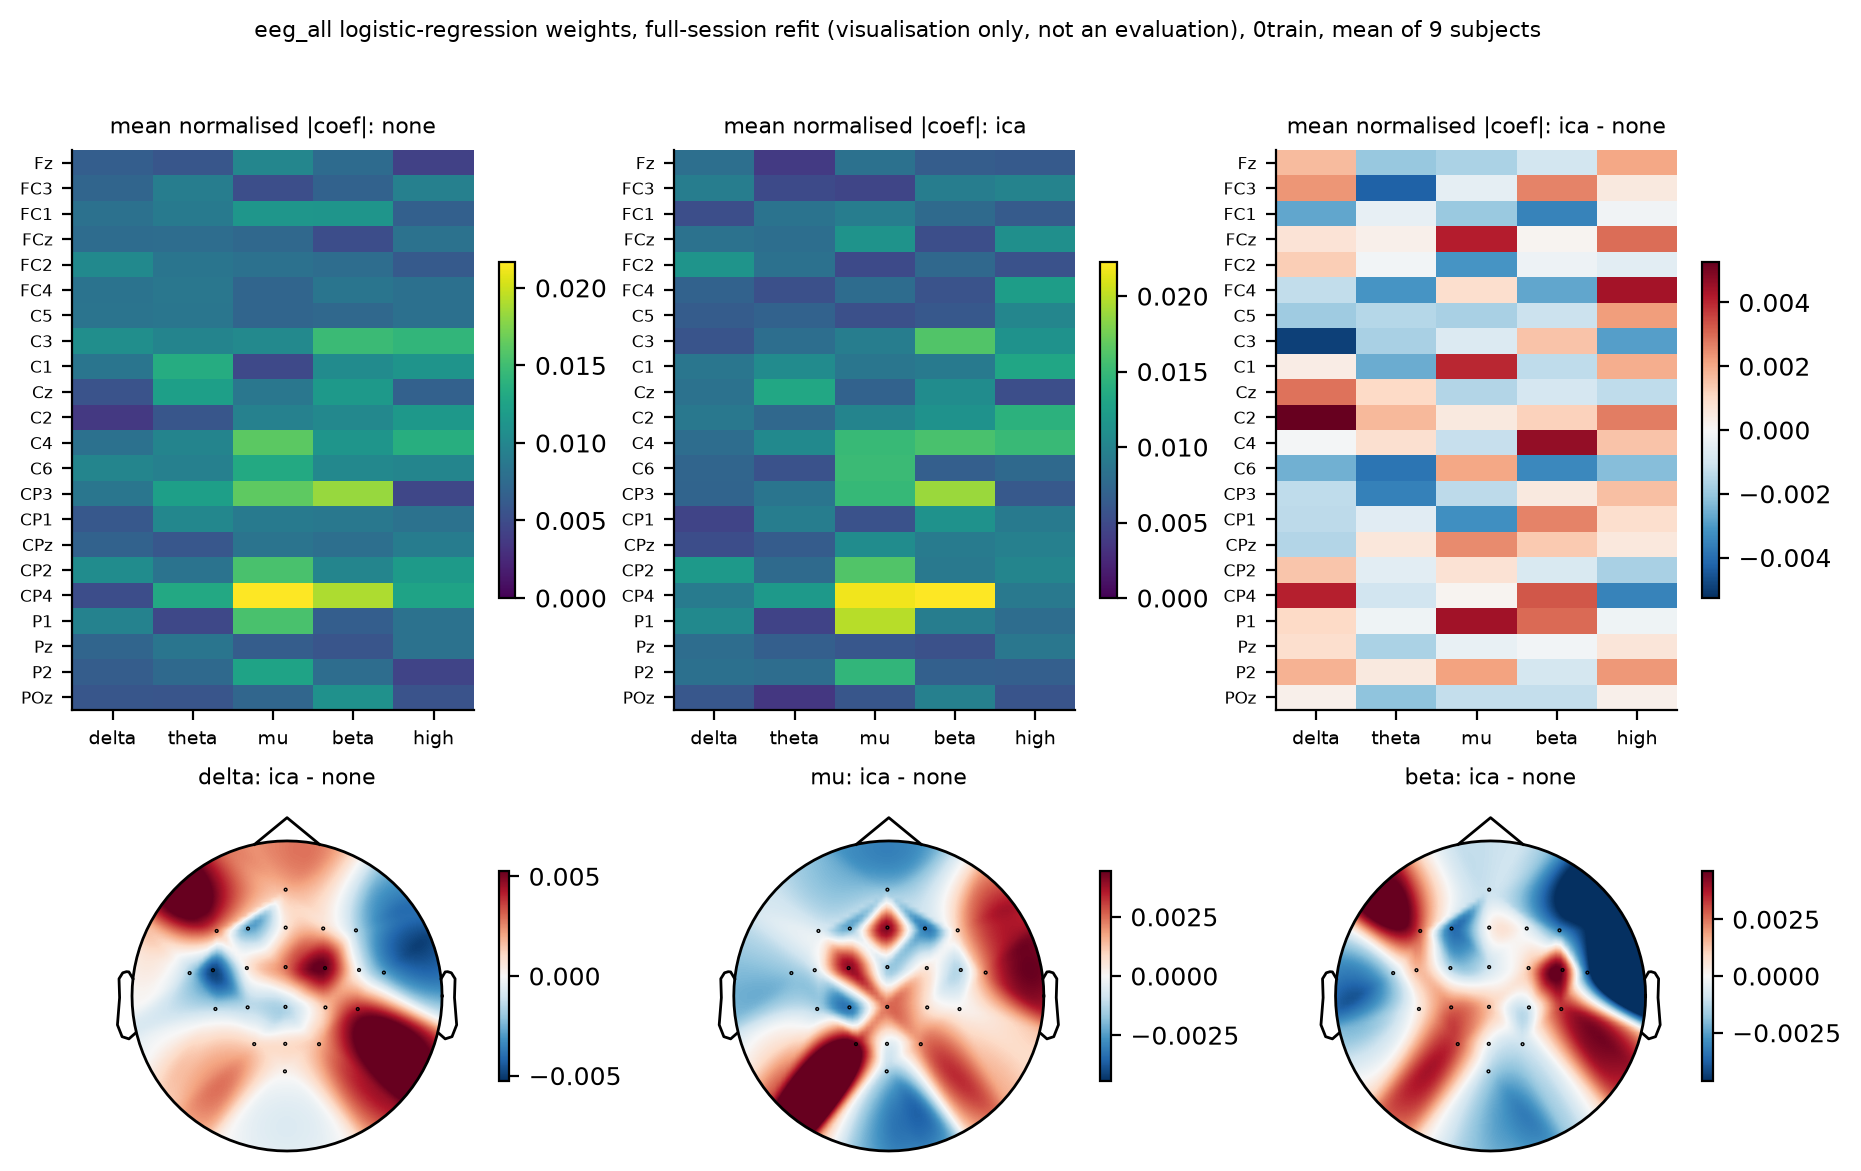

results/figures/fig_7d_delta_auc_by_feature_set.png


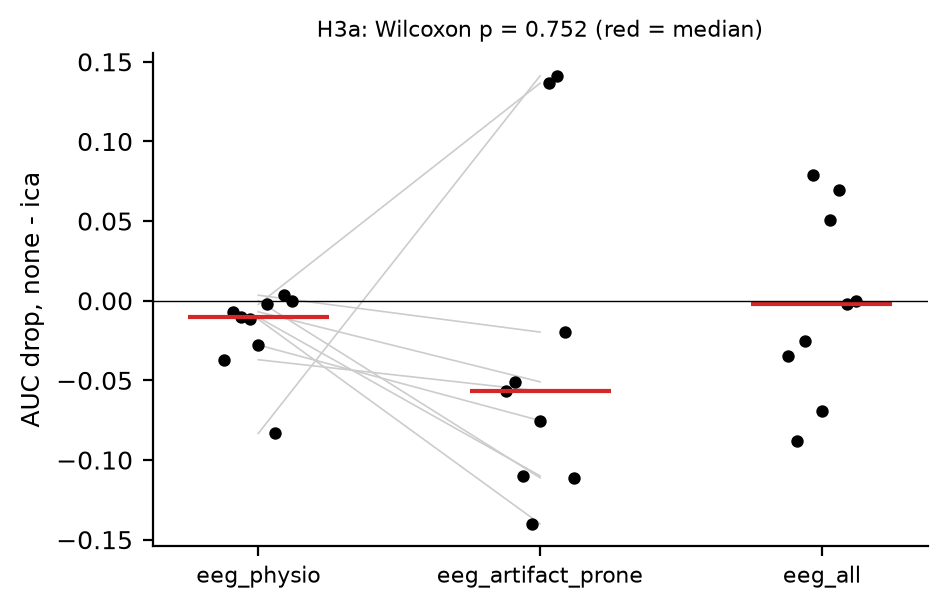

results/figures/fig_7e_exploratory_frontal_amplitude.png


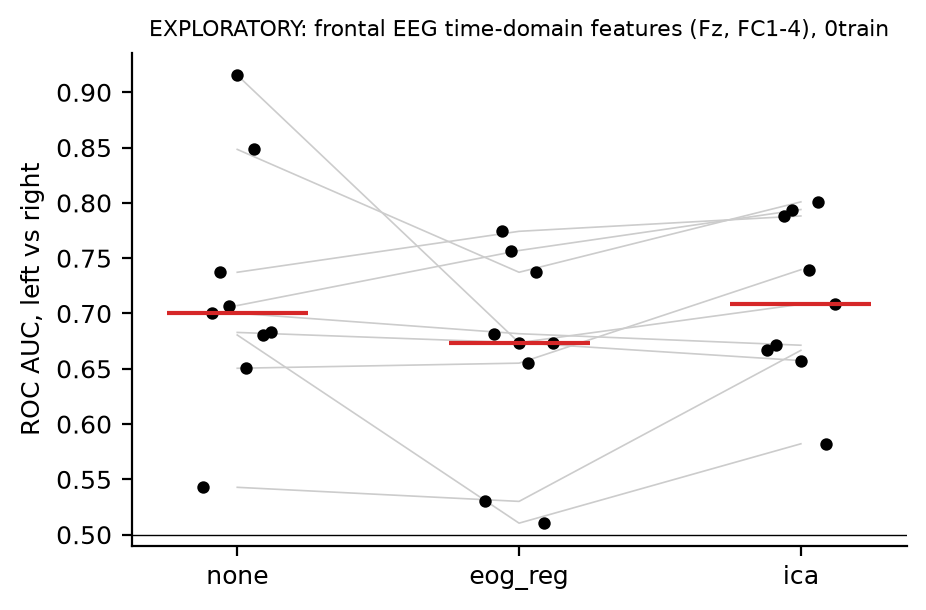

In [24]:
from IPython.display import Image, display
import glob
for f in sorted(glob.glob('results/figures/fig_7*.png')):
    print(f); display(Image(f, width=900))

## Reproducibility record

In [25]:
import importlib.metadata as md_, platform
print('python', platform.python_version())
print({p: md_.version(p) for p in ['mne', 'moabb', 'scikit-learn', 'numpy', 'scipy', 'pandas', 'matplotlib']})
print('subjects', config.CFG['subjects'], 'sessions', config.CFG['sessions'], 'seed', config.SEED)
import pandas as pd
print(pd.read_csv('results/timing.csv').tail(10).to_string(index=False))
print(f'total wall time {(time.time() - T_START) / 60:.1f} min')

python 3.13.2
{'mne': '1.13.2', 'moabb': '1.7.2', 'scikit-learn': '1.9.1', 'numpy': '2.5.4', 'scipy': '1.18.1', 'pandas': '3.1.0', 'matplotlib': '3.11.2'}
subjects [1, 2, 3, 4, 5, 6, 7, 8, 9] sessions ['0train', '1test'] seed 42
          timestamp mode                    stage  seconds
2026-10-27T16:45:24 FULL                 01_audit     35.9
2026-10-27T16:45:40 FULL     02_signal_inspection     16.2
2026-10-27T16:46:37 FULL             03_artifacts     57.5
2026-10-27T16:47:34 FULL       04_neurophys_check     56.0
2026-10-27T16:50:43 FULL 05_decode_all_conditions    189.0
2026-10-27T16:50:44 FULL                 06_stats      1.3
total wall time 6.0 min


In [26]:
import shutil
shutil.make_archive('robt613_results', 'zip', 'results')
print('results zipped -> robt613_results.zip')

results zipped -> robt613_results.zip
